# Time-Series Forecasting of Hourly Electricity Consumption

## 1. Introduction

Electricity consumption varies over time due to changes in usage patterns and recurring daily demand. Understanding these variations is important for estimating electricity requirements, planning energy usage and supporting effective energy management. Forecasting future consumption can help identify periods of higher demand and provide useful information for planning available resources.

The objective of this project is to analyse historical electricity consumption data and develop time-series forecasting models to predict hourly aggregate electricity consumption. The study uses the Electricity Load Diagrams 2011–2014 dataset, originally made available through the UCI Machine Learning Repository. The dataset contains electricity consumption measurements recorded in kilowatts (kW). For this project, the data was processed and aggregated into an hourly series representing 321 consumers. The target variable selected for forecasting is `aggregate_consumption_kW_prepared`.

The prepared dataset contains 26,304 hourly observations covering the period from 1 January 2012 to 31 December 2014. The analysis focuses on examining the characteristics of the consumption series, including trend, recurring daily seasonality and autocorrelation. Stationarity is assessed through visual examination and statistical tests, and differencing is applied where required before developing the forecasting models.

Different forecasting approaches are used to examine how effectively they capture the patterns in electricity consumption. These include Moving Average (MA), Autoregressive (AR), Autoregressive Integrated Moving Average (ARIMA), Seasonal ARIMA (SARIMA), Recurrent Neural Network (RNN) and Long Short-Term Memory (LSTM) models. This comparison helps evaluate the performance of traditional statistical methods alongside neural-network-based approaches.

For a consistent evaluation, the observations are divided chronologically into training, validation and test datasets, without shuffling the time series. The same data split is maintained across the models, with the validation dataset used for model selection and parameter tuning. Final performance is assessed on the test dataset using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), Mean Absolute Percentage Error (MAPE) and the coefficient of determination (R²). Actual and predicted consumption values are also compared through visual plots.

In addition to point forecasting, the project includes a probabilistic forecasting approach using two LSTM models to estimate the lower and upper quantiles of future consumption. These estimates are used to construct prediction intervals, which provide information about the uncertainty associated with the forecasts. The intervals are evaluated using Prediction Interval Coverage Probability (PICP) and Mean Prediction Interval Width (MPIW).

The project also examines how forecasting results could support practical decision-making. In particular, hourly forecasts and prediction intervals may help anticipate periods of higher electricity demand, assess uncertainty and plan energy requirements. The study therefore considers both the predictive performance of the models and their potential practical applications, while acknowledging the limitations of the available data and the uncertainty associated with future consumption.

In addition to comparing forecasting accuracy, the project examines how the selected forecasting model could support a demand-management decision. A forecast indicating unusually high demand during a peak-tariff period is considered as a trigger for rescheduling a limited proportion of flexible consumption to a lower-tariff period. Since the original dataset does not contain actual tariff or operational intervention records, the financial implications are examined separately through an illustrative simulation using stated assumptions.

In [ ]:
# I import the libraries needed to load the data, plot the series,
# run the stationarity tests and examine autocorrelation.

!pip -q install statsmodels

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from statsmodels.tsa.arima.model import ARIMA

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

import time

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload and load the prepared aggregate dataset

I use the prepared aggregate consumption column because it is the target variable selected for this project.

In [ ]:
from google.colab import files

uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Please upload the prepared aggregate CSV file.")

file_name = csv_files[0]
df = pd.read_csv(file_name)

required_columns = ["timestamp", "aggregate_consumption_kW_prepared"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

series = df["aggregate_consumption_kW_prepared"].astype(float)

print("File:", file_name)
print("Dataset shape:", df.shape)
print("Missing target values:", series.isna().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
print("First timestamp:", df["timestamp"].iloc[0])
print("Last timestamp:", df["timestamp"].iloc[-1])

display(df.head())

Saving electricity_aggregate_prepared.csv to electricity_aggregate_prepared (1).csv
File: electricity_aggregate_prepared (1).csv
Dataset shape: (26304, 4)
Missing target values: 0
Duplicate timestamps: 0
First timestamp: 2012-01-01 00:00:01
Last timestamp: 2014-12-31 23:00:01


,timestamp,aggregate_consumption_kW_raw,anomaly_flag,aggregate_consumption_kW_prepared
0,2012-01-01 00:00:01,417485.0,False,417485.0
1,2012-01-01 01:00:01,450840.0,False,450840.0
2,2012-01-01 02:00:01,444362.0,False,444362.0
3,2012-01-01 03:00:01,425436.0,False,425436.0
4,2012-01-01 04:00:01,414821.0,False,414821.0


### Interpretation of the Loaded Dataset

The prepared dataset was successfully loaded for the forecasting analysis. The selected target variable represents hourly aggregate electricity consumption for the 321 consumers included in the prepared series.

The dataset contains 26,304 hourly observations covering the period from 1 January 2012 to 31 December 2014. The timestamp is retained as the time index so that the observations remain in their correct chronological order.

This dataset will be used consistently throughout the project for exploratory analysis, model development and evaluation.

## 3. Recreate the chronological split

I use exactly the same observation boundaries as in the previous modelling stage. The ADF test and differencing decisions below are based on the training portion only.

In [ ]:
# I retain the previously established chronological split.
if len(series) != 26304:
    raise ValueError(
        f"Expected 26,304 observations, but found {len(series)}. "
        "Please verify that the prepared CSV is the same project dataset."
    )

train = series.iloc[:18412].reset_index(drop=True)
validation = series.iloc[18412:22357].reset_index(drop=True)
test = series.iloc[22357:].reset_index(drop=True)

print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Test observations:", len(test))

Training observations: 18412
Validation observations: 3945
Test observations: 3947


### Interpretation of the Data Split

The dataset was divided chronologically into three parts:

- Training dataset: 18,412 observations
- Validation dataset: 3,945 observations
- Test dataset: 3,947 observations

The observations were not shuffled because the sequence of timestamps is important in time-series forecasting.

The training data is used to develop the models, while the validation data is used to compare candidate models and select suitable parameters. The test data is retained for the final evaluation of the selected models.

Maintaining the same chronological split across the different forecasting approaches ensures that their results can be compared on a consistent basis.

## 4. Plot the training series

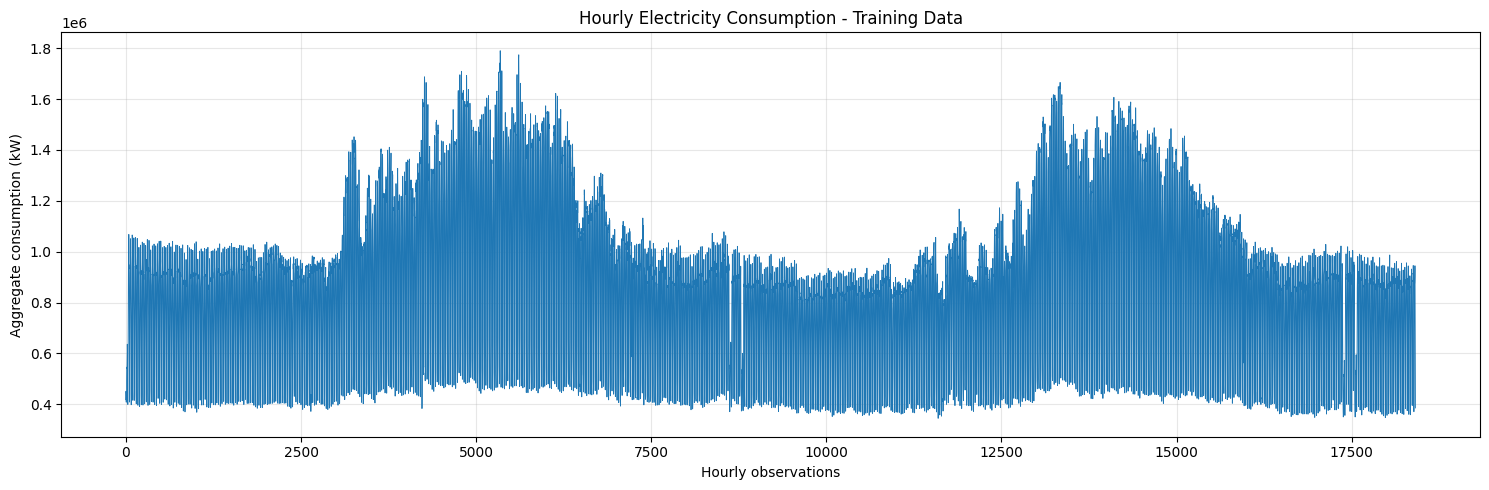

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(train, linewidth=0.6)
plt.title("Hourly Electricity Consumption - Training Data")
plt.xlabel("Hourly observations")
plt.ylabel("Aggregate consumption (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Training Series

The time-series plot provides an initial view of how aggregate electricity consumption changes over the training period.

The consumption values fluctuate considerably from one hour to another. This indicates that electricity usage is not constant and that the series contains variations that need to be considered during forecasting.

The plot also provides an initial indication of changes in the consumption level over time. Further analysis using autocorrelation and time-series decomposition is required to understand the recurring patterns more clearly.

## 5. Autocorrelation Function (ACF)

The ACF is a preliminary identification aid for MA(q). A theoretical MA(q) process has an ACF that cuts off after lag q. Real data may not show a perfectly clear cutoff.

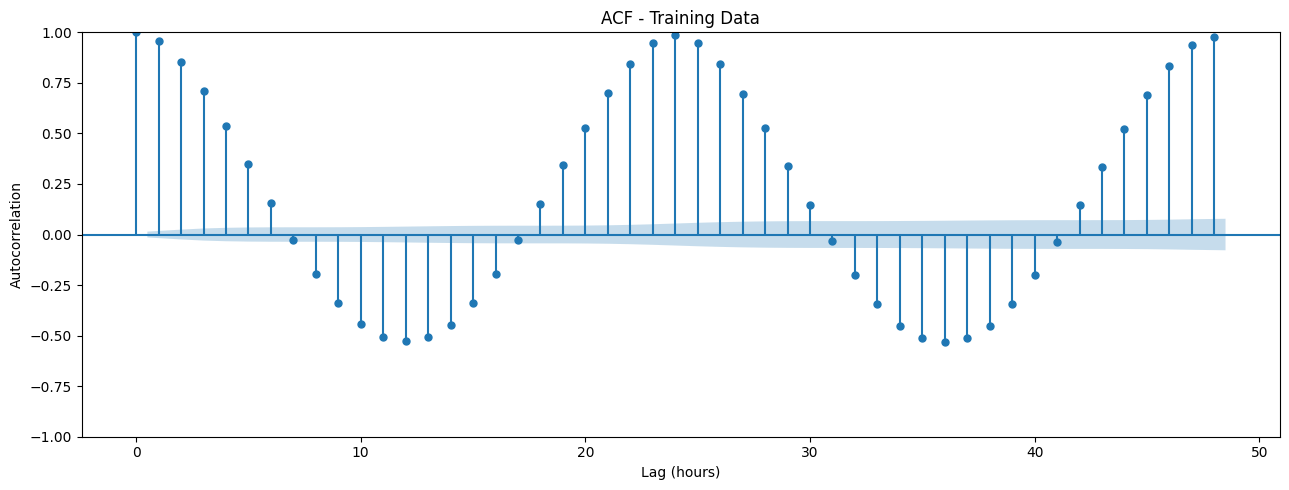

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_acf(train, lags=48, ax=ax)
ax.set_title("ACF - Training Data")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

### Interpretation of the ACF Plot

The ACF plot is used to examine the relationship between the original series and its past observations at different hourly lags.

The autocorrelation pattern helps identify whether earlier consumption values are associated with current consumption. This is useful because electricity demand may show recurring hourly and daily patterns.

The ACF provides preliminary guidance for identifying possible Moving Average model orders. However, the order should not be selected from the ACF plot alone. The candidate models must also be compared using validation performance.

## 6. Partial Autocorrelation Function (PACF)

The PACF is a preliminary identification aid for AR(p). A theoretical AR(p) process has a PACF that cuts off after lag p. Interpret the overall pattern rather than relying on a single bar.

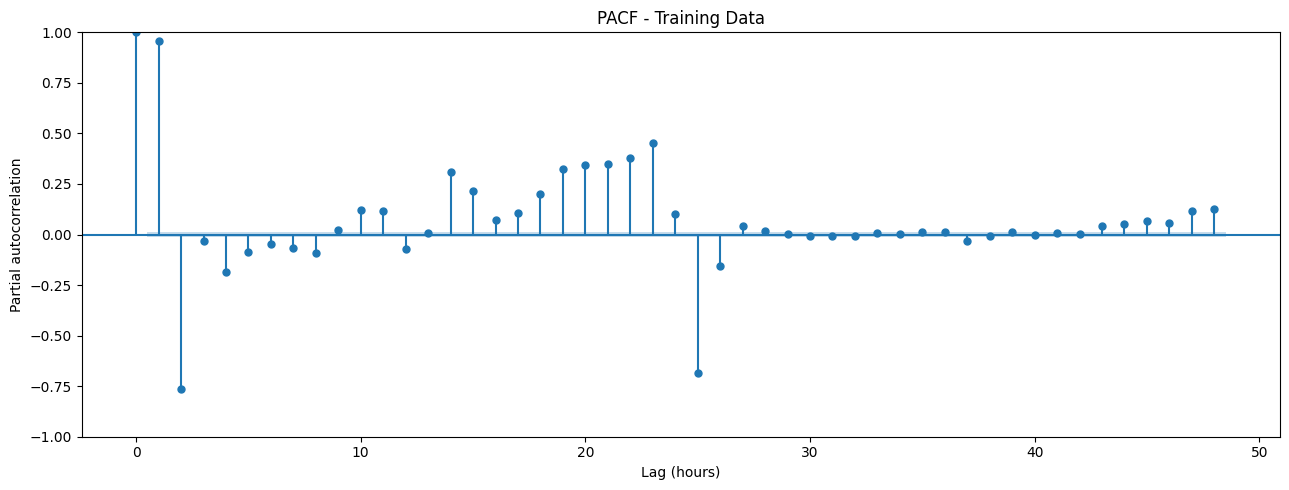

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_pacf(train, lags=48, method="ywm", ax=ax)
ax.set_title("PACF - Training Data")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Partial autocorrelation")
plt.tight_layout()
plt.show()

### Interpretation of the PACF Plot

The PACF plot examines the direct relationship between the series and its past observations after accounting for the influence of intermediate lags.

It provides preliminary guidance for identifying possible Autoregressive model orders. The PACF is particularly useful when examining which earlier hourly observations may contribute additional information to the current value.

The plot is considered together with the ACF and the validation results when selecting candidate AR models. The final order is not determined from a single significant lag.

## 7. Evaluation metrics

These metrics are calculated on the validation forecasts for model selection. Final test metrics will be calculated later, after model choices are made. The four evaluation measures provide different perspectives on forecasting performance. RMSE gives greater weight to larger errors, while MAE represents the average absolute difference between actual and predicted values. MAPE expresses the error as a percentage, and R² indicates how much of the variation in the actual observations is explained by the predictions.

Using these measures together provides a more complete basis for comparing the forecasting models.

In [ ]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    return {
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE (%)": mean_absolute_percentage_error(actual, predicted) * 100,
        "R2": r2_score(actual, predicted)
    }

## 8. Rolling one-step-ahead forecasting function

Each model is initially fitted on the training data. For each validation timestamp, it forecasts one step ahead and then incorporates the actual validation observation before forecasting the next timestamp. Parameters are not re-estimated during this updating process. This approach reflects a rolling forecasting situation in which the actual observation becomes available after each forecast. The model then uses the updated history to forecast the next hour. The model parameters remain unchanged during this process, so the updating of observations should not be confused with retraining the model.

In [ ]:
def rolling_one_step_forecast(training_data, evaluation_data, order):
    fitted_model = ARIMA(
        training_data,
        order=order,
        trend="c"
    ).fit()

    predictions = []

    for actual_value in np.asarray(evaluation_data, dtype=float):
        forecast = fitted_model.forecast(steps=1)
        predictions.append(float(np.asarray(forecast)[0]))

        # Update the state with the actual observation without refitting parameters
        fitted_model = fitted_model.extend(
            np.asarray([actual_value], dtype=float)
        )

    return np.asarray(predictions)

## 9. Fit candidate MA(q) models

The candidate q values below are investigated using validation RMSE. They are candidate orders, not assumed to be optimal. The ACF pattern and model simplicity should also inform the final choice.

**Reminder:** MA(q) here means a model based on current and previous forecast errors. It is not a simple moving-average smoothing calculation.

In [ ]:
q_values = [1, 2, 3, 6, 12, 24]

ma_results = []
ma_predictions = {}

for q in q_values:
    try:
        predictions = rolling_one_step_forecast(
            training_data=train,
            evaluation_data=validation,
            order=(0, 0, q)
        )

        metrics = calculate_metrics(validation, predictions)
        ma_predictions[q] = predictions

        ma_results.append({
            "Model": f"MA({q})",
            "Order": q,
            **metrics
        })

        print(f"MA({q}) completed.")

    except Exception as error:
        print(f"MA({q}) failed: {error}")

ma_table = pd.DataFrame(ma_results)

if ma_table.empty:
    raise RuntimeError("No MA(q) candidate completed successfully.")

ma_table = ma_table.sort_values("RMSE").reset_index(drop=True)
display(ma_table)

MA(1) completed.
MA(2) completed.
MA(3) completed.
MA(6) completed.
MA(12) completed.
MA(24) completed.


,Model,Order,RMSE,MAE,MAPE (%),R2
0,MA(24),24,37955.618829,29822.222276,4.348235,0.982292
1,MA(12),12,47969.448655,33884.298404,4.749161,0.971715
2,MA(6),6,54037.912136,41274.177801,6.271409,0.964106
3,MA(3),3,76576.613847,62783.404950,10.043160,0.927919
4,MA(2),2,99083.374501,82523.570483,13.582172,0.879322
5,MA(1),1,156597.919232,132210.536521,22.245207,0.698562


### Interpretation of MA Model Results

The candidate Moving Average models were evaluated using validation RMSE, MAE, MAPE and R².

Among the candidate MA models, MA(24) recorded the lowest validation RMSE of approximately 37,955.62. This indicates that, within the MA configurations examined, the 24-lag model provided the best validation performance.

The result suggests that information contained in earlier forecast errors up to the selected lag may contribute to explaining hourly consumption variations.

However, the MA(24) model is not selected in isolation. Its performance will be compared with the candidate Autoregressive models before proceeding with the final model selection.

## 10. Fit candidate AR(p) models

The candidate p values are evaluated in the same way as the MA models. The PACF is a preliminary identification aid, and validation performance helps compare candidates.

In [ ]:
p_values = [1, 2, 3, 6, 12, 24]

ar_results = []
ar_predictions = {}

for p in p_values:
    try:
        predictions = rolling_one_step_forecast(
            training_data=train,
            evaluation_data=validation,
            order=(p, 0, 0)
        )

        metrics = calculate_metrics(validation, predictions)
        ar_predictions[p] = predictions

        ar_results.append({
            "Model": f"AR({p})",
            "Order": p,
            **metrics
        })

        print(f"AR({p}) completed.")

    except Exception as error:
        print(f"AR({p}) failed: {error}")

ar_table = pd.DataFrame(ar_results)

if ar_table.empty:
    raise RuntimeError("No AR(p) candidate completed successfully.")

ar_table = ar_table.sort_values("RMSE").reset_index(drop=True)
display(ar_table)

AR(1) completed.
AR(2) completed.
AR(3) completed.
AR(6) completed.
AR(12) completed.
AR(24) completed.


,Model,Order,RMSE,MAE,MAPE (%),R2
0,AR(24),24,26691.724883,18901.668881,2.555950,0.991243
1,AR(12),12,47343.083509,33554.152541,4.687124,0.972449
2,AR(6),6,48202.696172,33130.688717,4.622650,0.971439
3,AR(3),3,49508.211037,33608.787716,4.737572,0.969871
4,AR(2),2,49513.921674,33531.659007,4.725943,0.969864
5,AR(1),1,82881.896829,57787.372563,8.665271,0.915560


### Interpretation of AR Model Results

The candidate Autoregressive models were evaluated using the same validation dataset and evaluation measures used for the MA models.

Among the candidate AR models, AR(24) recorded the lowest validation RMSE of approximately 26,691.72. This is lower than the validation RMSE obtained by the best candidate MA model.

The result indicates that the AR(24) model captures useful information from the previous 24 hourly observations when estimating the next-hour consumption.

The AR(24) model is therefore taken forward for comparison with the MA candidates.

## 11. Compare MA(q) and AR(p) candidates

The model with the lowest validation RMSE is the best candidate among those tested. It is not automatically the final project model: we must also consider ACF/PACF, stationarity, residual behaviour and model assumptions.

In [ ]:
comparison = pd.concat(
    [
        ma_table.drop(columns=["Order"]),
        ar_table.drop(columns=["Order"])
    ],
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

display(comparison)

best_model_name = comparison.iloc[0]["Model"]
print("Best candidate by validation RMSE:", best_model_name)
print("Validation RMSE:", comparison.iloc[0]["RMSE"])

,Model,RMSE,MAE,MAPE (%),R2
0,AR(24),26691.724883,18901.668881,2.555950,0.991243
1,MA(24),37955.618829,29822.222276,4.348235,0.982292
2,AR(12),47343.083509,33554.152541,4.687124,0.972449
3,MA(12),47969.448655,33884.298404,4.749161,0.971715
4,AR(6),48202.696172,33130.688717,4.622650,0.971439
5,AR(3),49508.211037,33608.787716,4.737572,0.969871
6,AR(2),49513.921674,33531.659007,4.725943,0.969864
7,MA(6),54037.912136,41274.177801,6.271409,0.964106
8,MA(3),76576.613847,62783.404950,10.043160,0.927919
9,AR(1),82881.896829,57787.372563,8.665271,0.915560


Best candidate by validation RMSE: AR(24)
Validation RMSE: 26691.72488321917


### Interpretation of the MA and AR Comparison

The combined validation comparison shows that AR(24) achieved the lowest RMSE among the MA and AR candidates examined.

Its validation RMSE was approximately 26,691.72, compared with approximately 37,955.62 for MA(24).

This indicates that the AR(24) model performed better than the tested MA candidates on the validation dataset. The result supports carrying AR(24) forward for further examination.

The selection is based on validation performance and will be followed by visual comparison and final test evaluation.

## 12. Plot the best candidate's validation forecasts

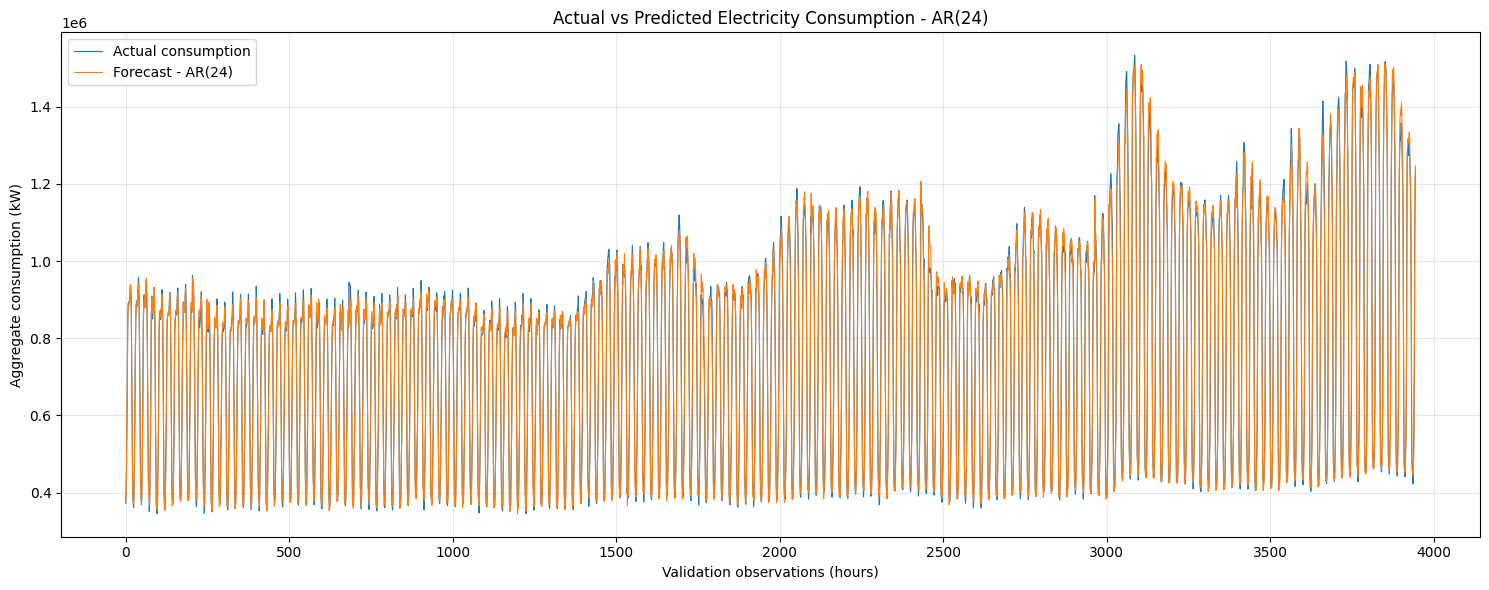

In [ ]:
if best_model_name.startswith("MA"):
    best_order = int(best_model_name.split("(")[1].replace(")", ""))
    best_predictions = ma_predictions[best_order]
else:
    best_order = int(best_model_name.split("(")[1].replace(")", ""))
    best_predictions = ar_predictions[best_order]

plt.figure(figsize=(15, 6))
plt.plot(validation.to_numpy(), label="Actual consumption", linewidth=0.8)
plt.plot(best_predictions, label=f"Forecast - {best_model_name}", linewidth=0.8)
plt.title(f"Actual vs Predicted Electricity Consumption - {best_model_name}")
plt.xlabel("Validation observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Validation Forecast Plot

The plot compares the actual electricity consumption values with the forecasts generated by the best candidate model selected from the MA and AR comparison.

The comparison helps examine how closely the predicted values follow the movement of the actual consumption series. It also provides a visual indication of the model's ability to capture changes in hourly demand.

The visual comparison should be considered together with the validation error measures. A model may follow the general direction of the series while still producing noticeable errors during sudden changes in consumption.

## 13. Zoom into the first week of validation data

A one-week view makes it easier to compare the hourly shape of actual and forecast consumption.

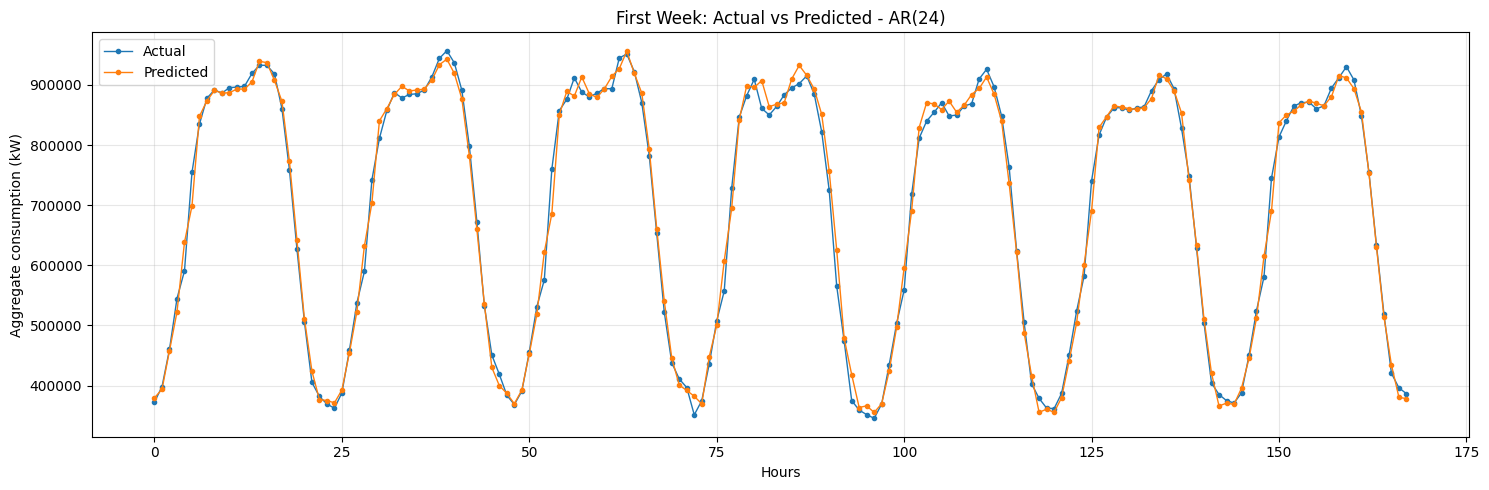

In [ ]:
display_hours = min(168, len(validation))

plt.figure(figsize=(15, 5))
plt.plot(
    validation.iloc[:display_hours].to_numpy(),
    label="Actual",
    marker=".",
    linewidth=1
)
plt.plot(
    best_predictions[:display_hours],
    label="Predicted",
    marker=".",
    linewidth=1
)
plt.title(f"First Week: Actual vs Predicted - {best_model_name}")
plt.xlabel("Hours")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the First-Week Validation Plot

The first-week view provides a closer comparison of actual and predicted electricity consumption over a shorter period.

This view makes it easier to examine how the model responds to hourly fluctuations and changes in consumption that may not be clearly visible in the full validation plot.

The comparison is useful for identifying periods where the forecast follows the actual movement and periods where the difference becomes more noticeable.

This visual assessment complements the numerical validation metrics and helps understand the model's forecasting behaviour.

# 14. Save validation results

The CSV files can be downloaded and used when documenting the model comparison.

In [ ]:
ma_table.to_csv("MA_q_validation_results.csv", index=False)
ar_table.to_csv("AR_p_validation_results.csv", index=False)
comparison.to_csv("MA_AR_comparison_validation.csv", index=False)

print("Saved:")
print("- MA_q_validation_results.csv")
print("- AR_p_validation_results.csv")
print("- MA_AR_comparison_validation.csv")

Saved:
- MA_q_validation_results.csv
- AR_p_validation_results.csv
- MA_AR_comparison_validation.csv


### Interpretation of the Saved Validation Results

The validation forecasts and their corresponding evaluation results have been saved for subsequent analysis.

Saving these results helps maintain a record of the candidate-model performance and avoids depending only on the displayed notebook output.

The validation results will be used to support the selection and comparison of forecasting models. The test dataset remains separate and is reserved for final evaluation.


## 15. Final Test Evaluation of Selected MA and AR Models

After comparing the candidate models using validation RMSE, I selected MA(24) and AR(24) for final evaluation.

I retain these selected orders and do not use the test set for further model selection.

For test evaluation, each model is initially fitted using the training observations. The fitted model state is then updated sequentially using the actual validation observations without re-estimating the model parameters.

The test forecasts are generated one step at a time. After each forecast, the actual observation is incorporated into the model state before forecasting the next observation.

I evaluate the models using RMSE, MAE, MAPE and R². I also plot the actual and predicted consumption values over the complete test period and the first seven days.


Selected MA order: 24
Selected AR order: 24

MA(24) fitted on training data.
MA(24) test forecasting completed.

AR(24) fitted on training data.
AR(24) test forecasting completed.

Final MA and AR test-set comparison:


,Model,RMSE,MAE,MAPE (%),R2
0,MA(24),50814.362072,37793.288966,4.980391,0.977202
1,AR(24),36465.266706,24419.230771,3.202652,0.988260


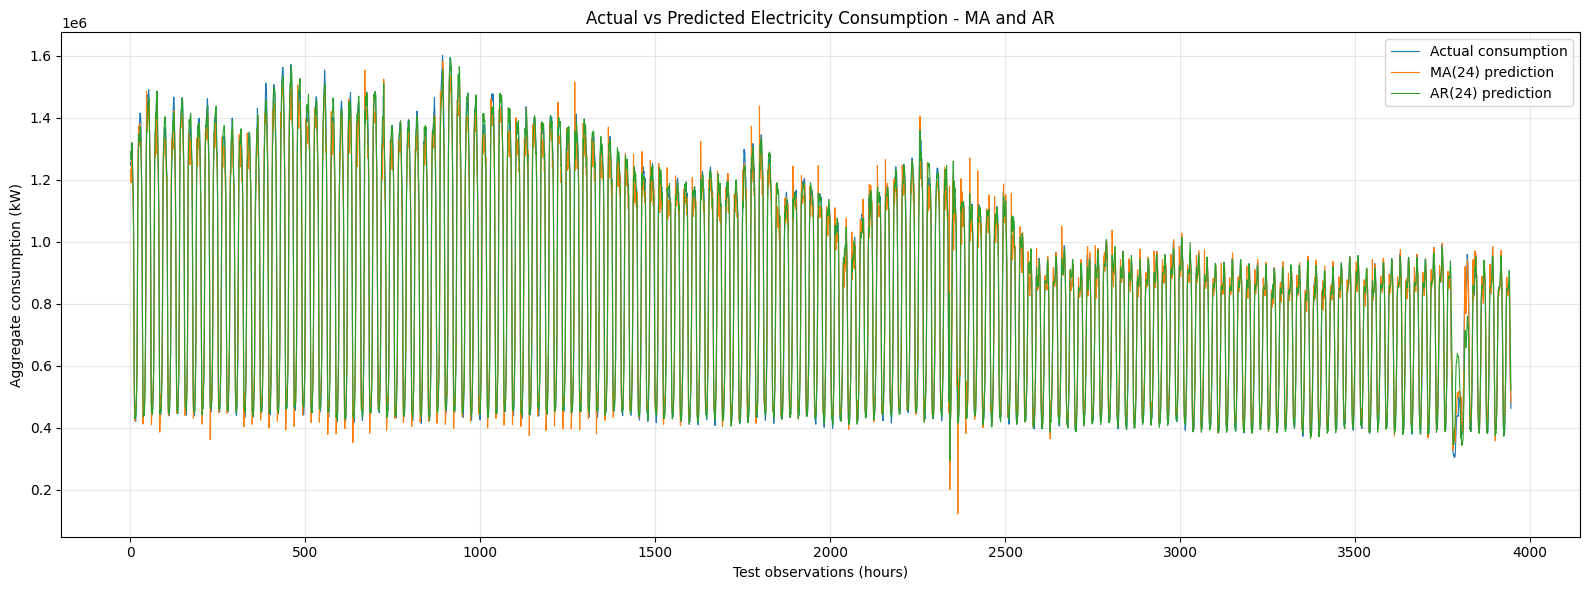

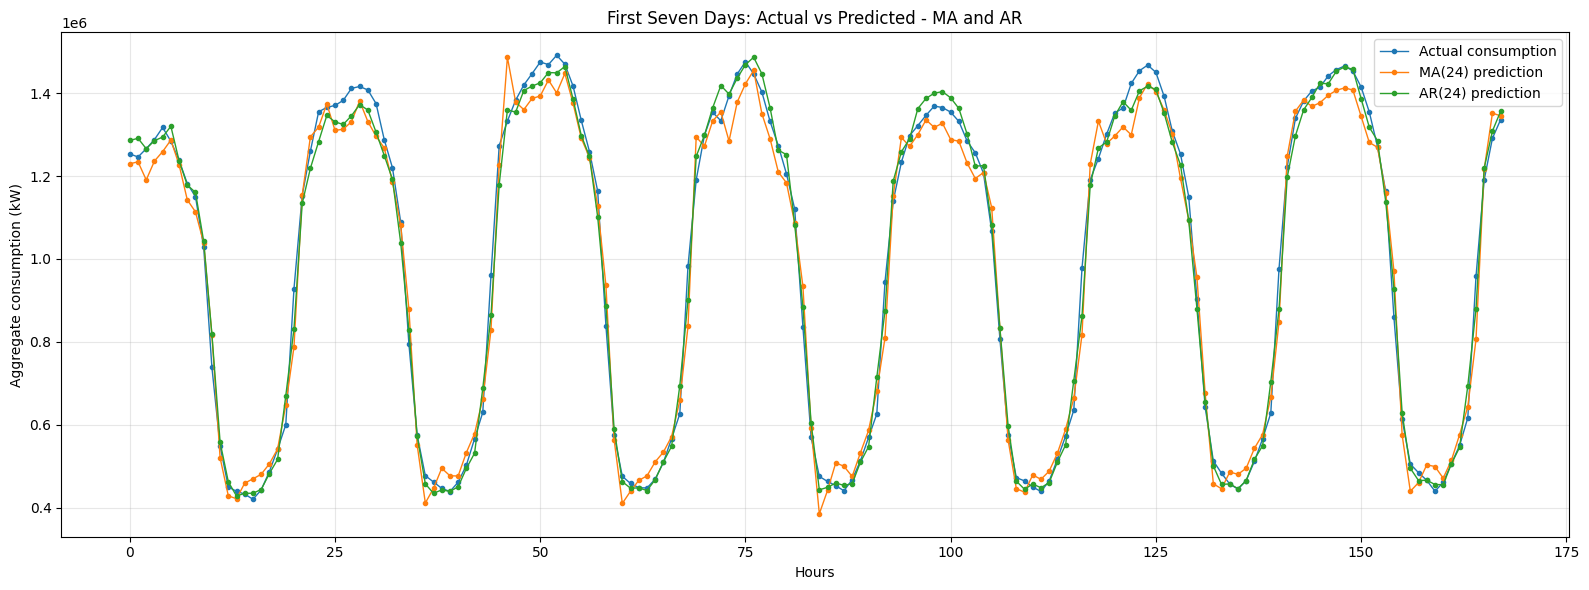


Saved: MA_AR_test_comparison.csv
MA and AR test evaluation completed successfully.


In [ ]:

# SECTION 15: FINAL TEST EVALUATION OF SELECTED MA AND AR MODELS

# --------------------------------------------------
# 1. VERIFY DATA AND PREVIOUS VALIDATION RESULTS
# --------------------------------------------------

assert len(train) == 18412
assert len(validation) == 3945
assert len(test) == 3947

assert not ma_table.empty
assert not ar_table.empty

# Select the best MA and AR orders using validation RMSE only.
selected_ma_order = int(
    ma_table.sort_values("RMSE").iloc[0]["Order"]
)

selected_ar_order = int(
    ar_table.sort_values("RMSE").iloc[0]["Order"]
)

print("Selected MA order:", selected_ma_order)
print("Selected AR order:", selected_ar_order)

# Confirm that the previously selected orders are retained.
assert selected_ma_order == 24
assert selected_ar_order == 24

# --------------------------------------------------
# 2. FUNCTION FOR SEQUENTIAL TEST FORECASTING
# --------------------------------------------------

def evaluate_selected_model_on_test(order, model_name):

    # Fit model using training observations only.
    fitted_model = ARIMA(
        train,
        order=order,
        trend="c"
    ).fit()

    print(f"\n{model_name} fitted on training data.")

    # Update model state using actual validation observations.
    # Parameters are not re-estimated.
    fitted_after_validation = fitted_model.extend(
        validation.to_numpy(dtype=float)
    )

    # Generate sequential one-step-ahead test forecasts.
    predictions = []

    for actual_value in test.to_numpy(dtype=float):

        forecast = fitted_after_validation.forecast(steps=1)

        predicted_value = float(np.asarray(forecast).reshape(-1)[0])

        predictions.append(predicted_value)

        # Incorporate the actual observation before the next forecast.
        fitted_after_validation = fitted_after_validation.extend(
            np.asarray([actual_value], dtype=float)
        )

    predictions = np.asarray(predictions)

    if len(predictions) != len(test):
        raise ValueError(
            f"{model_name}: prediction count does not match test observations."
        )

    if not np.isfinite(predictions).all():
        raise ValueError(
            f"{model_name}: predictions contain non-finite values."
        )

    print(f"{model_name} test forecasting completed.")

    return predictions


# --------------------------------------------------
# 3. EVALUATE MA(24) AND AR(24)
# --------------------------------------------------

ma_test_predictions = evaluate_selected_model_on_test(
    order=(0, 0, selected_ma_order),
    model_name=f"MA({selected_ma_order})"
)

ar_test_predictions = evaluate_selected_model_on_test(
    order=(selected_ar_order, 0, 0),
    model_name=f"AR({selected_ar_order})"
)


# --------------------------------------------------
# 4. CALCULATE TEST METRICS
# --------------------------------------------------

ma_test_metrics = calculate_metrics(
    test,
    ma_test_predictions
)

ar_test_metrics = calculate_metrics(
    test,
    ar_test_predictions
)

ma_ar_test_comparison = pd.DataFrame([
    {
        "Model": f"MA({selected_ma_order})",
        **ma_test_metrics
    },
    {
        "Model": f"AR({selected_ar_order})",
        **ar_test_metrics
    }
])

print("\nFinal MA and AR test-set comparison:")
display(ma_ar_test_comparison)


# --------------------------------------------------
# 5. PLOT COMPLETE TEST-PERIOD FORECASTS
# --------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    test.to_numpy(),
    label="Actual consumption",
    linewidth=0.8
)

plt.plot(
    ma_test_predictions,
    label=f"MA({selected_ma_order}) prediction",
    linewidth=0.8
)

plt.plot(
    ar_test_predictions,
    label=f"AR({selected_ar_order}) prediction",
    linewidth=0.8
)

plt.title("Actual vs Predicted Electricity Consumption - MA and AR")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. PLOT FIRST SEVEN DAYS OF TEST PERIOD
# --------------------------------------------------

hours_to_plot = min(168, len(test))

plt.figure(figsize=(16, 6))

plt.plot(
    test.to_numpy()[:hours_to_plot],
    label="Actual consumption",
    marker=".",
    linewidth=1
)

plt.plot(
    ma_test_predictions[:hours_to_plot],
    label=f"MA({selected_ma_order}) prediction",
    marker=".",
    linewidth=1
)

plt.plot(
    ar_test_predictions[:hours_to_plot],
    label=f"AR({selected_ar_order}) prediction",
    marker=".",
    linewidth=1
)

plt.title("First Seven Days: Actual vs Predicted - MA and AR")
plt.xlabel("Hours")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. SAVE TEST RESULTS
# --------------------------------------------------

ma_ar_test_comparison.to_csv(
    "MA_AR_test_comparison.csv",
    index=False
)

print("\nSaved: MA_AR_test_comparison.csv")
print("MA and AR test evaluation completed successfully.")


In [ ]:
from google.colab import files
files.download("MA_AR_test_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpretation of the Final MA and AR Test Results

The selected MA and AR models were evaluated using the test dataset, which was not used during candidate selection.

The test results provide an indication of how the selected models perform on observations that were kept separate from the model-selection process.

The comparison should be based on RMSE, MAE, MAPE and R², along with the actual-versus-predicted plots. The model with lower error values and a closer visual match provides stronger forecasting performance within this comparison.

These results establish a baseline for evaluating the more advanced ARIMA and SARIMA models developed in the subsequent sections.

# 16. Stationarity Analysis and Differencing

**Dataset:** Prepared hourly aggregate electricity consumption from 321 consumers  
**Target variable:** `aggregate_consumption_kW_prepared`

In this notebook, I check whether my training time series is stationary. I use the Augmented Dickey-Fuller (ADF) test, examine the series visually, and apply differencing only if the test and plots indicate that it is needed.

I keep the same chronological split used in the earlier MA(q) and AR(p) work. I do not use the validation or test observations to decide whether the training series needs differencing.

## 17. Visual examination of the training series

In class, stationarity was explained in terms of whether statistical characteristics such as mean and variance remain broadly stable over time. I first inspect the training series and compare rolling averages and standard deviations. These plots are supporting evidence; I do not decide stationarity from a plot alone.

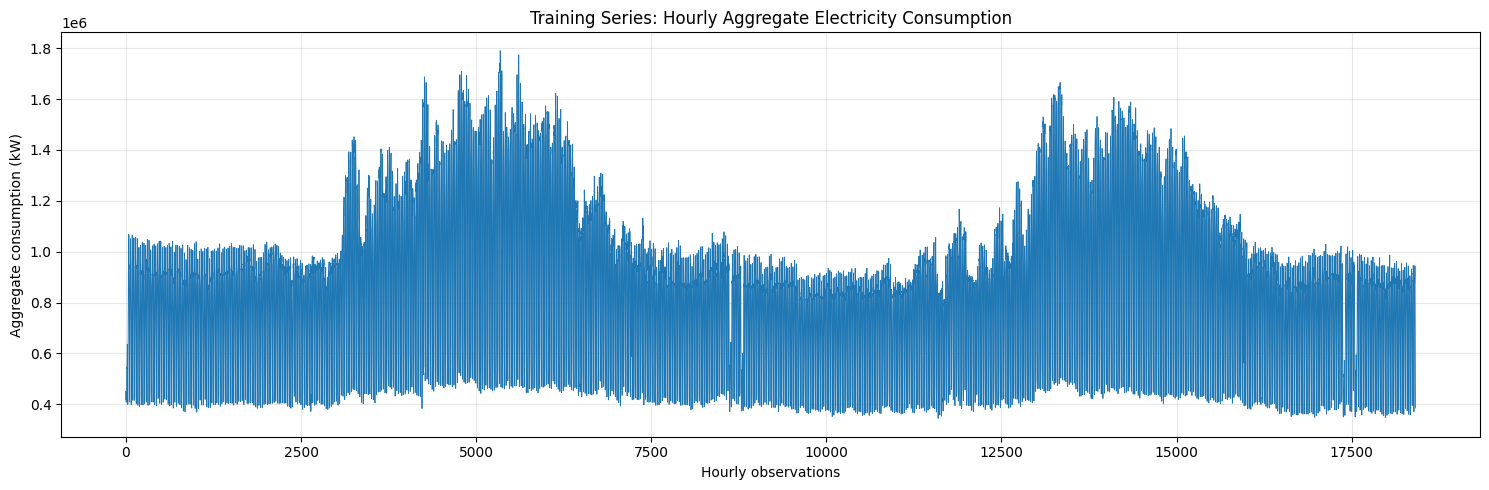

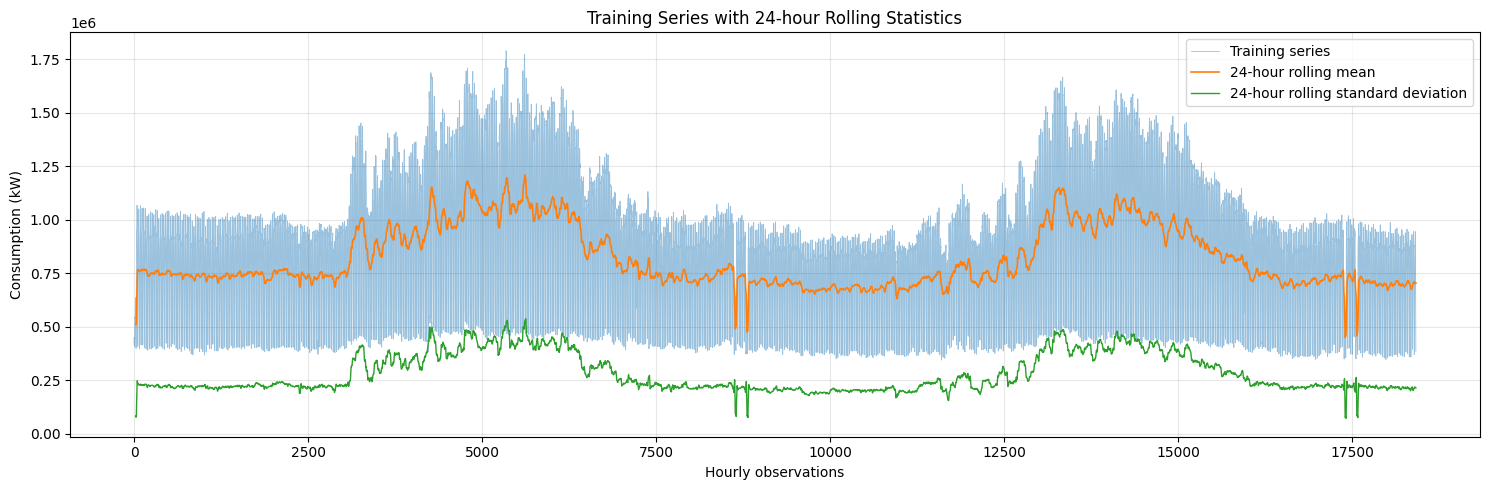

In [ ]:
# I plot the training observations in their original time order.
plt.figure(figsize=(15, 5))
plt.plot(train, linewidth=0.6)
plt.title("Training Series: Hourly Aggregate Electricity Consumption")
plt.xlabel("Hourly observations")
plt.ylabel("Aggregate consumption (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# I calculate rolling mean and standard deviation over a 24-hour window.
# This window gives a local view over one daily cycle.
rolling_mean = train.rolling(window=24).mean()
rolling_std = train.rolling(window=24).std()

plt.figure(figsize=(15, 5))
plt.plot(train, label="Training series", alpha=0.45, linewidth=0.6)
plt.plot(rolling_mean, label="24-hour rolling mean", linewidth=1.2)
plt.plot(rolling_std, label="24-hour rolling standard deviation", linewidth=1.0)
plt.title("Training Series with 24-hour Rolling Statistics")
plt.xlabel("Hourly observations")
plt.ylabel("Consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Visual Stationarity Check

The original training series shows considerable variation in electricity consumption over time. The rolling mean and rolling standard deviation help examine whether the average level and variability remain stable throughout the observation period.

The plots indicate changes in the consumption level and fluctuations in variability. This suggests that the series should be examined further before selecting the differencing order for ARIMA modelling.

Visual examination alone is not sufficient to establish stationarity. I therefore use STL decomposition and statistical tests in the following sections to support the decision.


## 18. Time-Series Decomposition using STL

I use Seasonal-Trend decomposition using LOESS (STL) to separate the training series into three components: trend, seasonality and residual.

Since the observations are recorded hourly, I use a seasonal period of 24 to examine the daily consumption pattern.

The decomposition is performed only on the training data. The trend component shows the long-term movement in electricity consumption, the seasonal component represents the repeating daily pattern, and the residual component contains the variation not explained by the estimated trend and seasonality.

I also examine the residual autocorrelation to assess whether any systematic temporal pattern remains. The residual component is not assumed to be white noise automatically.


Training observations: 18412
Seasonal period: 24 hours
Hourly frequency verified.


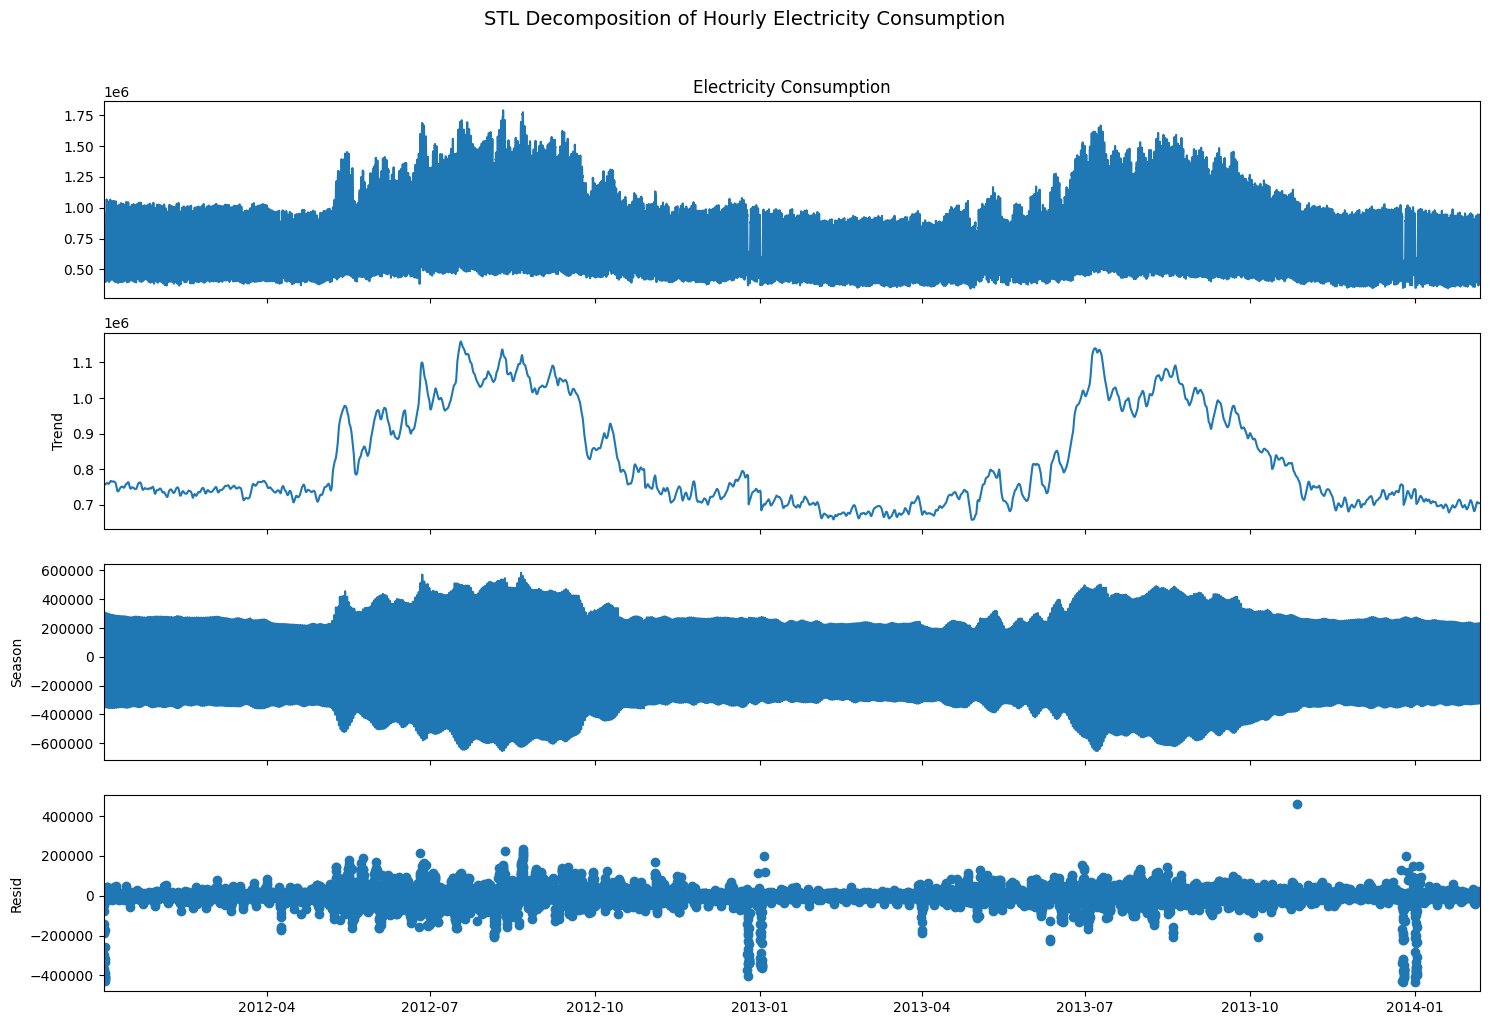


Residual summary:
count     18412.000000
mean      -1491.072881
std       36483.017808
min     -435208.081991
25%       -6012.655827
50%         -67.417286
75%        5963.334046
max      461003.048336
Name: resid, dtype: float64

Ljung-Box test on STL residuals:


,lb_stat,lb_pvalue
24,55423.196143,0.0
48,56591.599576,0.0


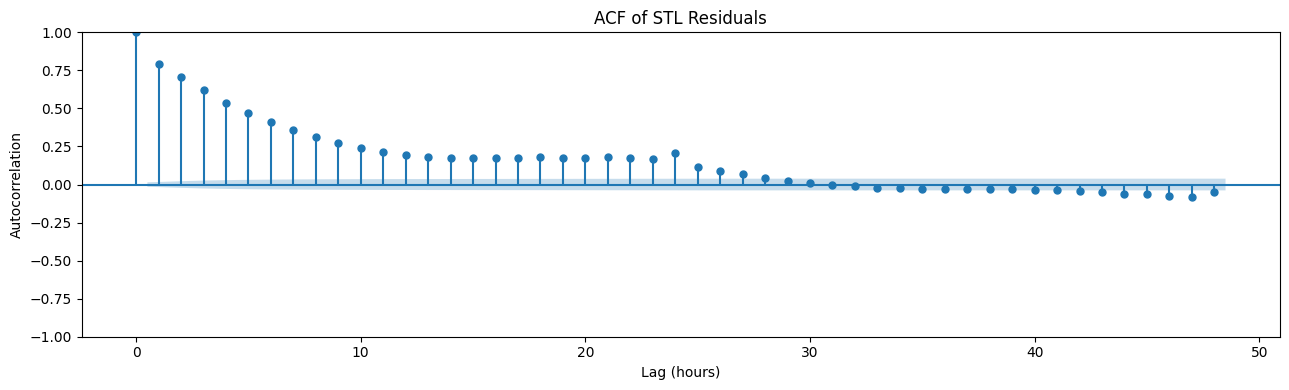

In [ ]:

# STL decomposition of the training series
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.diagnostic import acorr_ljungbox

# Reconstruct the training series with its original timestamps.
# This makes the hourly time index explicit.
train_timestamps = pd.DatetimeIndex(
    df.loc[:len(train)-1, "timestamp"]
)

train_stl = pd.Series(
    train.to_numpy(),
    index=train_timestamps,
    name="Electricity Consumption"
)

# Check that the observations are equally spaced hourly.
time_gaps = train_stl.index.to_series().diff().dropna()

if not (time_gaps == pd.Timedelta(hours=1)).all():
    raise ValueError(
        "The training timestamps are not consistently one hour apart. "
        "Check the timestamp sequence before performing STL."
    )

print("Training observations:", len(train_stl))
print("Seasonal period:", 24, "hours")
print("Hourly frequency verified.")

# Apply STL decomposition with a daily seasonal period.
stl_model = STL(
    train_stl,
    period=24,
    robust=True
)

stl_result = stl_model.fit()

# Plot the observed series and its three components.
fig = stl_result.plot()
fig.set_size_inches(15, 10)
fig.suptitle(
    "STL Decomposition of Hourly Electricity Consumption",
    fontsize=14,
    y=1.02
)
plt.tight_layout()
plt.show()

# Examine the residual component.
stl_residual = stl_result.resid

print("\nResidual summary:")
print(stl_residual.describe())

# Check residual autocorrelation at daily and two-day lags.
ljung_box_results = acorr_ljungbox(
    stl_residual,
    lags=[24, 48],
    return_df=True
)

print("\nLjung-Box test on STL residuals:")
display(ljung_box_results)

# Plot residual autocorrelation.
fig, ax = plt.subplots(figsize=(13, 4))
plot_acf(stl_residual, lags=48, ax=ax)
ax.set_title("ACF of STL Residuals")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()


### Interpretation of the STL Decomposition

The STL decomposition was performed on 18,412 training observations using a seasonal period of 24 hours.

The decomposition separates the series into observed, trend, seasonal and residual components. The trend component shows changes in the underlying consumption level, while the seasonal component represents the recurring daily pattern.

The residual component contains the variation that remains after accounting for the estimated trend and seasonality. The Ljung–Box test produced statistics of 55,423.20 at lag 24 and 56,591.60 at lag 48, with p-values below 0.05.

Therefore, the null hypothesis of no residual autocorrelation is rejected at both lags. This indicates that significant temporal dependence remains after the STL decomposition.

The results suggest that daily seasonality is present, but the decomposition does not explain all the time-dependent variation. The remaining autocorrelation needs to be considered during model development.



## 19. Interpretation of STL Decomposition and Residual Diagnostics

The STL decomposition was performed on the 18,412 training observations using a seasonal period of 24 hours.

The observed series shows considerable variation in electricity consumption during the training period. A noticeable increase can be seen around April 2012, followed by another period of elevated consumption during the middle of 2013. The trend component reflects these changes in the underlying consumption level rather than showing a continuous upward or downward movement.

The seasonal component captures the recurring daily variation in electricity consumption. Its amplitude changes across the observation period, suggesting that the magnitude of the daily seasonal pattern is not completely constant.

The residual component represents the variation remaining after the estimated trend and seasonal components have been removed. The residual plot contains several large positive and negative deviations, indicating that the STL decomposition does not explain all the fluctuations in the original series.

The residual ACF shows strong positive autocorrelation at the initial lags, followed by a gradual decline. The Ljung–Box statistics at lags 24 and 48 are 55,423.20 and 56,591.60, respectively, with p-values below 0.05. Therefore, the null hypothesis of no autocorrelation is rejected at both lags.

These results indicate that significant temporal dependence remains in the residual component. The STL decomposition is useful for examining the trend and daily seasonal behaviour of electricity consumption; however, the residual diagnostics show that additional temporal patterns remain to be considered during forecasting.

## 20. Augmented Dickey-Fuller (ADF) test on the original training series

The ADF test is a unit-root test.

- **Null hypothesis (H0):** the series has a unit root (non-stationary).
- **Alternative hypothesis (H1):** the series does not have a unit root (evidence of stationarity).

I use a 5% significance level (0.05), as discussed in class. If the p-value is below 0.05, I reject H0. If it is 0.05 or higher, I fail to reject H0. A p-value above 0.05 does not prove that the series is non-stationary; it means that this test has not provided sufficient evidence to reject the unit-root null hypothesis.

In [ ]:
# I run the ADF test on the training observations only.
# autolag="AIC" lets the test select the augmentation lag using AIC.
adf_original = adfuller(train, autolag="AIC")

adf_statistic = adf_original[0]
adf_pvalue = adf_original[1]
used_lags = adf_original[2]
number_observations = adf_original[3]
critical_values = adf_original[4]

print("ADF TEST: ORIGINAL TRAINING SERIES")
print("-----------------------------------")
print(f"ADF statistic: {adf_statistic:.6f}")
print(f"p-value: {adf_pvalue:.6f}")
print(f"Number of lags used: {used_lags}")
print(f"Number of observations: {number_observations}")
print("Critical values:")
for level, value in critical_values.items():
    print(f"  {level}: {value:.6f}")

alpha = 0.05

if adf_pvalue < alpha:
    print("\nDecision: Reject the null hypothesis at the 5% level.")
    print("Interpretation: The test provides evidence against a unit root.")
else:
    print("\nDecision: Fail to reject the null hypothesis at the 5% level.")
    print("Interpretation: The test does not provide sufficient evidence against a unit root.")

ADF TEST: ORIGINAL TRAINING SERIES
-----------------------------------
ADF statistic: -3.245822
p-value: 0.017481
Number of lags used: 45
Number of observations: 18366
Critical values:
  1%: -3.430706
  5%: -2.861697
  10%: -2.566854

Decision: Reject the null hypothesis at the 5% level.
Interpretation: The test provides evidence against a unit root.


### Interpretation of the ADF Test on the Original Series

The ADF test on the original training series produced a test statistic of -3.245822 and a p-value of 0.017481.

At the 5% significance level, the p-value is below 0.05. Therefore, I reject the null hypothesis of a unit root under this ADF test specification.

This result provides evidence against a unit root when the test includes a constant term. However, the result is considered together with the visual examination and the complementary KPSS test, because a single statistical test does not establish every aspect of stationarity.

## 21. First-order differencing

In class, first differencing was explained as subtracting the previous observation from the current observation:

\[
\Delta Y_t = Y_t - Y_{t-1}
\]

I create a first-differenced training series and run the ADF test again. Differencing removes one observation from the beginning because the first observation has no previous value in this series.

Original training observations: 18412
First-differenced observations: 18411


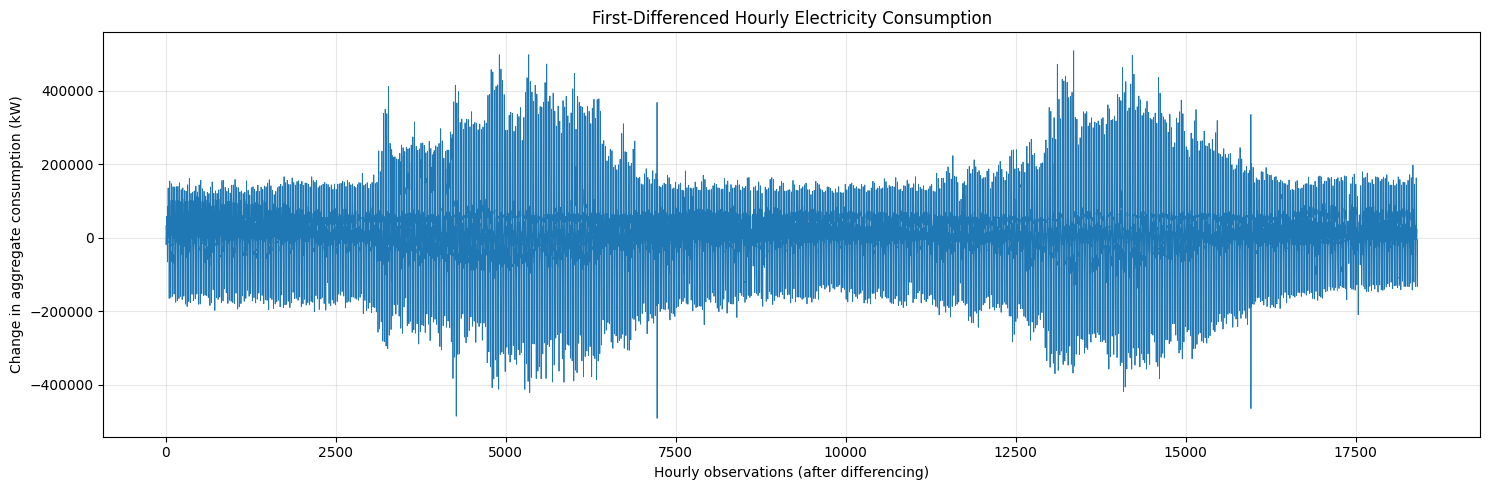

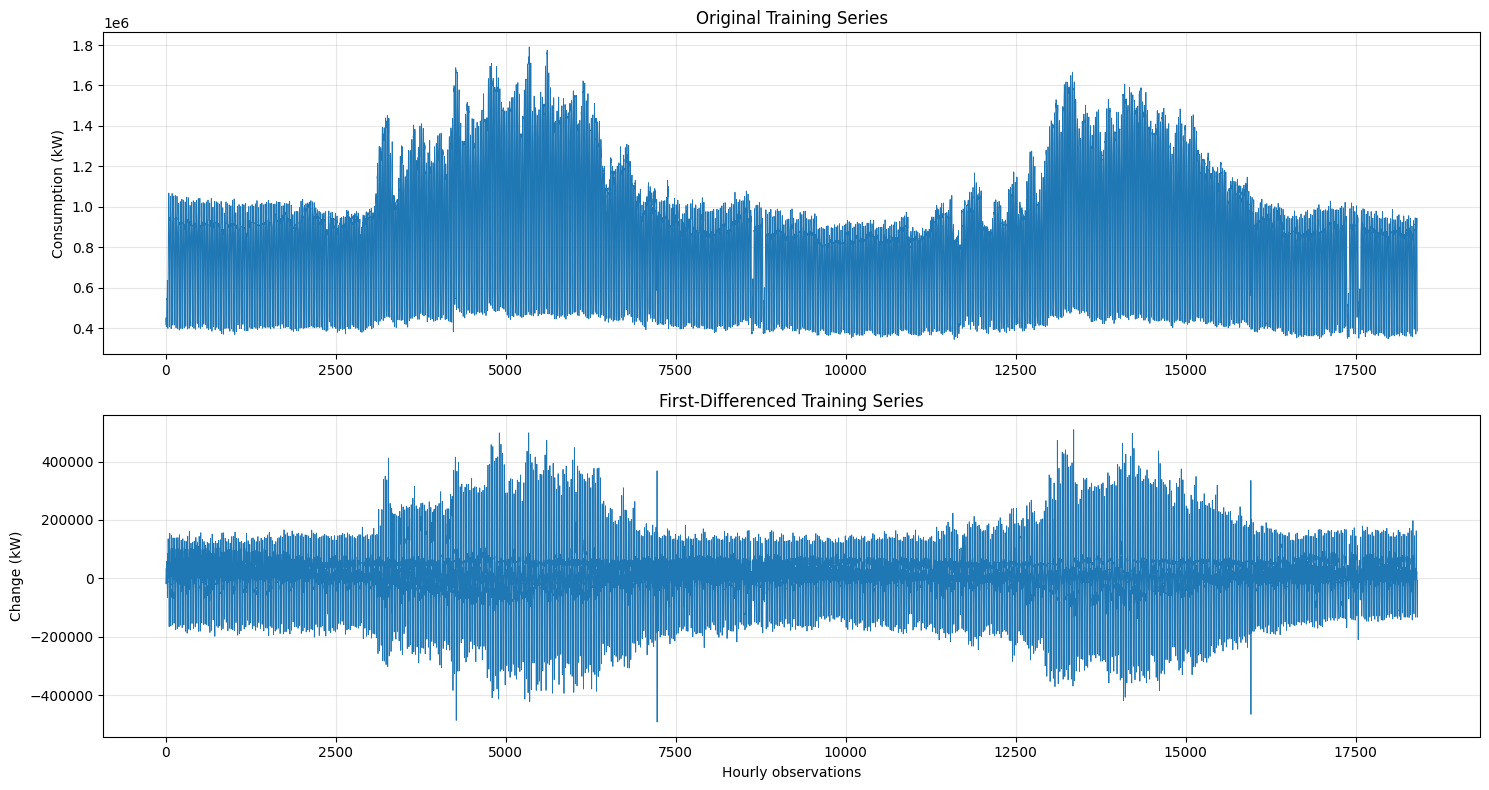

In [ ]:
# I take the difference between each observation and the observation one hour earlier.
train_diff1 = train.diff().dropna()

print("Original training observations:", len(train))
print("First-differenced observations:", len(train_diff1))

# I plot the differenced series to see how its level changes over time.
plt.figure(figsize=(15, 5))
plt.plot(train_diff1, linewidth=0.6)
plt.title("First-Differenced Hourly Electricity Consumption")
plt.xlabel("Hourly observations (after differencing)")
plt.ylabel("Change in aggregate consumption (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# I compare the original and differenced series on separate panels.
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
axes[0].plot(train, linewidth=0.6)
axes[0].set_title("Original Training Series")
axes[0].set_ylabel("Consumption (kW)")
axes[0].grid(alpha=0.3)

axes[1].plot(train_diff1, linewidth=0.6)
axes[1].set_title("First-Differenced Training Series")
axes[1].set_xlabel("Hourly observations")
axes[1].set_ylabel("Change (kW)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation of First-Order Differencing

First-order differencing was applied by subtracting each previous hourly observation from the current observation.

The original training series contains 18,412 observations, while the first-differenced series contains 18,411 observations because the first observation has no preceding value for calculating a difference.

The differenced plot represents changes in consumption from one hour to the next rather than the original consumption level. This transformation helps examine whether the changing level in the original series can be reduced.

The ADF test is performed again in the next section to assess the effect of first differencing.

## 22. ADF test after first differencing

I test the first-differenced series to check whether one round of differencing is sufficient to remove the evidence of a unit root.

In [ ]:
adf_diff1 = adfuller(train_diff1, autolag="AIC")

print("ADF TEST: FIRST-DIFFERENCED TRAINING SERIES")
print("--------------------------------------------")
print(f"ADF statistic: {adf_diff1[0]:.6f}")
print(f"p-value: {adf_diff1[1]:.6f}")
print(f"Number of lags used: {adf_diff1[2]}")
print(f"Number of observations: {adf_diff1[3]}")
print("Critical values:")
for level, value in adf_diff1[4].items():
    print(f"  {level}: {value:.6f}")

if adf_diff1[1] < alpha:
    print("\nDecision: Reject the unit-root null hypothesis at the 5% level.")
    print("Interpretation: The first difference provides evidence against a unit root.")
else:
    print("\nDecision: Fail to reject the unit-root null hypothesis at the 5% level.")
    print("Interpretation: The first difference has not provided sufficient evidence against a unit root.")

ADF TEST: FIRST-DIFFERENCED TRAINING SERIES
--------------------------------------------
ADF statistic: -30.264332
p-value: 0.000000
Number of lags used: 45
Number of observations: 18365
Critical values:
  1%: -3.430706
  5%: -2.861697
  10%: -2.566854

Decision: Reject the unit-root null hypothesis at the 5% level.
Interpretation: The first difference provides evidence against a unit root.


### Interpretation of the ADF Test after First Differencing

The ADF test on the first-differenced training series produced a test statistic of -30.264332 and a p-value reported as 0.000000.

At the 5% significance level, I reject the null hypothesis of a unit root. The result provides strong evidence against a unit root in the first-differenced series.

Compared with the original-series test, the first-differenced series provides stronger evidence of stationarity under the ADF test.

This supports using one ordinary difference, d=1, as the starting point for ARIMA model development. The result is also checked against the KPSS test in the following section.

## 23. Optional complementary KPSS test

The assignment asks for a unit-root test, and the ADF test above addresses that requirement. I also run KPSS as a complementary check because its null hypothesis is different:

- **KPSS H0:** the series is stationary (around a constant when regression='c').
- **KPSS H1:** the series is non-stationary.

I interpret ADF and KPSS together rather than treating either test as a complete description of every aspect of stationarity. The KPSS test can be sensitive to deterministic trend choices, so this is an additional diagnostic.

In [ ]:
# I run KPSS on the original and first-differenced training series.
# regression="c" tests level stationarity.
kpss_original = kpss(train, regression="c", nlags="auto")
kpss_diff1 = kpss(train_diff1, regression="c", nlags="auto")

print("KPSS - ORIGINAL TRAINING SERIES")
print("--------------------------------")
print(f"Statistic: {kpss_original[0]:.6f}")
print(f"p-value: {kpss_original[1]:.6f}")

print("\nKPSS - FIRST-DIFFERENCED TRAINING SERIES")
print("----------------------------------------")
print(f"Statistic: {kpss_diff1[0]:.6f}")
print(f"p-value: {kpss_diff1[1]:.6f}")

print("\nKPSS null hypothesis: the series is level-stationary.")
print("A small p-value (below 0.05) is evidence against that null.")

KPSS - ORIGINAL TRAINING SERIES
--------------------------------
Statistic: 2.236572
p-value: 0.010000

KPSS - FIRST-DIFFERENCED TRAINING SERIES
----------------------------------------
Statistic: 0.000823
p-value: 0.100000

KPSS null hypothesis: the series is level-stationary.
A small p-value (below 0.05) is evidence against that null.


/tmp/ipykernel_1803/3307352206.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_original = kpss(train, regression="c", nlags="auto")
/tmp/ipykernel_1803/3307352206.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff1 = kpss(train_diff1, regression="c", nlags="auto")


### Interpretation of the KPSS Test

The KPSS test was used as a complementary check because its null hypothesis is different from that of the ADF test.

For the original training series, the KPSS statistic was 2.236572 with a p-value of 0.010000. At the 5% significance level, this provides evidence against the null hypothesis of level stationarity.

For the first-differenced series, the KPSS statistic was 0.000823 with a p-value of 0.100000. The test does not provide sufficient evidence to reject the null hypothesis of level stationarity.

These results support the conclusion that first differencing provides stronger stationarity evidence than the original series under the test specifications used.

The ADF and KPSS results are considered together because their null hypotheses are different.

## 24. ACF and PACF after first differencing

I plot ACF and PACF for the differenced training series. These plots help me inspect the remaining autocorrelation pattern after differencing. They are also useful later when selecting candidate ARIMA orders.

Because the original data show a strong daily cycle and the classroom discussion identifies 24 hours as a possible seasonal period for hourly electricity use, I pay attention to lags around 24 and 48. I do not automatically apply seasonal differencing; that decision needs separate evidence.

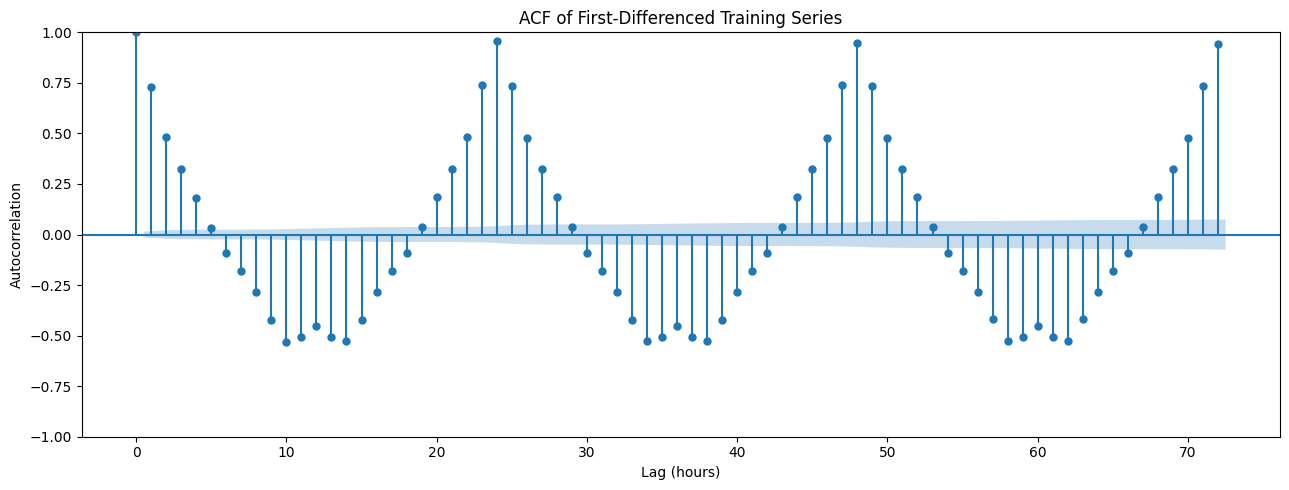

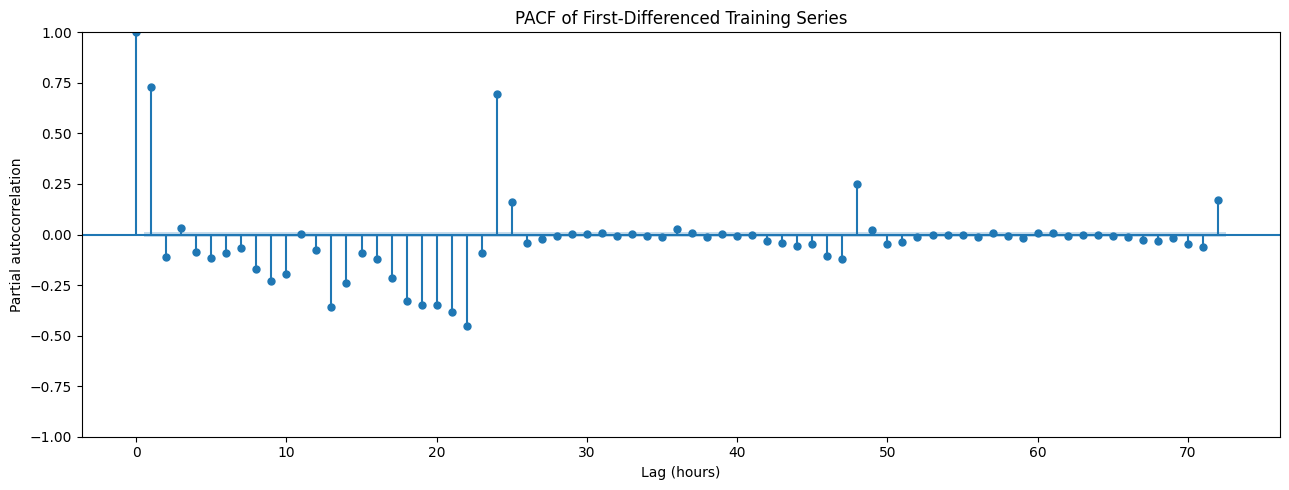

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_acf(train_diff1, lags=72, ax=ax)
ax.set_title("ACF of First-Differenced Training Series")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
plot_pacf(train_diff1, lags=72, method="ywm", ax=ax)
ax.set_title("PACF of First-Differenced Training Series")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Partial autocorrelation")
plt.tight_layout()
plt.show()

### Interpretation of ACF and PACF after First Differencing

The ACF and PACF plots are examined after first differencing to understand the remaining autocorrelation structure.

The plots help identify possible non-seasonal AR and MA relationships that may be considered during ARIMA model selection.

Particular attention is given to the daily lags around 24 and 48 because the observations are hourly. The presence of autocorrelation at these lags would indicate that daily dependence may remain even after ordinary first differencing.

These plots provide guidance for selecting candidate model orders. The final ARIMA order is selected using validation performance rather than relying only on the visual cut-off patterns.

## 25. Optional seasonal differencing diagnostic (24 hours)

The lecture explains that hourly electricity use may have a seasonal period of 24 hours. I therefore inspect a 24-hour seasonal difference as a separate diagnostic:

Δ₂₄Yₜ = Yₜ − Yₜ₋₂₄

This is not the same as ordinary first differencing. I compare the ADF result, plots and remaining seasonal pattern before deciding whether a seasonal difference is justified. I do not combine ordinary and seasonal differencing automatically.

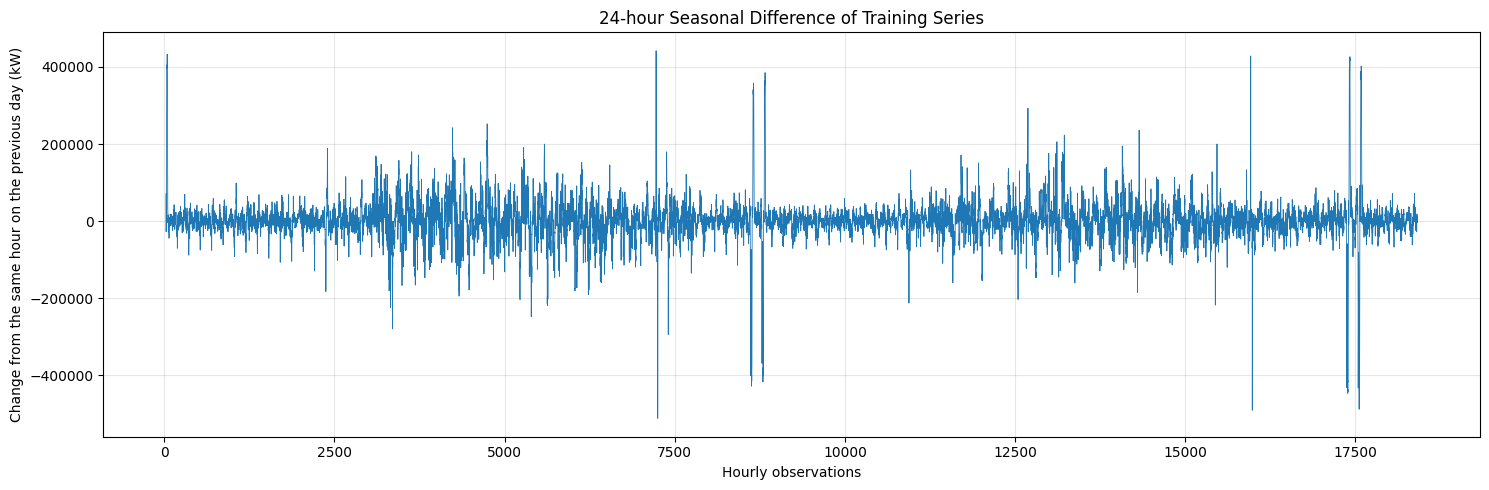

ADF TEST: 24-HOUR SEASONALLY DIFFERENCED SERIES
------------------------------------------------
ADF statistic: -22.798263
p-value: 0.000000
Number of lags used: 45
Number of observations: 18342

The ADF test provides evidence against a unit root after 24-hour seasonal differencing.


In [ ]:
# I subtract the observation from 24 hours earlier to inspect the daily seasonal pattern.
train_seasonal_diff24 = train.diff(24).dropna()

plt.figure(figsize=(15, 5))
plt.plot(train_seasonal_diff24, linewidth=0.6)
plt.title("24-hour Seasonal Difference of Training Series")
plt.xlabel("Hourly observations")
plt.ylabel("Change from the same hour on the previous day (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

adf_seasonal24 = adfuller(train_seasonal_diff24, autolag="AIC")

print("ADF TEST: 24-HOUR SEASONALLY DIFFERENCED SERIES")
print("------------------------------------------------")
print(f"ADF statistic: {adf_seasonal24[0]:.6f}")
print(f"p-value: {adf_seasonal24[1]:.6f}")
print(f"Number of lags used: {adf_seasonal24[2]}")
print(f"Number of observations: {adf_seasonal24[3]}")

if adf_seasonal24[1] < alpha:
    print("\nThe ADF test provides evidence against a unit root after 24-hour seasonal differencing.")
else:
    print("\nThe ADF test does not provide sufficient evidence against a unit root after 24-hour seasonal differencing.")

### Interpretation of the 24-Hour Seasonal Differencing Diagnostic

A separate 24-hour seasonal difference was examined to understand the effect of subtracting the observation recorded at the same hour on the previous day.

The ADF test on the seasonally differenced series produced a statistic of -22.798263 and a p-value reported as 0.000000. This provides evidence against a unit root after seasonal differencing.

However, this result does not by itself establish that seasonal differencing must be included in the final model. Ordinary first differencing has already provided strong stationarity evidence, and the remaining daily autocorrelation is considered separately during SARIMA development.

Therefore, seasonal differencing is treated as a diagnostic at this stage rather than automatically applying both ordinary and seasonal differencing.

## 26. Summary table for my stationarity checks

I collect the test statistics and p-values so that I can compare the original series, first difference and 24-hour seasonal difference. The table records test results; it does not automatically choose the final ARIMA differencing orders for me.

In [ ]:
stationarity_summary = pd.DataFrame([
    {
        "Series": "Original training series",
        "ADF statistic": adf_original[0],
        "ADF p-value": adf_original[1],
        "KPSS statistic": kpss_original[0],
        "KPSS p-value": kpss_original[1]
    },
    {
        "Series": "First difference (d=1)",
        "ADF statistic": adf_diff1[0],
        "ADF p-value": adf_diff1[1],
        "KPSS statistic": kpss_diff1[0],
        "KPSS p-value": kpss_diff1[1]
    },
    {
        "Series": "24-hour seasonal difference",
        "ADF statistic": adf_seasonal24[0],
        "ADF p-value": adf_seasonal24[1],
        "KPSS statistic": np.nan,
        "KPSS p-value": np.nan
    }
])

display(stationarity_summary.round(6))

stationarity_summary.to_csv("stationarity_test_summary.csv", index=False)
print("Saved stationarity_test_summary.csv")

,Series,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value
0,Original training series,-3.245822,0.017481,2.236572,0.01
1,First difference (d=1),-30.264332,0.000000,0.000823,0.10
2,24-hour seasonal difference,-22.798263,0.000000,NaN,NaN


Saved stationarity_test_summary.csv


### Interpretation of the Stationarity Summary Table

The summary table brings together the ADF and KPSS results for the original training series and the differenced series.

For the original series, the ADF p-value was 0.017481, while the KPSS p-value was 0.010000. These results do not provide a completely consistent conclusion because the two tests have different null hypotheses.

After first differencing, the ADF p-value was reported as 0.000000 and the KPSS p-value was 0.100000. Both results provide stronger support for stationarity under their respective test specifications.

The 24-hour seasonally differenced series also produced a very small ADF p-value. However, the table does not contain a KPSS result for this series.

Based on the combined evidence, first-order differencing is retained as the ordinary differencing order for ARIMA development. Daily seasonal dependence is examined separately when developing SARIMA.

## 27. Preliminary Interpretation of the Stationarity Checks

The initial stationarity analysis provides mixed evidence about the original training series. The ADF test with a constant and the KPSS test with a constant produce different conclusions because their null hypotheses are different. Therefore, the results need to be considered together rather than relying on either test independently.

After first-order differencing, the ADF and KPSS results provide stronger evidence of stationarity under the test specifications used. This suggests that first differencing may be appropriate for the ARIMA model.

However, before finalising the differencing decision, I also examine the effect of including a deterministic linear trend in the stationarity tests. The additional checks are presented in the next section.

ADF is a unit-root test and does not, by itself, establish every condition of strict or weak stationarity. The test results are therefore interpreted alongside the time-series plots, rolling statistics and autocorrelation patterns.

### Conclusion from the Stationarity Analysis

The original training series shows changes in its level and variability. The ADF and KPSS tests on the original series also provide different indications depending on the test specification.

After first differencing, the ADF statistic was -30.264332 with a p-value reported as 0.000000. The KPSS statistic was 0.000823 with a p-value of 0.100000. These results provide stronger evidence of stationarity after one ordinary difference.

The 24-hour seasonal differencing diagnostic also produced evidence against a unit root. However, I do not apply seasonal differencing automatically because the ordinary first difference has already provided strong evidence of stationarity.

Therefore, I proceed with d=1 for the ARIMA candidate models. Any remaining daily seasonal structure is considered separately during SARIMA development.

## 28. Additional stationarity check with a deterministic trend

The earlier ADF test used a constant term, while the KPSS check used level stationarity. Because the original-series results were not fully consistent, I now repeat the checks with a deterministic linear trend included.

This is an additional diagnostic. I compare it with the earlier results before deciding whether ordinary differencing is appropriate for the ARIMA model.

In [ ]:
# I check the original training series with a deterministic linear trend.
# regression="ct" includes both a constant and a linear time trend.

adf_original_trend = adfuller(
    train,
    regression="ct",
    autolag="AIC"
)

print("ADF TEST: ORIGINAL TRAINING SERIES WITH TREND")
print("----------------------------------------------")
print(f"ADF statistic: {adf_original_trend[0]:.6f}")
print(f"p-value: {adf_original_trend[1]:.6f}")
print(f"Number of lags used: {adf_original_trend[2]}")
print(f"Number of observations: {adf_original_trend[3]}")

print("Critical values:")
for level, value in adf_original_trend[4].items():
    print(f"  {level}: {value:.6f}")

if adf_original_trend[1] < alpha:
    print("\\nDecision: Reject the unit-root null hypothesis at 5%.")
    print("Interpretation: The test provides evidence against a unit root")
    print("when a deterministic linear trend is included.")
else:
    print("\\nDecision: Fail to reject the unit-root null hypothesis at 5%.")
    print("Interpretation: The test does not provide sufficient evidence")
    print("against a unit root when a deterministic linear trend is included.")


# I run KPSS with a trend-stationarity null as a complementary check.
# regression="ct" tests stationarity around a deterministic linear trend.

kpss_original_trend = kpss(
    train,
    regression="ct",
    nlags="auto"
)

print("\\nKPSS TEST: ORIGINAL TRAINING SERIES WITH TREND")
print("----------------------------------------------")
print(f"KPSS statistic: {kpss_original_trend[0]:.6f}")
print(f"p-value: {kpss_original_trend[1]:.6f}")

if kpss_original_trend[1] < alpha:
    print("\\nDecision: Reject the trend-stationarity null hypothesis at 5%.")
else:
    print("\\nDecision: Fail to reject the trend-stationarity null hypothesis at 5%.")


# I place the additional results together for easier comparison.
trend_test_summary = pd.DataFrame([
    {
        "Test": "ADF with deterministic trend",
        "Statistic": adf_original_trend[0],
        "p-value": adf_original_trend[1],
        "Null hypothesis": "Unit root"
    },
    {
        "Test": "KPSS with deterministic trend",
        "Statistic": kpss_original_trend[0],
        "p-value": kpss_original_trend[1],
        "Null hypothesis": "Trend stationarity"
    }
])

display(trend_test_summary.round(6))

ADF TEST: ORIGINAL TRAINING SERIES WITH TREND
----------------------------------------------
ADF statistic: -3.278341
p-value: 0.069891
Number of lags used: 45
Number of observations: 18366
Critical values:
  1%: -3.959263
  5%: -3.410729
  10%: -3.127191
\nDecision: Fail to reject the unit-root null hypothesis at 5%.
Interpretation: The test does not provide sufficient evidence
against a unit root when a deterministic linear trend is included.
\nKPSS TEST: ORIGINAL TRAINING SERIES WITH TREND
----------------------------------------------
KPSS statistic: 1.946934
p-value: 0.010000
\nDecision: Reject the trend-stationarity null hypothesis at 5%.


/tmp/ipykernel_1803/2102596180.py:34: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_original_trend = kpss(


,Test,Statistic,p-value,Null hypothesis
0,ADF with deterministic trend,-3.278341,0.069891,Unit root
1,KPSS with deterministic trend,1.946934,0.010000,Trend stationarity


### Interpretation of the Stationarity Tests with a Deterministic Trend

The additional ADF test was performed with both a constant and a deterministic linear trend.

The ADF statistic was -3.278341 and the p-value was 0.069891. Since the p-value is above 0.05, I fail to reject the unit-root null hypothesis at the 5% significance level.

The KPSS test with a deterministic trend produced a statistic of 1.946934 and a p-value of 0.010000. This leads to rejection of the null hypothesis of trend stationarity.

These results indicate that the original series requires careful interpretation, particularly when a deterministic trend is included in the test specification.

The first-differenced series provides stronger stationarity evidence in the earlier ADF and KPSS tests. Therefore, I retain d=1 as the starting differencing order for ARIMA model development.

## 29. Interpretation of the Stationarity Test Results

The stationarity tests on the original training series did not provide completely consistent results. Therefore, the ADF and KPSS results were examined together, considering their different null hypotheses.

The ADF test with a constant produced a statistic of -3.245822 and a p-value of 0.017481. At the 5% significance level, I rejected the unit-root null hypothesis. However, the KPSS test with a constant produced a statistic of 2.236572 and a p-value of 0.010000, leading to rejection of the level-stationarity null hypothesis.

To examine whether the inclusion of a deterministic trend affected the results, I performed the tests again. The ADF test with a constant and trend produced a p-value of 0.069891. Therefore, I failed to reject the unit-root null hypothesis at the 5% level. The KPSS test with a trend produced a p-value of 0.010000, leading to rejection of the trend-stationarity null hypothesis.

After first differencing, the ADF statistic was -30.264332 with a p-value reported as 0.000000, while the KPSS statistic was 0.000823 with a p-value of 0.100000. These results provide stronger evidence that the first-differenced series is stationary under the test specifications used.

Based on the combined results, I selected first differencing as the starting point for ARIMA modelling, using an ordinary differencing order of d=1. I also considered the remaining autocorrelation and daily seasonal pattern separately during the development of the SARIMA model.

The results are interpreted together because the ADF and KPSS tests have different null hypotheses. Neither test alone establishes every aspect of stationarity.

**Next stage:** The stationarity and autocorrelation findings are used to select candidate ARIMA(p,d,q) models. The same chronological training, validation and test boundaries are retained, with the test set reserved for final evaluation.

## 30. ARIMA model development

I use the first difference order selected from the stationarity checks as the starting value, so the candidate models have d=1. I compare a small set of AR and MA orders using the validation period. The validation set is used for model selection; I do not use the test set to choose p or q.

The forecasts are one-step-ahead forecasts. After each validation observation becomes available, I update the model state with that observed value without re-estimating the parameters. This matches the one-step-ahead evaluation approach used for the project.

The candidate search considers p and q values from 0 to 3 while keeping d=1. This gives 16 candidate ARIMA configurations. I use validation RMSE to select the order, while also recording validation MAE and the training-fit AIC for reference.

In [ ]:
# I import the ARIMA model and the metrics needed for comparison.
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

# I confirm that the existing time-ordered split is still being used.
print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

assert len(train) == 18412
assert len(validation) == 3945
assert len(test) == 3947

# I use d=1 based on the combined stationarity checks.
d = 1

# I compare modest p and q values first rather than increasing the
# model complexity unnecessarily.
candidate_orders = [
    (p, d, q)
    for p in range(4)
    for q in range(4)
]

print("Candidate ARIMA orders:", candidate_orders)

Training: 18412
Validation: 3945
Test: 3947
Candidate ARIMA orders: [(0, 1, 0), (0, 1, 1), (0, 1, 2), (0, 1, 3), (1, 1, 0), (1, 1, 1), (1, 1, 2), (1, 1, 3), (2, 1, 0), (2, 1, 1), (2, 1, 2), (2, 1, 3), (3, 1, 0), (3, 1, 1), (3, 1, 2), (3, 1, 3)]


## 31. Validation-based selection of p and q

For every candidate order, I fit the model on the training observations. I then predict the next validation observation, add the actual validation observation to the model's information set, and continue one step at a time.

I select the order with the lowest validation RMSE. The test set remains unused during this selection.

In [ ]:
# I calculate sequential one-step-ahead forecasts for each candidate.
def one_step_ahead_forecast(fitted_model, observed_values):
    predictions = []

    for actual_value in observed_values:
        next_prediction = fitted_model.forecast(steps=1)
        predictions.append(float(np.asarray(next_prediction).reshape(-1)[0]))

        # I update the model with the newly observed value without refitting
        # the ARIMA parameters at every time step.
        fitted_model = fitted_model.append(
            endog=[float(actual_value)],
            refit=False
        )

    return np.asarray(predictions)


validation_results = []

for order in candidate_orders:
    try:
        model = ARIMA(
            train,
            order=order,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fitted = model.fit()

        validation_predictions = one_step_ahead_forecast(
            fitted,
            validation.to_numpy()
        )

        rmse = np.sqrt(mean_squared_error(validation, validation_predictions))
        mae = mean_absolute_error(validation, validation_predictions)

        validation_results.append({
            "Order": order,
            "p": order[0],
            "d": order[1],
            "q": order[2],
            "Validation RMSE": rmse,
            "Validation MAE": mae,
            "AIC (training fit)": fitted.aic
        })

        print(f"Completed ARIMA{order}: validation RMSE = {rmse:.4f}")

    except Exception as error:
        print(f"ARIMA{order} could not be fitted: {error}")


validation_comparison = pd.DataFrame(validation_results)

if validation_comparison.empty:
    raise RuntimeError("None of the candidate ARIMA models could be fitted.")

validation_comparison = validation_comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)

display(validation_comparison.round(4))

best_order = tuple(validation_comparison.loc[0, "Order"])
print("Selected ARIMA order based on validation RMSE:", best_order)

Completed ARIMA(0, 1, 0): validation RMSE = 83758.6975
Completed ARIMA(0, 1, 1): validation RMSE = 61618.2876
Completed ARIMA(0, 1, 2): validation RMSE = 56114.9974
Completed ARIMA(0, 1, 3): validation RMSE = 54811.3178
Completed ARIMA(1, 1, 0): validation RMSE = 53999.5319
Completed ARIMA(1, 1, 1): validation RMSE = 53441.6164
Completed ARIMA(1, 1, 2): validation RMSE = 53458.5037
Completed ARIMA(1, 1, 3): validation RMSE = 53472.0172
Completed ARIMA(2, 1, 0): validation RMSE = 53467.9041
Completed ARIMA(2, 1, 1): validation RMSE = 53470.3347
Completed ARIMA(2, 1, 2): validation RMSE = 48961.1397
Completed ARIMA(2, 1, 3): validation RMSE = 43690.8115
Completed ARIMA(3, 1, 0): validation RMSE = 53469.6618
Completed ARIMA(3, 1, 1): validation RMSE = 53469.0385
Completed ARIMA(3, 1, 2): validation RMSE = 66679.2339
Completed ARIMA(3, 1, 3): validation RMSE = 43716.2191


,Order,p,d,q,Validation RMSE,Validation MAE,AIC (training fit)
0,"(2, 1, 3)",2,1,3,43690.8115,31171.0558,454075.2017
1,"(3, 1, 3)",3,1,3,43716.2191,31422.0481,453954.0354
2,"(2, 1, 2)",2,1,2,48961.1397,34316.2082,456612.2153
3,"(1, 1, 1)",1,1,1,53441.6164,35162.4062,459264.7715
4,"(1, 1, 2)",1,1,2,53458.5037,35252.6374,459228.6551
5,"(2, 1, 0)",2,1,0,53467.9041,35117.3870,459289.6893
6,"(3, 1, 1)",3,1,1,53469.0385,35263.7733,459223.7687
7,"(3, 1, 0)",3,1,0,53469.6618,35239.5015,459246.3861
8,"(2, 1, 1)",2,1,1,53470.3347,35271.0885,459245.8143
9,"(1, 1, 3)",1,1,3,53472.0172,35270.5527,459171.7283


Selected ARIMA order based on validation RMSE: (2, 1, 3)


### Interpretation of the ARIMA Validation Results

The 16 candidate ARIMA configurations were compared using sequential one-step-ahead forecasts on the validation dataset.

ARIMA(2,1,3) achieved the lowest validation RMSE of 43,690.8115, followed by ARIMA(3,1,3), which recorded a validation RMSE of 43,716.2191.

Although the difference between these two models is relatively small, ARIMA(2,1,3) recorded the lowest validation RMSE among the candidates examined. Therefore, I selected ARIMA(2,1,3) for the subsequent test evaluation.

The test dataset was not used during this selection process. This helps maintain a separate evaluation period for assessing the selected model.

## 32. Final test evaluation of the selected ARIMA model

After selecting p and q on the validation set, I fit the selected model again using the combined training and validation observations. I then evaluate it on the test period using sequential one-step-ahead forecasts.

The model parameters are not re-estimated during the test loop. The model is updated with each newly observed value so that the next prediction uses only information that would have been available at that time.

This evaluation uses the combined training and validation observations to fit the selected ARIMA model before the test period. It is an additional evaluation after model selection. For the final comparison with SARIMA and the other forecasting models, I use the matched ARIMA evaluation presented later in Section 38, where both ARIMA and SARIMA follow the same training and validation procedure. This keeps the final model comparison consistent.

In [ ]:
# I combine training and validation data after model selection.
train_validation = pd.concat(
    [train, validation],
    ignore_index=True
)

# I fit the selected ARIMA model on all data available before the test period.
final_arima = ARIMA(
    train_validation,
    order=best_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_arima_fit = final_arima.fit()

# I generate one-step-ahead forecasts across the test period.
test_predictions = one_step_ahead_forecast(
    final_arima_fit,
    test.to_numpy()
)

# I calculate the required test metrics.
test_rmse = np.sqrt(mean_squared_error(test, test_predictions))
test_mae = mean_absolute_error(test, test_predictions)

# MAPE is calculated with a small denominator guard in case any actual
# observation is zero.
actual_test = test.to_numpy()
nonzero_mask = np.abs(actual_test) > 1e-8

if nonzero_mask.any():
    test_mape = np.mean(
        np.abs(
            (actual_test[nonzero_mask] - test_predictions[nonzero_mask])
            / actual_test[nonzero_mask]
        )
    ) * 100
else:
    test_mape = np.nan

test_r2 = r2_score(test, test_predictions)

arima_test_metrics = pd.DataFrame([{
    "Model": f"ARIMA{best_order}",
    "Test RMSE": test_rmse,
    "Test MAE": test_mae,
    "Test MAPE (%)": test_mape,
    "Test R2": test_r2
}])

display(arima_test_metrics.round(4))

,Model,Test RMSE,Test MAE,Test MAPE (%),Test R2
0,"ARIMA(2, 1, 3)",56954.7051,39420.5678,5.0443,0.9714


### Interpretation of the ARIMA Test Results

The selected ARIMA(2,1,3) model was evaluated on the test dataset using sequential one-step-ahead forecasts.

The model recorded the following test performance:

- RMSE: 56,954.7051
- MAE: 39,420.5678
- MAPE: 5.0443%
- R²: 0.9714

The results indicate that the model explains a substantial proportion of the variation in the test observations, as reflected by the R² value. The RMSE and MAE represent the magnitude of the forecasting errors, while MAPE expresses the average percentage error.

These results provide the test performance for this particular ARIMA evaluation. The later matched ARIMA–SARIMA comparison in Section 38 uses a common evaluation procedure and should be used when comparing the two models directly.

## 33. Plot actual and predicted test consumption

I compare the actual test observations with the one-step-ahead ARIMA predictions. I also plot a shorter section of the test period so that the hourly pattern can be examined more clearly.

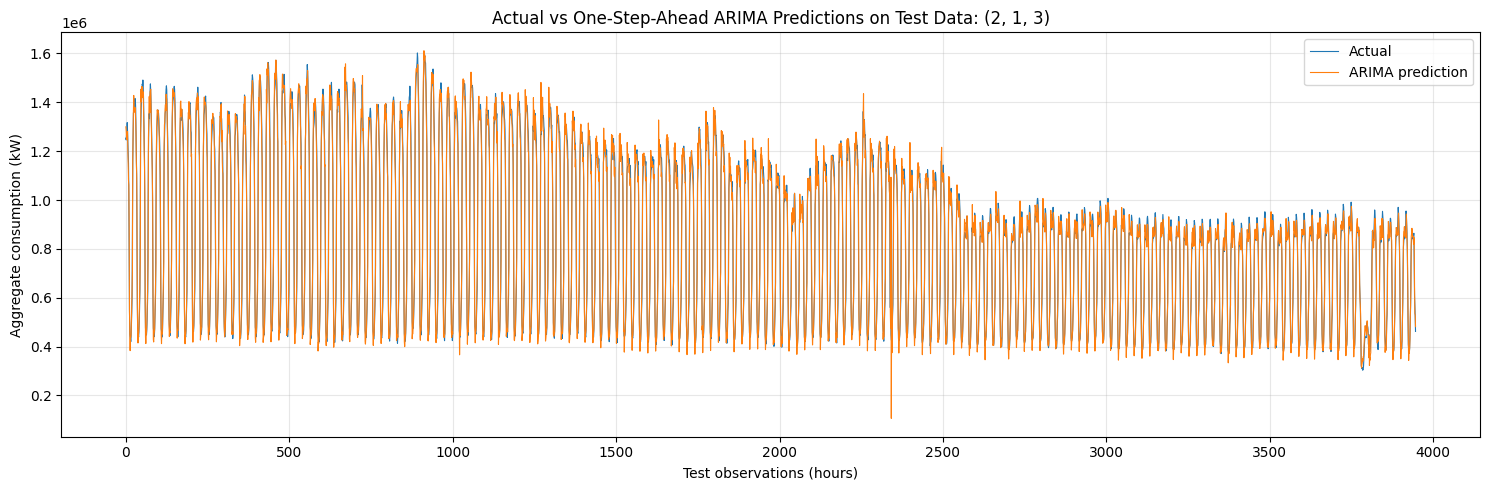

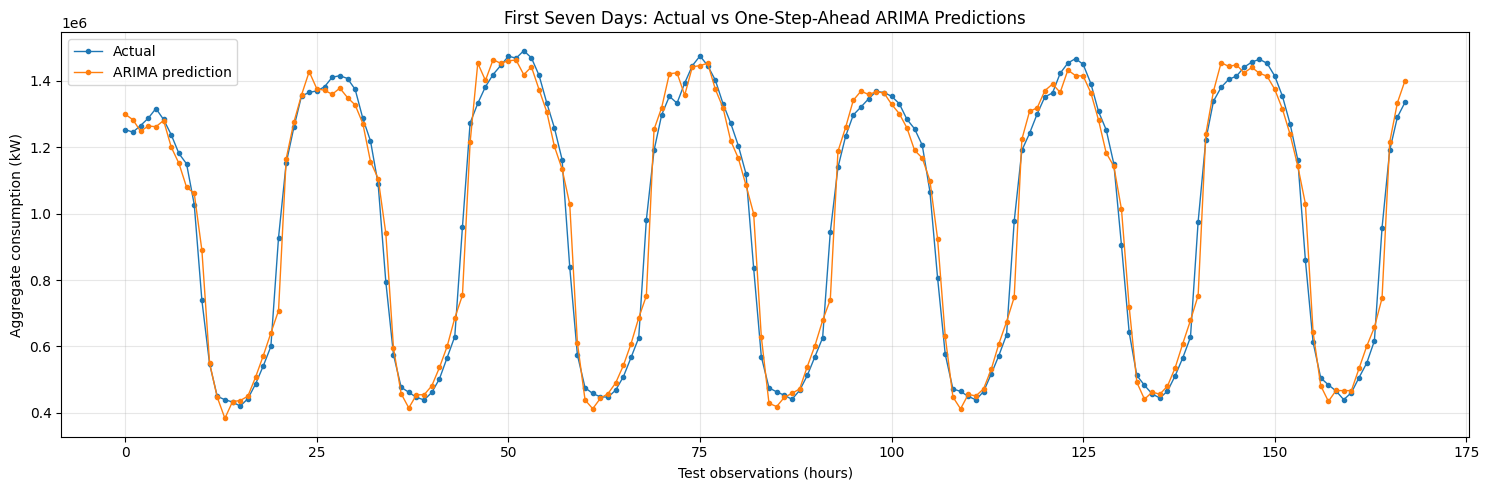

In [ ]:
# I plot the full test period.
plt.figure(figsize=(15, 5))
plt.plot(test.to_numpy(), label="Actual", linewidth=0.8)
plt.plot(test_predictions, label="ARIMA prediction", linewidth=0.8)
plt.title(f"Actual vs One-Step-Ahead ARIMA Predictions on Test Data: {best_order}")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# I zoom in on the first seven days of the test period.
hours_to_plot = min(24 * 7, len(test))

plt.figure(figsize=(15, 5))
plt.plot(
    test.to_numpy()[:hours_to_plot],
    label="Actual",
    marker=".",
    linewidth=1
)
plt.plot(
    test_predictions[:hours_to_plot],
    label="ARIMA prediction",
    marker=".",
    linewidth=1
)
plt.title("First Seven Days: Actual vs One-Step-Ahead ARIMA Predictions")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the Actual and Predicted Test Plots

The plots compare the actual hourly electricity consumption with the one-step-ahead forecasts generated by ARIMA(2,1,3).

The full test-period plot provides an overall view of the model's forecasting behaviour, while the first-seven-days plot gives a closer view of the hourly variations.

The comparison helps identify how closely the forecasts follow changes in actual consumption. It also makes it easier to observe periods where the predicted values differ from the actual values, particularly during larger fluctuations.

The visual results should be interpreted together with the numerical test metrics reported in Section 32. The plots provide a qualitative assessment, while RMSE, MAE, MAPE and R² provide numerical measures of forecasting performance.

## 34. Interpretation of the ARIMA Results

The selected ARIMA model was ARIMA(2,1,3). In the separate test evaluation presented in Section 32, it recorded an RMSE of 56,954.71, MAE of 39,420.57, MAPE of 5.0443% and R² of 0.9714.

The actual-versus-predicted plots provide a visual comparison of the model's forecasts with the observed electricity consumption. The numerical metrics provide a more direct way to measure the forecasting errors.

The ARIMA model provides a useful baseline for comparison with the seasonal and neural-network models. Its performance is examined further through residual diagnostics and the matched ARIMA–SARIMA comparison in Section 38.

The validation dataset was used to select the model order, while the test dataset was retained for evaluation.


## 35. Residual diagnostics for the selected ARIMA model

After selecting ARIMA(2,1,3), I examine its residuals to check whether the model has captured the main patterns in the training and validation data.

A residual is the difference between an observed value and its fitted value. If the model has captured the important time-dependent structure, the remaining residuals should not show strong systematic autocorrelation.

I use a residual time-series plot, histogram, residual ACF and the Ljung–Box test. I conduct these diagnostics using the fitted model on the data available before the test period. The test observations remain reserved for final model evaluation.


Number of residual observations: 22357
Residual mean: -152.3881
Residual standard deviation: 52704.1533


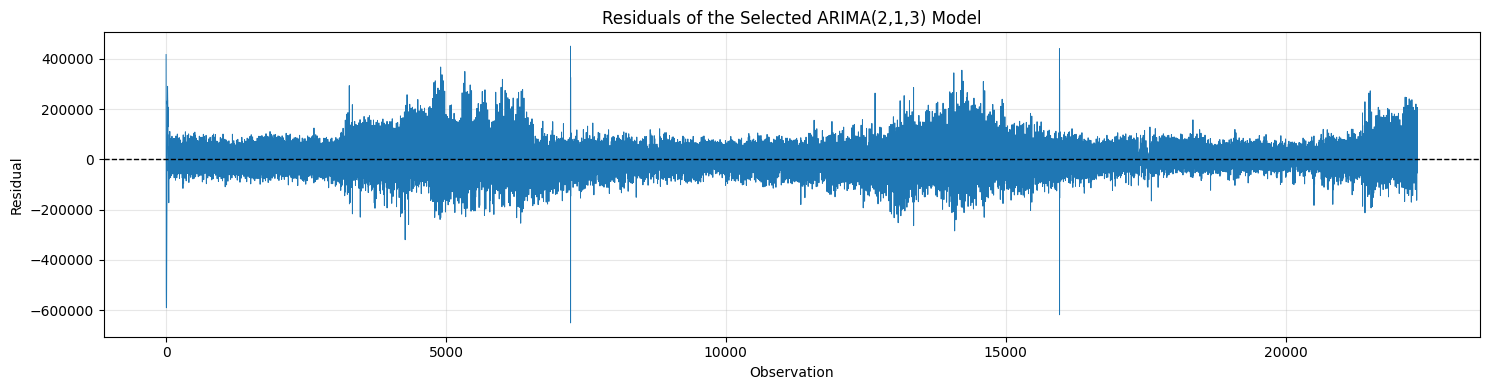

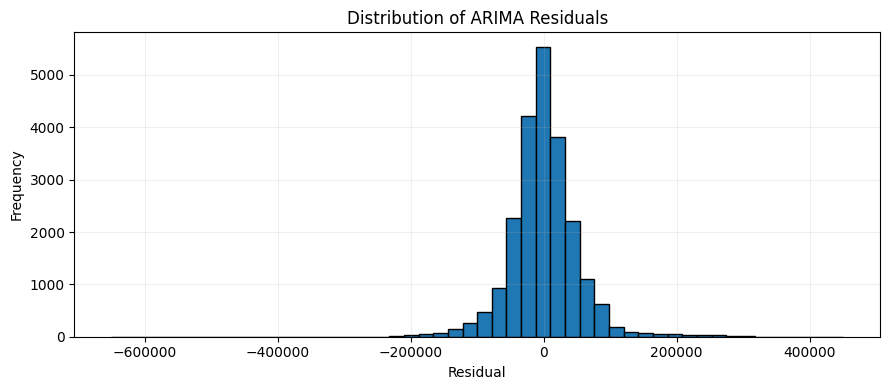

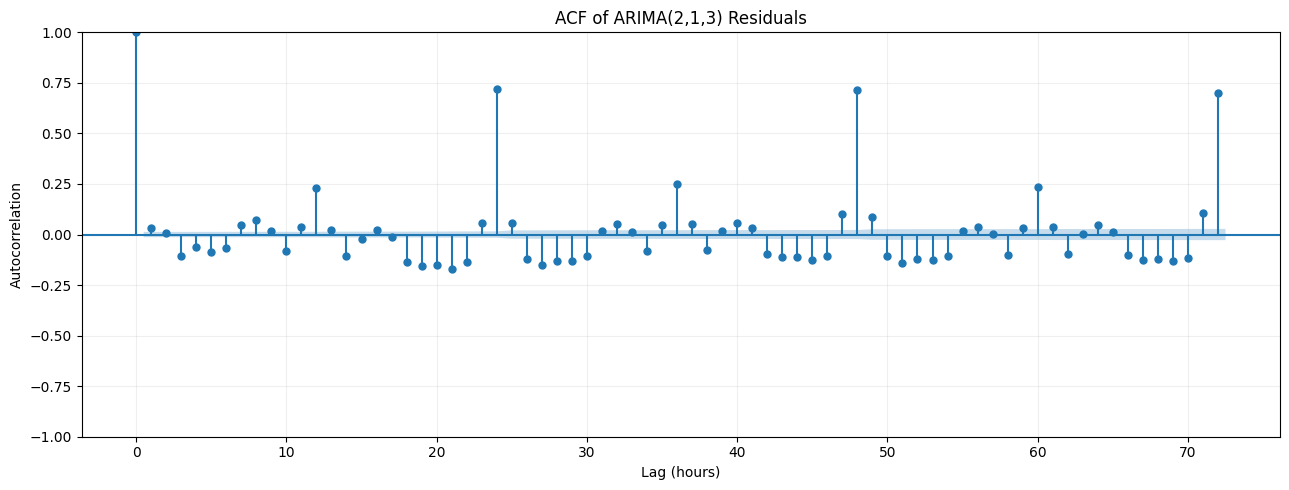

,lb_stat,lb_pvalue
24,16624.572353,0.0
48,33604.552743,0.0


ARIMA convergence information:
{'fopt': np.float64(12.300909811836787), 'gopt': array([ 2.08597690e-03,  1.47413903e-03, -1.06187414e-04, -2.69705858e-04,
       -3.92470056e-04,  4.34976352e-06]), 'fcalls': 343, 'warnflag': 0, 'converged': True, 'iterations': 35}


In [ ]:

# I obtain the residuals from the final ARIMA model fitted on
# the training and validation observations.
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

arima_residuals = pd.Series(final_arima_fit.resid).dropna()

print("Number of residual observations:", len(arima_residuals))
print("Residual mean:", round(arima_residuals.mean(), 4))
print("Residual standard deviation:", round(arima_residuals.std(), 4))

# I plot the residuals in their original time order.
plt.figure(figsize=(15, 4))
plt.plot(arima_residuals.to_numpy(), linewidth=0.7)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Residuals of the Selected ARIMA(2,1,3) Model")
plt.xlabel("Observation")
plt.ylabel("Residual")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# I examine the distribution of the residuals.
plt.figure(figsize=(9, 4))
plt.hist(arima_residuals, bins=50, edgecolor="black")
plt.title("Distribution of ARIMA Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# I inspect residual autocorrelation at different hourly lags.
fig, ax = plt.subplots(figsize=(13, 5))
plot_acf(arima_residuals, lags=72, ax=ax)
ax.set_title("ACF of ARIMA(2,1,3) Residuals")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# I use the Ljung-Box test to examine residual autocorrelation
# jointly at 24-hour and 48-hour lags.
# model_df = p + q = 2 + 3 = 5.
ljung_box_results = acorr_ljungbox(
    arima_residuals,
    lags=[24, 48],
    model_df=5,
    return_df=True
)

display(ljung_box_results)

# I check whether the ARIMA estimation process converged.
print("ARIMA convergence information:")
print(final_arima_fit.mle_retvals)

### Interpretation of the ARIMA Residual Diagnostics

The residual analysis was performed on 22,357 observations from the fitted ARIMA model.

The residual mean was -152.39, which is relatively small compared with the residual standard deviation of 52,704.15. However, the residual standard deviation indicates that considerable variation remains unexplained.

The Ljung–Box test produced statistics of 16,624.57 at lag 24 and 33,604.55 at lag 48, with p-values below 0.05. Therefore, the null hypothesis of no autocorrelation is rejected at both lags.

This indicates that the ARIMA model has not captured all the temporal dependence in the series. The remaining autocorrelation at daily intervals suggests that a seasonal model may provide a better fit.

The model convergence information also indicates that the ARIMA estimation completed successfully. However, convergence alone does not mean that all residual patterns have been explained.

Based on these diagnostics, I proceed to examine whether adding seasonal AR and MA terms can improve forecasting performance.


## 36. Seasonal ARIMA (SARIMA) model development

The residual ACF of the selected ARIMA model shows strong autocorrelation at lags 24, 48 and 72. Since the observations represent hourly electricity consumption, these lags correspond to daily seasonal intervals.

I therefore investigate whether adding seasonal autoregressive and moving-average terms improves one-step-ahead forecasting.

I initially retain d=1 and use a daily seasonal period of s=24. I compare candidate models using the same training and validation periods used for ARIMA. The validation RMSE is used to select the model.


In [ ]:

# I use SARIMAX to estimate seasonal ARIMA models.
from statsmodels.tsa.statespace.sarimax import SARIMAX

# I use the selected non-seasonal ARIMA order as the starting point.
# The seasonal period is 24 because the data is recorded hourly.
seasonal_period = 24

# I begin with a small set of daily seasonal specifications.
# D=0 is retained initially because first differencing was already used.
seasonal_candidates = [
    (1, 0, 0, seasonal_period),
    (0, 0, 1, seasonal_period),
    (1, 0, 1, seasonal_period)
]

sarima_validation_results = []

for seasonal_order in seasonal_candidates:
    try:
        model = SARIMAX(
            train,
            order=best_order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(disp=False, maxiter=100)

        # I evaluate the model using sequential one-step-ahead forecasts.
        validation_predictions = one_step_ahead_forecast(
            fitted,
            validation.to_numpy()
        )

        rmse = np.sqrt(
            mean_squared_error(validation, validation_predictions)
        )
        mae = mean_absolute_error(validation, validation_predictions)

        sarima_validation_results.append({
            "ARIMA order": best_order,
            "Seasonal order": seasonal_order,
            "Validation RMSE": rmse,
            "Validation MAE": mae,
            "AIC (training fit)": fitted.aic,
            "Converged": fitted.mle_retvals.get("converged", False)
        })

        print(
            f"Completed SARIMA{best_order}x{seasonal_order}: "
            f"Validation RMSE = {rmse:.4f}"
        )

    except Exception as error:
        print(
            f"SARIMA{best_order}x{seasonal_order} could not be fitted: "
            f"{error}"
        )

sarima_validation_comparison = pd.DataFrame(
    sarima_validation_results
)

if sarima_validation_comparison.empty:
    raise RuntimeError("None of the SARIMA candidates could be fitted.")

sarima_validation_comparison = (
    sarima_validation_comparison
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
)

display(sarima_validation_comparison.round(4))

best_seasonal_order = tuple(
    sarima_validation_comparison.loc[0, "Seasonal order"]
)

print("Selected seasonal order:", best_seasonal_order)

Completed SARIMA(2, 1, 3)x(1, 0, 0, 24): Validation RMSE = 19413.5499
Completed SARIMA(2, 1, 3)x(0, 0, 1, 24): Validation RMSE = 32434.3722
Completed SARIMA(2, 1, 3)x(1, 0, 1, 24): Validation RMSE = 18005.8744


,ARIMA order,Seasonal order,Validation RMSE,Validation MAE,AIC (training fit),Converged
0,"(2, 1, 3)","(1, 0, 1, 24)",18005.8744,11818.6938,442257.6561,True
1,"(2, 1, 3)","(1, 0, 0, 24)",19413.5499,12988.8740,442958.3930,True
2,"(2, 1, 3)","(0, 0, 1, 24)",32434.3722,23044.4387,447665.8368,True


Selected seasonal order: (1, 0, 1, 24)


In [ ]:

# RESTORE SELECTED SARIMA MODEL SETTINGS

# Restore the orders selected during the completed validation.
best_order = (2, 1, 3)
best_seasonal_order = (1, 0, 1, 24)

# Verify that the dataset and split are available.
assert len(train) == 18412, "Training data is not restored correctly."
assert len(validation) == 3945, "Validation data is not restored correctly."
assert len(test) == 3947, "Test data is not restored correctly."

print("SARIMA settings restored successfully.")
print("ARIMA order:", best_order)
print("Seasonal order:", best_seasonal_order)
print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Test observations:", len(test))


SARIMA settings restored successfully.
ARIMA order: (2, 1, 3)
Seasonal order: (1, 0, 1, 24)
Training observations: 18412
Validation observations: 3945
Test observations: 3947


### Interpretation of the SARIMA Validation Results

Three seasonal configurations were compared while retaining the selected non-seasonal ARIMA order of (2,1,3) and a daily seasonal period of 24 hours.

The SARIMA(2,1,3) × (1,0,1,24) configuration recorded the lowest validation RMSE of 18,005.87, compared with 19,413.55 for (1,0,0,24) and 32,434.37 for (0,0,1,24).

The selected configuration also recorded the lowest validation MAE among the three candidates. All three candidate models were reported as converged.

Therefore, I selected SARIMA(2,1,3) × (1,0,1,24) for final test evaluation.

The seasonal AR and MA terms allow the model to account for recurring daily dependence that remained in the ARIMA residual diagnostics.

The selected configuration is retained for the final evaluation in the next section.

## 37. Final SARIMA test evaluation

I fit the selected SARIMA model using the training observations. I then incorporate the validation observations sequentially without re-estimating the model parameters. Finally, I generate one-step-ahead predictions for the test period.

This approach preserves the chronological order of the observations and keeps the test period separate from model selection.

In [ ]:

# I fit the selected SARIMA model on the training observations.
final_sarima = SARIMAX(
    train,
    order=best_order,
    seasonal_order=best_seasonal_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_sarima_fit = final_sarima.fit(
    disp=False,
    maxiter=100
)

print("Model converged:",
      final_sarima_fit.mle_retvals.get("converged", False))

# I update the fitted model state using validation observations.
# The estimated model parameters remain fixed.
sarima_after_validation = final_sarima_fit.extend(
    validation.to_numpy()
)

# I generate sequential one-step-ahead test predictions.
sarima_test_results = sarima_after_validation.extend(
    test.to_numpy()
)

sarima_test_predictions = np.asarray(
    sarima_test_results.fittedvalues
).reshape(-1)

# I verify that the prediction count matches the test observations.
assert len(sarima_test_predictions) == len(test)

# I calculate the test performance metrics.
actual_test = test.to_numpy()

sarima_test_rmse = np.sqrt(
    mean_squared_error(actual_test, sarima_test_predictions)
)

sarima_test_mae = mean_absolute_error(
    actual_test, sarima_test_predictions
)

nonzero_mask = np.abs(actual_test) > 1e-8

sarima_test_mape = (
    np.mean(
        np.abs(
            (actual_test[nonzero_mask] -
             sarima_test_predictions[nonzero_mask])
            / actual_test[nonzero_mask]
        )
    ) * 100
    if nonzero_mask.any()
    else np.nan
)

sarima_test_r2 = r2_score(
    actual_test, sarima_test_predictions
)

sarima_test_metrics = pd.DataFrame([{
    "Model": f"SARIMA{best_order}x{best_seasonal_order}",
    "Test RMSE": sarima_test_rmse,
    "Test MAE": sarima_test_mae,
    "Test MAPE (%)": sarima_test_mape,
    "Test R2": sarima_test_r2
}])

display(sarima_test_metrics.round(4))


Model converged: True


,Model,Test RMSE,Test MAE,Test MAPE (%),Test R2
0,"SARIMA(2, 1, 3)x(1, 0, 1, 24)",23891.4576,14366.7394,1.811,0.995


In [ ]:
# ============================================================
# SARIMA: SAVE AND DOWNLOAD ALL IMPORTANT MODEL OUTPUTS
# Run immediately after the SARIMA test-evaluation cell in Section 37.
# ============================================================
import os
import json
import zipfile
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

from statsmodels.tsa.statespace.sarimax import SARIMAXResults
from google.colab import files

# ------------------------------------------------------------
# 1. Verify that SARIMA results are available
# ------------------------------------------------------------

required_objects = [
    "final_sarima_fit",
    "sarima_after_validation",
    "sarima_test_results",
    "sarima_test_predictions"
]

for obj in required_objects:
    if obj not in globals():
        raise ValueError(
    f"{obj} is not available. Run the SARIMA test-evaluation cell in Section 37 successfully first."
)

assert len(sarima_test_predictions) == len(test)

# ------------------------------------------------------------
# 2. Prepare validation and test prediction files
# ------------------------------------------------------------

validation_start = len(train)
validation_end = validation_start + len(validation)

test_start = validation_end
test_end = test_start + len(test)

validation_predictions = np.asarray(
    sarima_after_validation.fittedvalues
).reshape(-1)

test_predictions = np.asarray(
    sarima_test_predictions
).reshape(-1)

assert len(validation_predictions) == len(validation)
assert len(test_predictions) == len(test)

validation_df = pd.DataFrame({
    "timestamp": pd.to_datetime(
        df["timestamp"].iloc[validation_start:validation_end]
    ).to_numpy(),
    "actual_demand_kW": np.asarray(validation, dtype=float),
    "sarima_forecast_kW": validation_predictions
})

test_df = pd.DataFrame({
    "timestamp": pd.to_datetime(
        df["timestamp"].iloc[test_start:test_end]
    ).to_numpy(),
    "actual_demand_kW": np.asarray(test, dtype=float),
    "sarima_forecast_kW": test_predictions
})

# This is the exact input file required by Section 46.
test_df.to_csv("SARIMA_Test_Predictions.csv", index=False)

validation_df.to_csv(
    "SARIMA_Validation_Predictions.csv", index=False
)

# ------------------------------------------------------------
# 3. Save test-set evaluation metrics
# ------------------------------------------------------------

actual_test = np.asarray(test, dtype=float)

metrics_df = pd.DataFrame([{
    "Model": "SARIMA(2,1,3)x(1,0,1,24)",
    "RMSE": np.sqrt(mean_squared_error(
        actual_test, test_predictions
    )),
    "MAE": mean_absolute_error(
        actual_test, test_predictions
    ),
    "MAPE (%)": mean_absolute_percentage_error(
        actual_test, test_predictions
    ) * 100,
    "R2": r2_score(actual_test, test_predictions),
    "Test observations": len(test)
}])

metrics_df.to_csv(
    "SARIMA_Test_Evaluation_Metrics.csv", index=False
)

# ------------------------------------------------------------
# 4. Save fitted model parameters
# ------------------------------------------------------------

parameters_df = pd.DataFrame({
    "Parameter": final_sarima_fit.params.index,
    "Estimated Value": final_sarima_fit.params.values
})

parameters_df.to_csv(
    "SARIMA_Fitted_Parameters.csv", index=False
)

# ------------------------------------------------------------
# 5. Save the complete fitted SARIMA model
# ------------------------------------------------------------

model_filename = "SARIMA_Fitted_Model.pkl"

final_sarima_fit.save(model_filename)

# This model can later be restored without fitting it again:
# restored_sarima_model = SARIMAXResults.load(model_filename)

# ------------------------------------------------------------
# 6. Save model summary and configuration
# ------------------------------------------------------------

with open("SARIMA_Model_Summary.txt", "w") as f:
    f.write(final_sarima_fit.summary().as_text())

configuration = {
    "Model": "SARIMA",
    "Order": list(best_order),
    "Seasonal Order": list(best_seasonal_order),
    "Seasonal Period": 24,
    "Training observations": len(train),
    "Validation observations": len(validation),
    "Test observations": len(test),
    "Trend": "n",
    "Enforce stationarity": False,
    "Enforce invertibility": False
}

with open("SARIMA_Model_Configuration.json", "w") as f:
    json.dump(configuration, f, indent=4)

# ------------------------------------------------------------
# 7. Create a ZIP archive containing all important files
# ------------------------------------------------------------

output_files = [
    "SARIMA_Test_Predictions.csv",
    "SARIMA_Validation_Predictions.csv",
    "SARIMA_Test_Evaluation_Metrics.csv",
    "SARIMA_Fitted_Parameters.csv",
    "SARIMA_Fitted_Model.pkl",
    "SARIMA_Model_Summary.txt",
    "SARIMA_Model_Configuration.json"
]

zip_filename = "Complete_SARIMA_Model_and_Results.zip"

with zipfile.ZipFile(
    zip_filename, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in output_files:
        if not os.path.exists(filename):
            raise FileNotFoundError(filename)

        zip_file.write(filename)

# ------------------------------------------------------------
# 8. Display metrics and download
# ------------------------------------------------------------

display(metrics_df)

files.download(zip_filename)

print("All SARIMA model files and results have been saved.")


,Model,RMSE,MAE,MAPE (%),R2,Test observations
0,"SARIMA(2,1,3)x(1,0,1,24)",23891.457607,14366.739427,1.81101,0.99496,3947


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All SARIMA model files and results have been saved.


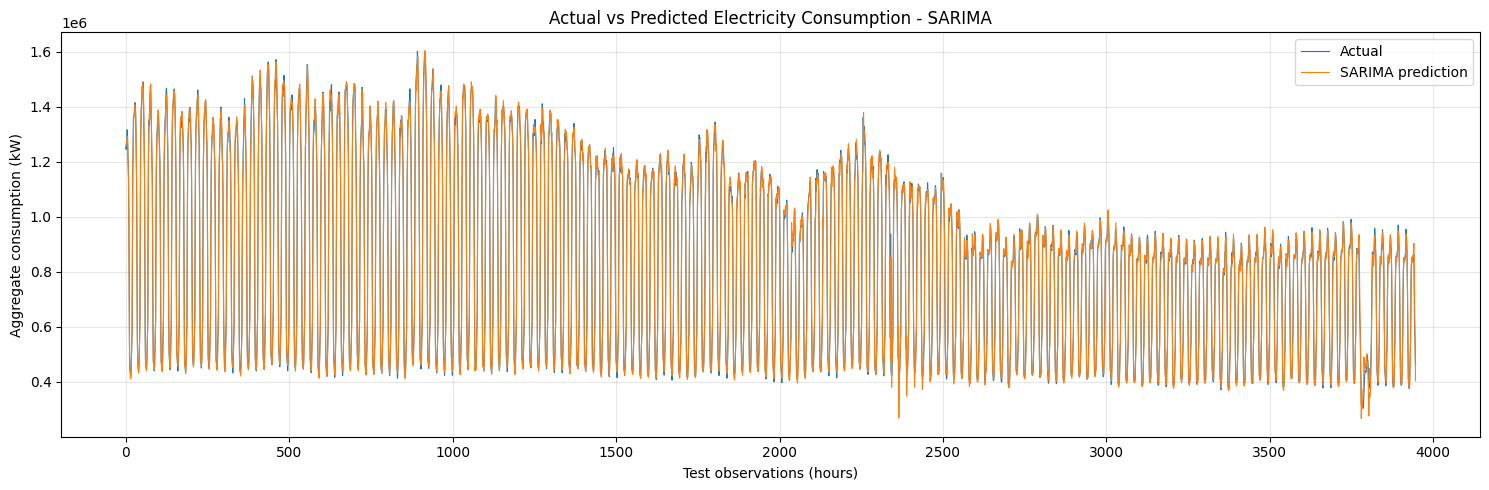

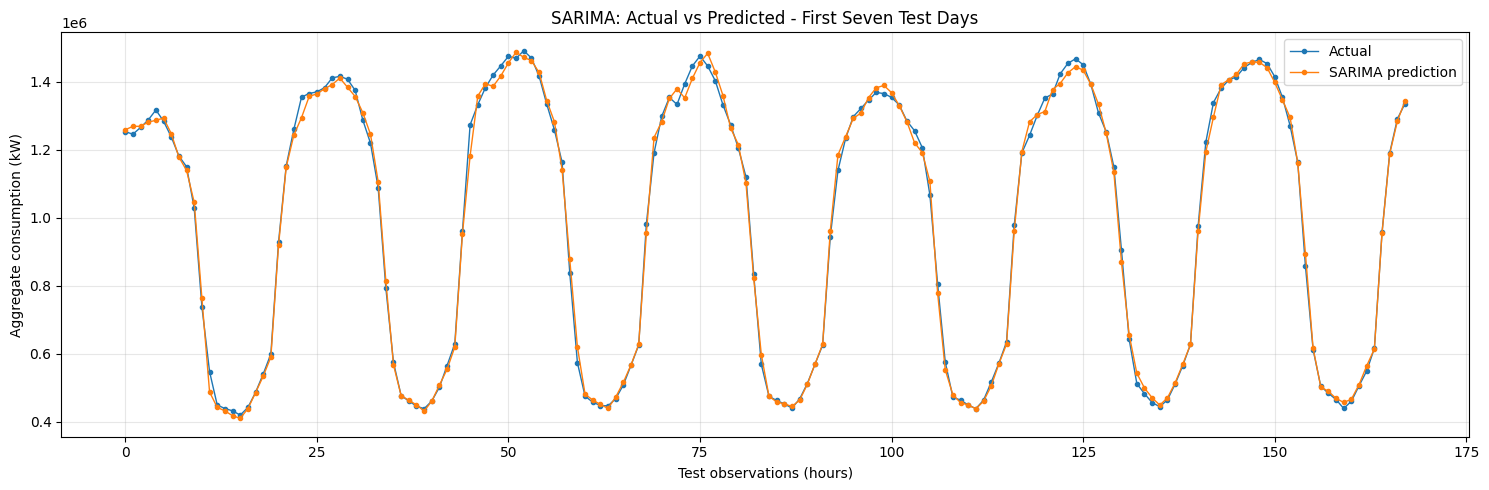

In [ ]:

# Full test-period comparison
plt.figure(figsize=(15, 5))
plt.plot(actual_test, label="Actual", linewidth=0.8)
plt.plot(
    sarima_test_predictions,
    label="SARIMA prediction",
    linewidth=0.8
)
plt.title("Actual vs Predicted Electricity Consumption - SARIMA")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# First seven days of the test period
hours_to_plot = min(168, len(test))

plt.figure(figsize=(15, 5))
plt.plot(
    actual_test[:hours_to_plot],
    label="Actual",
    marker=".",
    linewidth=1
)
plt.plot(
    sarima_test_predictions[:hours_to_plot],
    label="SARIMA prediction",
    marker=".",
    linewidth=1
)
plt.title("SARIMA: Actual vs Predicted - First Seven Test Days")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of the Final SARIMA Test Results

The selected SARIMA(2,1,3) × (1,0,1,24) model was evaluated on the test dataset containing 3,947 observations.

The model achieved the following results:

- RMSE: 23,891.46
- MAE: 14,366.74
- MAPE: 1.811%
- R²: 0.9950

The results indicate that the model produced relatively low forecasting errors on the held-out test dataset. The R² value of 0.9950 indicates that the model explains a high proportion of the variation in the actual test observations.

The actual-versus-predicted plots provide a visual comparison of the forecasted and observed consumption values over the test period.

The model was also reported as converged during estimation. The validation observations were incorporated sequentially without re-estimating the model parameters before generating the test forecasts.

Based on these results, SARIMA is taken forward for comparison with the non-seasonal ARIMA and neural-network models.

## 38. Fair comparison of ARIMA and SARIMA models

To ensure a consistent comparison, I evaluate both models using the same training, validation and test periods.

Both models are fitted using the training observations. Their model states are then updated sequentially using the actual validation observations before generating one-step-ahead test predictions. The model parameters remain fixed during this process.

I compare their test RMSE, MAE, MAPE and R² values.

For this comparison, both models are initially fitted using the training observations. Their model states are then updated using the validation observations before evaluating the test period. The model parameters remain fixed during this process. This matched evaluation is used for the final ARIMA and SARIMA comparison, rather than the additional ARIMA evaluation that uses combined training and validation data for fitting.

ARIMA model converged: True


,Model,Test RMSE,Test MAE,Test MAPE (%),Test R2
0,"ARIMA(2, 1, 3)",57109.1361,39515.5151,5.0553,0.9712
1,"SARIMA(2, 1, 3)x(1, 0, 1, 24)",23891.4576,14366.7394,1.8110,0.9950


SARIMA RMSE reduction compared with ARIMA: 58.17%


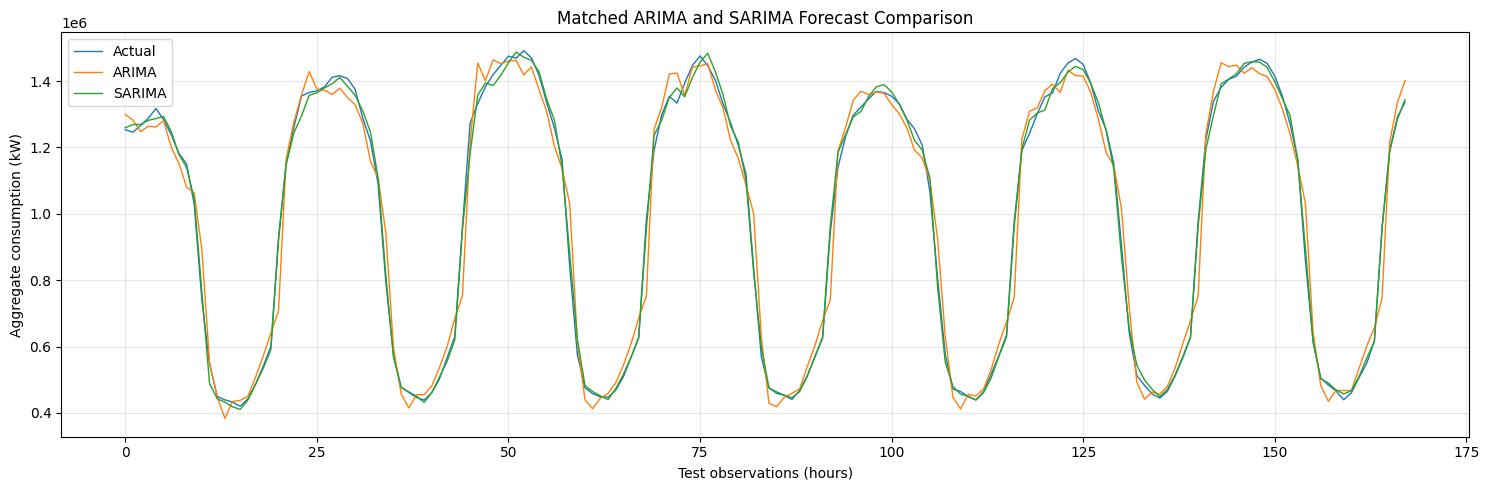

Matched model comparison completed successfully.


In [ ]:



# Verify that all required data and previous SARIMA results exist.
assert len(train) == 18412
assert len(validation) == 3945
assert len(test) == 3947

assert "sarima_test_predictions" in globals()
assert len(sarima_test_predictions) == len(test)

# --------------------------------------------------
# 1. Fit ARIMA using training data only
# --------------------------------------------------

matched_arima = ARIMA(
    train,
    order=best_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

matched_arima_fit = matched_arima.fit()

print(
    "ARIMA model converged:",
    matched_arima_fit.mle_retvals.get("converged", False)
)

# --------------------------------------------------
# 2. Update ARIMA state using validation observations
# --------------------------------------------------

matched_arima_after_validation = matched_arima_fit.extend(
    validation.to_numpy()
)

# --------------------------------------------------
# 3. Generate one-step-ahead test predictions
# --------------------------------------------------

matched_arima_test_results = matched_arima_after_validation.extend(
    test.to_numpy()
)

matched_arima_predictions = np.asarray(
    matched_arima_test_results.fittedvalues
).reshape(-1)

assert len(matched_arima_predictions) == len(test)

# --------------------------------------------------
# 4. Calculate ARIMA test metrics
# --------------------------------------------------

actual_test = test.to_numpy()

arima_rmse = np.sqrt(
    mean_squared_error(actual_test, matched_arima_predictions)
)

arima_mae = mean_absolute_error(
    actual_test, matched_arima_predictions
)

nonzero_mask = np.abs(actual_test) > 1e-8

arima_mape = (
    np.mean(
        np.abs(
            (actual_test[nonzero_mask] -
             matched_arima_predictions[nonzero_mask])
            / actual_test[nonzero_mask]
        )
    ) * 100
    if nonzero_mask.any()
    else np.nan
)

arima_r2 = r2_score(
    actual_test, matched_arima_predictions
)

# --------------------------------------------------
# 5. Prepare matched comparison table
# --------------------------------------------------

matched_comparison = pd.DataFrame([
    {
        "Model": f"ARIMA{best_order}",
        "Test RMSE": arima_rmse,
        "Test MAE": arima_mae,
        "Test MAPE (%)": arima_mape,
        "Test R2": arima_r2
    },
    {
        "Model": f"SARIMA{best_order}x{best_seasonal_order}",
        "Test RMSE": sarima_test_rmse,
        "Test MAE": sarima_test_mae,
        "Test MAPE (%)": sarima_test_mape,
        "Test R2": sarima_test_r2
    }
])

display(matched_comparison.round(4))

# --------------------------------------------------
# 6. Calculate percentage reduction in RMSE
# --------------------------------------------------

rmse_reduction = (
    (arima_rmse - sarima_test_rmse) / arima_rmse
) * 100

print(
    f"SARIMA RMSE reduction compared with ARIMA: "
    f"{rmse_reduction:.2f}%"
)

# --------------------------------------------------
# 7. Plot matched actual versus predicted values
# --------------------------------------------------

hours_to_plot = min(168, len(test))

plt.figure(figsize=(15, 5))

plt.plot(
    actual_test[:hours_to_plot],
    label="Actual",
    linewidth=1
)

plt.plot(
    matched_arima_predictions[:hours_to_plot],
    label="ARIMA",
    linewidth=1
)

plt.plot(
    sarima_test_predictions[:hours_to_plot],
    label="SARIMA",
    linewidth=1
)

plt.title("Matched ARIMA and SARIMA Forecast Comparison")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Matched model comparison completed successfully.")


### Interpretation of the Matched ARIMA and SARIMA Comparison

Both models were evaluated using the same training, validation and test periods and the same sequential one-step-ahead forecasting approach.

The ARIMA(2,1,3) model recorded a test RMSE of 57,109.14, while the SARIMA(2,1,3) × (1,0,1,24) model recorded a test RMSE of 23,891.46.

The SARIMA model also recorded lower MAE and MAPE values and a higher R² value than the non-seasonal ARIMA model.

The test RMSE reduction was calculated as 58.17%. This indicates that including the daily seasonal components substantially improved forecasting accuracy in this comparison.

The result is consistent with the earlier residual diagnostics, which showed significant autocorrelation at daily intervals in the non-seasonal ARIMA model.

Therefore, SARIMA provides better forecasting performance than the matched non-seasonal ARIMA model for this dataset and evaluation period.

## 39. Recurrent Neural Network (RNN) model development

A Recurrent Neural Network (RNN) is a neural network architecture designed to process sequential data. It uses information from previous time steps through a recurrent hidden state to learn temporal relationships.

In this project, the RNN is used to predict hourly aggregate electricity consumption using historical observations.

Different input sequence lengths, numbers of neurons, network depths, batch sizes and learning rates are examined. The validation dataset is used to select the best configuration based on RMSE. The test dataset is reserved for final model evaluation.

Dataset verification successful.
Training observations: 18412
Validation observations: 3945
Test observations: 3947

Training RNN configuration 1/4
Configuration: {'lookback': 24, 'units': 32, 'layers': 1, 'batch_size': 64, 'learning_rate': 0.001}
Validation RMSE: 43097.5696
Epochs completed: 12
Best epoch: 12

Training RNN configuration 2/4
Configuration: {'lookback': 168, 'units': 32, 'layers': 1, 'batch_size': 64, 'learning_rate': 0.001}
Validation RMSE: 36494.8935
Epochs completed: 12
Best epoch: 12

Training RNN configuration 3/4
Configuration: {'lookback': 24, 'units': 64, 'layers': 1, 'batch_size': 128, 'learning_rate': 0.0005}
Validation RMSE: 39237.2043
Epochs completed: 12
Best epoch: 12

Training RNN configuration 4/4
Configuration: {'lookback': 24, 'units': 32, 'layers': 2, 'batch_size': 64, 'learning_rate': 0.0005}
Validation RMSE: 44658.7695
Epochs completed: 12
Best epoch: 12

RNN validation comparison:


,lookback,units,layers,batch_size,learning_rate,Epochs completed,Best epoch,Lowest validation loss,Validation RMSE
0,168,32,1,64,0.0010,12,12,0.0006,36494.8935
1,24,64,1,128,0.0005,12,12,0.0007,39237.2043
2,24,32,1,64,0.0010,12,12,0.0009,43097.5696
3,24,32,2,64,0.0005,12,12,0.0010,44658.7695



Selected RNN configuration:
{'lookback': 168.0, 'units': 32.0, 'layers': 1.0, 'batch_size': 64.0, 'learning_rate': 0.001, 'Epochs completed': 12.0, 'Best epoch': 12.0, 'Lowest validation loss': 0.0006367528112605214, 'Validation RMSE': 36494.893475143894}

Total tuning time: 189.09 seconds

Training the selected RNN configuration.
Epoch 1/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 0.0041
Epoch 2/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - loss: 9.1958e-04
Epoch 3/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 6.5209e-04
Epoch 4/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 5.7121e-04
Epoch 5/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - loss: 5.2378e-04
Epoch 6/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 4.8899e-04
Epoch 7/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - loss: 4.5874e-04
Epoch 8/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 4.2586e-04
Epoch 9/12
286/286 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - loss: 4.0077e-04
Epoch 10/12
286/286 

,Model,Lookback,Neurons,Layers,Best epoch,Test RMSE,Test MAE,Test MAPE (%),Test R2
0,Simple RNN,168,32,1,12,35142.0392,24389.3853,3.0389,0.9891


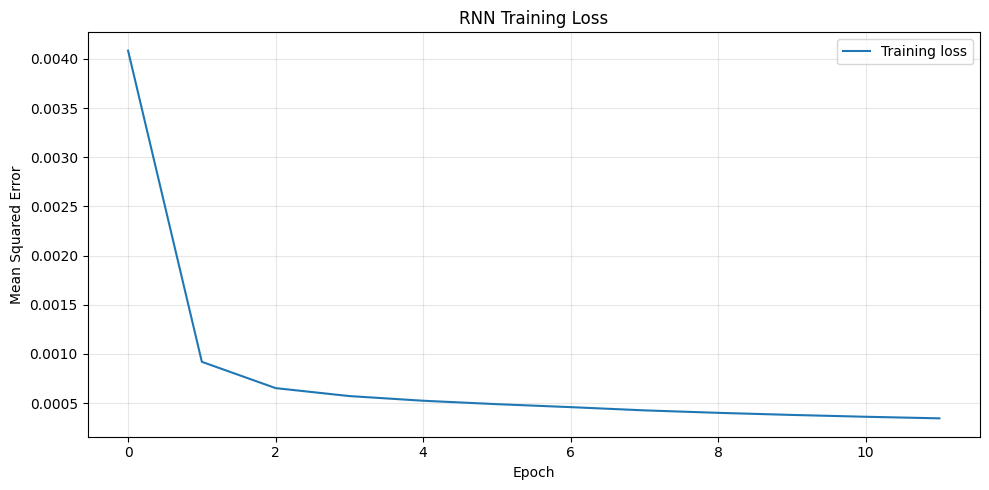

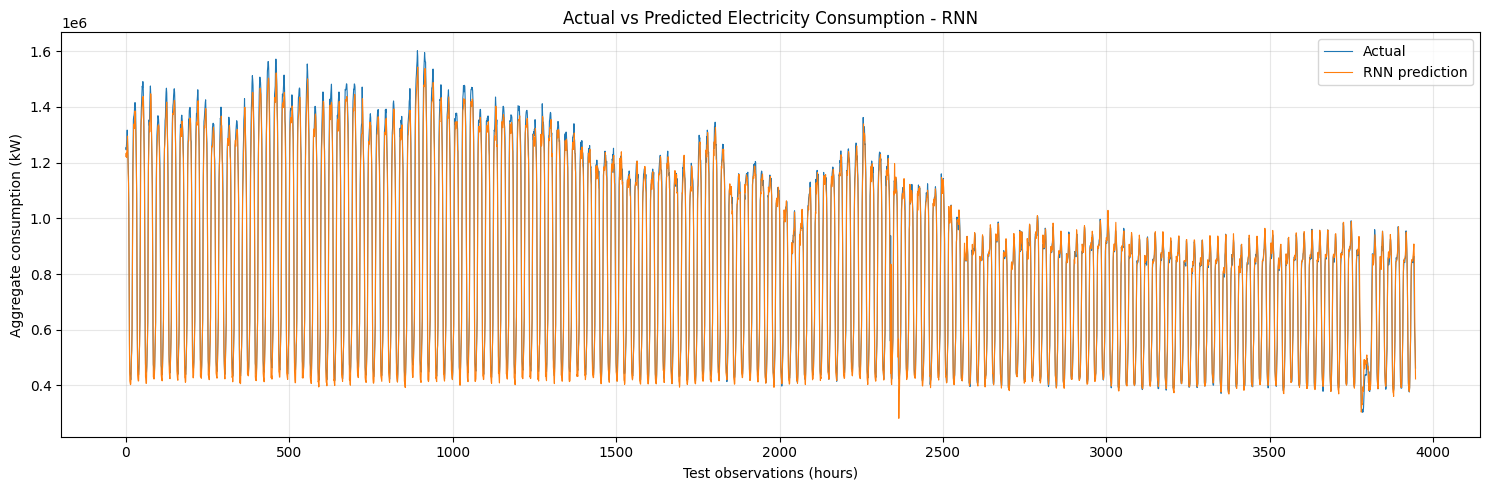

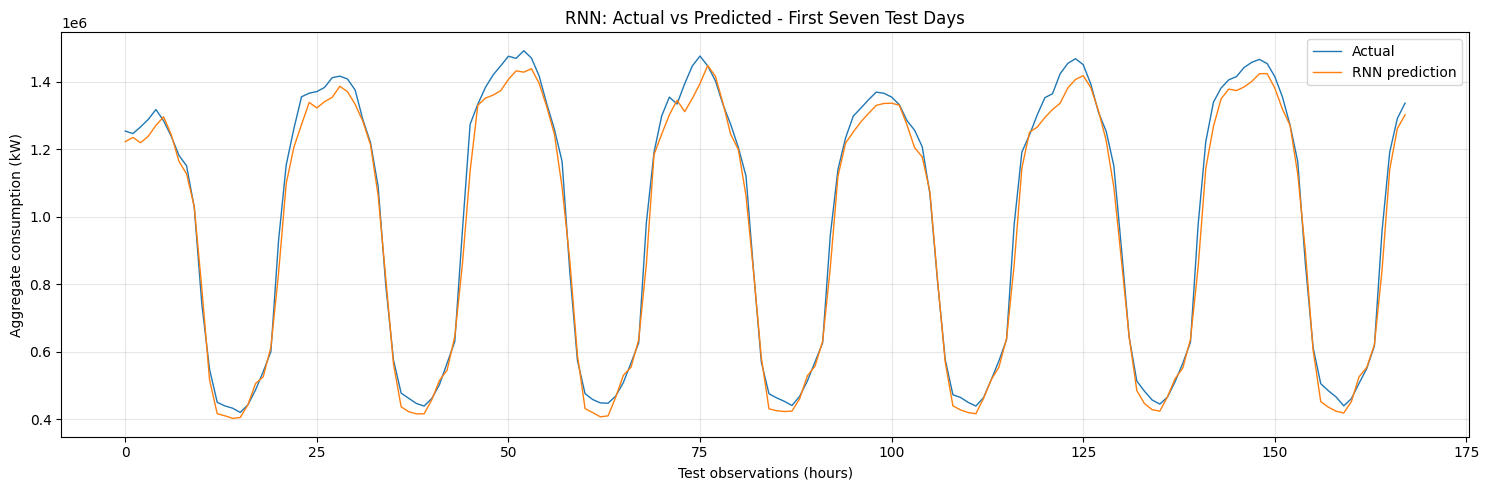


RNN development and test evaluation completed successfully.


In [ ]:



# Validation, hyperparameter tuning and final test evaluation

#VERIFY DATASET AND CHRONOLOGICAL SPLIT

assert len(train) == 18412
assert len(validation) == 3945
assert len(test) == 3947

print("Dataset verification successful.")
print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Test observations:", len(test))


#SET RANDOM SEEDS

np.random.seed(42)
tf.keras.utils.set_random_seed(42)


#SCALE DATA USING TRAINING DATA ONLY

rnn_scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = rnn_scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
)

validation_scaled = rnn_scaler.transform(
    validation.to_numpy().reshape(-1, 1)
)

test_scaled = rnn_scaler.transform(
    test.to_numpy().reshape(-1, 1)
)


#FUNCTION TO CREATE SEQUENTIAL INPUT WINDOWS

def create_rnn_sequences(values, lookback):

    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])

    return np.asarray(X), np.asarray(y)


#DEFINE HYPERPARAMETER CONFIGURATIONS

rnn_candidates = [
    {
        "lookback": 24,
        "units": 32,
        "layers": 1,
        "batch_size": 64,
        "learning_rate": 0.001
    },
    {
        "lookback": 168,
        "units": 32,
        "layers": 1,
        "batch_size": 64,
        "learning_rate": 0.001
    },
    {
        "lookback": 24,
        "units": 64,
        "layers": 1,
        "batch_size": 128,
        "learning_rate": 0.0005
    },
    {
        "lookback": 24,
        "units": 32,
        "layers": 2,
        "batch_size": 64,
        "learning_rate": 0.0005
    }
]


#TRAIN AND EVALUATE CANDIDATE CONFIGURATIONS

rnn_validation_results = []

rnn_tuning_start = time.time()

for index, config in enumerate(rnn_candidates, start=1):

    lookback = config["lookback"]

    print(
        f"\nTraining RNN configuration "
        f"{index}/{len(rnn_candidates)}"
    )

    print("Configuration:", config)

    # Create training sequences
    X_train_rnn, y_train_rnn = create_rnn_sequences(
        train_scaled,
        lookback
    )

    # Include the preceding training observations as context
    # for sequential validation forecasting.
    validation_context = np.concatenate(
        [
            train_scaled[-lookback:],
            validation_scaled
        ],
        axis=0
    )

    X_val_rnn, y_val_rnn = create_rnn_sequences(
        validation_context,
        lookback
    )

    # Build the RNN architecture
    model = Sequential()

    if config["layers"] == 1:

        model.add(
            SimpleRNN(
                config["units"],
                input_shape=(lookback, 1)
            )
        )

    else:

        model.add(
            SimpleRNN(
                config["units"],
                return_sequences=True,
                input_shape=(lookback, 1)
            )
        )

        model.add(
            SimpleRNN(config["units"])
        )

    model.add(Dense(1))

    model.compile(
        optimizer=Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="mse"
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Train the candidate model
    history = model.fit(
        X_train_rnn,
        y_train_rnn,
        validation_data=(X_val_rnn, y_val_rnn),
        epochs=12,
        batch_size=config["batch_size"],
        callbacks=[early_stopping],
        shuffle=False,
        verbose=0
    )

    # Generate validation predictions
    val_predictions_scaled = model.predict(
        X_val_rnn,
        verbose=0
    )

    val_predictions = rnn_scaler.inverse_transform(
        val_predictions_scaled
    ).reshape(-1)

    val_actual = rnn_scaler.inverse_transform(
        y_val_rnn
    ).reshape(-1)

    # Calculate validation RMSE
    val_rmse = np.sqrt(
        mean_squared_error(
            val_actual,
            val_predictions
        )
    )

    # Correctly identify the epoch with lowest validation loss
    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # Record tuning results
    rnn_validation_results.append({
        **config,
        "Epochs completed": len(history.history["loss"]),
        "Best epoch": best_epoch,
        "Lowest validation loss": min(history.history["val_loss"]),
        "Validation RMSE": val_rmse
    })

    print(
        f"Validation RMSE: {val_rmse:.4f}"
    )

    print(
        f"Epochs completed: {len(history.history['loss'])}"
    )

    print(
        f"Best epoch: {best_epoch}"
    )


# DISPLAY VALIDATION COMPARISON

rnn_validation_comparison = pd.DataFrame(
    rnn_validation_results
).sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("\nRNN validation comparison:")

display(
    rnn_validation_comparison.round(4)
)


#SELECT BEST RNN CONFIGURATION

best_rnn_config = (
    rnn_validation_comparison
    .iloc[0]
    .to_dict()
)

best_lookback = int(best_rnn_config["lookback"])
best_units = int(best_rnn_config["units"])
best_layers = int(best_rnn_config["layers"])
best_batch_size = int(best_rnn_config["batch_size"])
best_learning_rate = float(best_rnn_config["learning_rate"])
best_rnn_epoch = int(best_rnn_config["Best epoch"])

print("\nSelected RNN configuration:")
print(best_rnn_config)

print(
    "\nTotal tuning time:",
    round(time.time() - rnn_tuning_start, 2),
    "seconds"
)


# ==========================================================
# FINAL RNN MODEL TRAINING

print("\nTraining the selected RNN configuration.")

# Create training sequences using selected lookback
X_train_final, y_train_final = create_rnn_sequences(
    train_scaled,
    best_lookback
)

# Clear previous model state
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Build final RNN architecture
final_rnn_model = Sequential()

if best_layers == 1:

    final_rnn_model.add(
        SimpleRNN(
            best_units,
            input_shape=(best_lookback, 1)
        )
    )

else:

    final_rnn_model.add(
        SimpleRNN(
            best_units,
            return_sequences=True,
            input_shape=(best_lookback, 1)
        )
    )

    final_rnn_model.add(
        SimpleRNN(best_units)
    )

final_rnn_model.add(Dense(1))

final_rnn_model.compile(
    optimizer=Adam(
        learning_rate=best_learning_rate
    ),
    loss="mse"
)

# Train final model for the selected best epoch
rnn_final_start = time.time()

final_rnn_history = final_rnn_model.fit(
    X_train_final,
    y_train_final,
    epochs=best_rnn_epoch,
    batch_size=best_batch_size,
    shuffle=False,
    verbose=1
)

rnn_final_training_time = time.time() - rnn_final_start

print(
    "\nFinal RNN training time:",
    round(rnn_final_training_time, 2),
    "seconds"
)


# ==========================================================
# GENERATE SEQUENTIAL TEST PREDICTIONS
# ==========================================================

# Actual validation observations are used as historical context.
# The test observations are then processed sequentially.
all_future_scaled = np.concatenate(
    [
        train_scaled[-best_lookback:],
        validation_scaled,
        test_scaled
    ],
    axis=0
)

X_future, y_future = create_rnn_sequences(
    all_future_scaled,
    best_lookback
)

# Predict validation and test periods
future_predictions_scaled = final_rnn_model.predict(
    X_future,
    verbose=0
)

# Retain only the test-period predictions
rnn_test_predictions_scaled = future_predictions_scaled[
    len(validation):
]

# Convert predictions back to original consumption scale
rnn_test_predictions = rnn_scaler.inverse_transform(
    rnn_test_predictions_scaled
).reshape(-1)

actual_test_rnn = test.to_numpy()

# Verify prediction count
assert len(rnn_test_predictions) == len(test)

print(
    "\nNumber of test predictions:",
    len(rnn_test_predictions)
)


# ==========================================================
# CALCULATE FINAL TEST METRICS


rnn_test_rmse = np.sqrt(
    mean_squared_error(
        actual_test_rnn,
        rnn_test_predictions
    )
)

rnn_test_mae = mean_absolute_error(
    actual_test_rnn,
    rnn_test_predictions
)

nonzero_mask = np.abs(actual_test_rnn) > 1e-8

rnn_test_mape = (
    np.mean(
        np.abs(
            (
                actual_test_rnn[nonzero_mask]
                - rnn_test_predictions[nonzero_mask]
            )
            / actual_test_rnn[nonzero_mask]
        )
    ) * 100
    if nonzero_mask.any()
    else np.nan
)

rnn_test_r2 = r2_score(
    actual_test_rnn,
    rnn_test_predictions
)


# DISPLAY FINAL RNN TEST RESULTS

rnn_test_metrics = pd.DataFrame([{
    "Model": "Simple RNN",
    "Lookback": best_lookback,
    "Neurons": best_units,
    "Layers": best_layers,
    "Best epoch": best_rnn_epoch,
    "Test RMSE": rnn_test_rmse,
    "Test MAE": rnn_test_mae,
    "Test MAPE (%)": rnn_test_mape,
    "Test R2": rnn_test_r2
}])

print("\nFinal RNN test performance:")

display(
    rnn_test_metrics.round(4)
)


# ==========================================================
# PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    final_rnn_history.history["loss"],
    label="Training loss"
)

plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================================
# ACTUAL VS PREDICTED - FULL TEST PERIOD
plt.figure(figsize=(15, 5))

plt.plot(
    actual_test_rnn,
    label="Actual",
    linewidth=0.8
)

plt.plot(
    rnn_test_predictions,
    label="RNN prediction",
    linewidth=0.8
)

plt.title(
    "Actual vs Predicted Electricity Consumption - RNN"
)

plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================================
# ACTUAL VS PREDICTED - FIRST SEVEN TEST DAYS

hours_to_plot = min(168, len(test))

plt.figure(figsize=(15, 5))

plt.plot(
    actual_test_rnn[:hours_to_plot],
    label="Actual",
    linewidth=1
)

plt.plot(
    rnn_test_predictions[:hours_to_plot],
    label="RNN prediction",
    linewidth=1
)

plt.title(
    "RNN: Actual vs Predicted - First Seven Test Days"
)

plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


print("\nRNN development and test evaluation completed successfully.")


### Interpretation of the RNN Results

Four RNN configurations were examined using different lookback periods, numbers of neurons, network depths, batch sizes and learning rates.

The configuration with a lookback period of 168 hours, 32 neurons and one recurrent layer recorded the lowest validation RMSE of 36,494.89.

This configuration was selected for final evaluation. The selected model achieved a test RMSE of 35,142.04, MAE of 24,389.39, MAPE of 3.0389% and R² of 0.9891.

The results indicate that the RNN was able to learn useful sequential patterns in hourly electricity consumption. The 168-hour lookback allows the model to use information from the preceding seven days when generating the next-hour forecast.

The actual-versus-predicted plots provide an additional visual assessment of the model's performance on the test period.

The RNN results are included in the overall comparison to examine how a neural-network-based approach performs against the statistical forecasting models.

## 40. LONG SHORT-TERM MEMORY (LSTM)
An LSTM is a type of recurrent neural network designed to learn sequential patterns while controlling how information is retained and updated over time. It uses a cell state and three gates: the forget gate, input gate and output gate. In this project, I use LSTM to forecast hourly aggregate electricity consumption and compare its performance with the Simple RNN and statistical forecasting models.

Dataset verification successful.
Training observations: 18412
Validation observations: 3945
Test observations: 3947

Training LSTM configuration 1/4
Configuration: {'lookback': 24, 'units': 32, 'layers': 1, 'batch_size': 64, 'learning_rate': 0.001}
Validation RMSE: 44439.1457
Epochs completed: 10
Best epoch: 8

Training LSTM configuration 2/4
Configuration: {'lookback': 168, 'units': 32, 'layers': 1, 'batch_size': 64, 'learning_rate': 0.001}
Validation RMSE: 54618.5074
Epochs completed: 12
Best epoch: 12

Training LSTM configuration 3/4
Configuration: {'lookback': 24, 'units': 64, 'layers': 1, 'batch_size': 128, 'learning_rate': 0.0005}
Validation RMSE: 46773.4111
Epochs completed: 12
Best epoch: 12

Training LSTM configuration 4/4
Configuration: {'lookback': 24, 'units': 32, 'layers': 2, 'batch_size': 64, 'learning_rate': 0.0005}
Validation RMSE: 55169.1130
Epochs completed: 10
Best epoch: 8

LSTM validation comparison:


,lookback,units,layers,batch_size,learning_rate,Epochs completed,Best epoch,Lowest validation loss,Validation RMSE
0,24,32,1,64,0.0010,10,8,0.0009,44439.1457
1,24,64,1,128,0.0005,12,12,0.0010,46773.4111
2,168,32,1,64,0.0010,12,12,0.0014,54618.5074
3,24,32,2,64,0.0005,10,8,0.0015,55169.1130



Selected LSTM configuration:
{'lookback': 24.0, 'units': 32.0, 'layers': 1.0, 'batch_size': 64.0, 'learning_rate': 0.001, 'Epochs completed': 10.0, 'Best epoch': 8.0, 'Lowest validation loss': 0.0009441436850465834, 'Validation RMSE': 44439.14567695096}

Total LSTM tuning time: 388.75 seconds

Training the selected final LSTM model.
Epoch 1/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0120
Epoch 2/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0029
Epoch 3/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0020
Epoch 4/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0016
Epoch 5/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0013
Epoch 6/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.0011    
Epoch 7/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 9.4967e-04
Epoch 8/8
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 8.4746e-04

Final LSTM training time: 26.87 seconds

Number of LSTM test predictions: 3947

Final LSTM test performance:


,Model,Lookback,Neurons,Layers,Best epoch,Test RMSE,Test MAE,Test MAPE (%),Test R2
0,LSTM,24,32,1,8,53271.9102,37640.9863,4.5162,0.9749


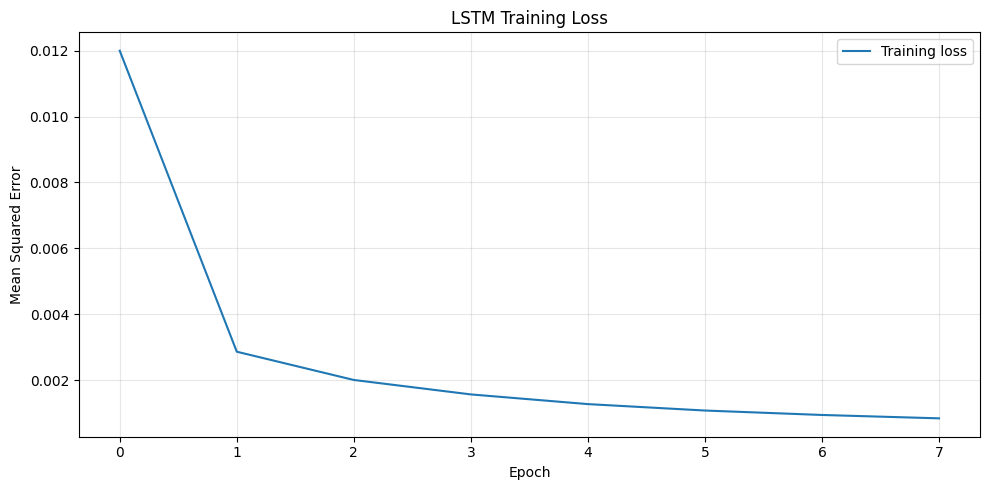

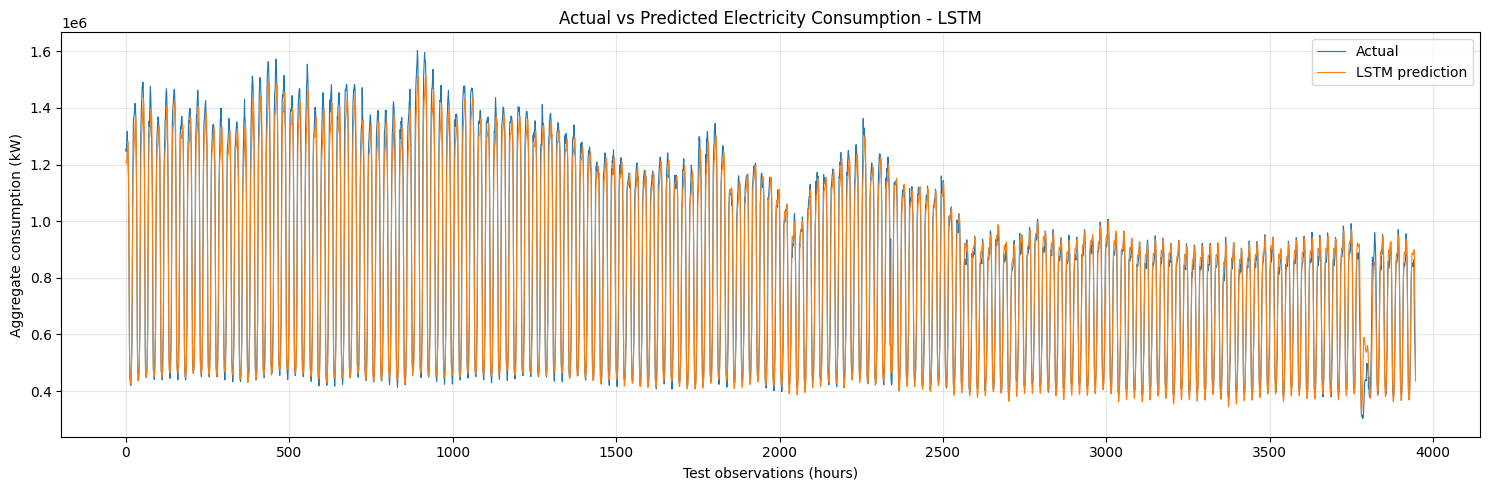

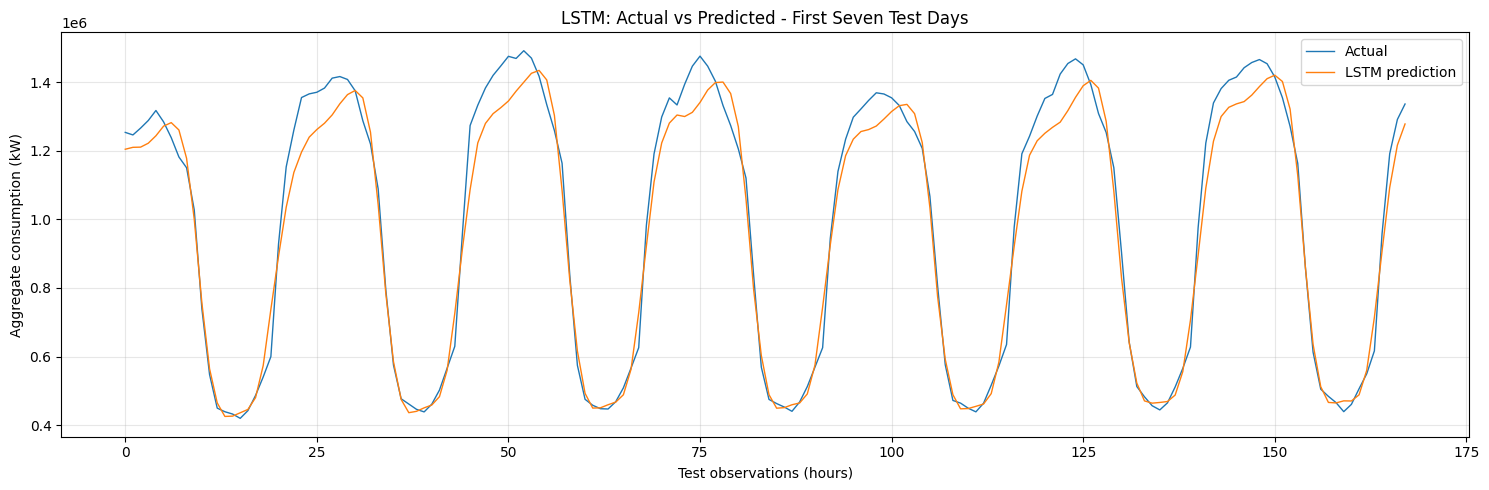


LSTM development and test evaluation completed successfully.


In [ ]:


# Hyperparameter tuning, final training and test evaluation


# ----------------------------------------------------------
# 1. VERIFY DATA AND CHRONOLOGICAL SPLIT
# ----------------------------------------------------------

assert len(train) == 18412
assert len(validation) == 3945
assert len(test) == 3947

print("Dataset verification successful.")
print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Test observations:", len(test))


# ----------------------------------------------------------
# 2. SET RANDOM SEEDS
# ----------------------------------------------------------

np.random.seed(42)
tf.keras.utils.set_random_seed(42)


# ----------------------------------------------------------
# 3. SCALE DATA USING TRAINING DATA ONLY
# ----------------------------------------------------------

lstm_scaler = MinMaxScaler(feature_range=(0, 1))

lstm_train_scaled = lstm_scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
)

lstm_validation_scaled = lstm_scaler.transform(
    validation.to_numpy().reshape(-1, 1)
)

lstm_test_scaled = lstm_scaler.transform(
    test.to_numpy().reshape(-1, 1)
)


# ----------------------------------------------------------
# 4. FUNCTION TO CREATE SEQUENTIAL INPUT WINDOWS
# ----------------------------------------------------------

def create_lstm_sequences(values, lookback):

    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])

    return np.asarray(X), np.asarray(y)


# ----------------------------------------------------------
# 5. DEFINE HYPERPARAMETER CONFIGURATIONS
# ----------------------------------------------------------

lstm_candidates = [
    {
        "lookback": 24,
        "units": 32,
        "layers": 1,
        "batch_size": 64,
        "learning_rate": 0.001
    },
    {
        "lookback": 168,
        "units": 32,
        "layers": 1,
        "batch_size": 64,
        "learning_rate": 0.001
    },
    {
        "lookback": 24,
        "units": 64,
        "layers": 1,
        "batch_size": 128,
        "learning_rate": 0.0005
    },
    {
        "lookback": 24,
        "units": 32,
        "layers": 2,
        "batch_size": 64,
        "learning_rate": 0.0005
    }
]


# ----------------------------------------------------------
# 6. TRAIN AND EVALUATE CANDIDATE CONFIGURATIONS
# ----------------------------------------------------------

lstm_validation_results = []

lstm_tuning_start = time.time()

for index, config in enumerate(lstm_candidates, start=1):

    lookback = config["lookback"]

    print(
        f"\nTraining LSTM configuration "
        f"{index}/{len(lstm_candidates)}"
    )

    print("Configuration:", config)

    # Create training sequences
    X_train_lstm, y_train_lstm = create_lstm_sequences(
        lstm_train_scaled,
        lookback
    )

    # Include preceding training observations as context
    # for sequential validation forecasting.
    validation_context = np.concatenate(
        [
            lstm_train_scaled[-lookback:],
            lstm_validation_scaled
        ],
        axis=0
    )

    X_val_lstm, y_val_lstm = create_lstm_sequences(
        validation_context,
        lookback
    )

    # Build LSTM architecture
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential()

    model.add(Input(shape=(lookback, 1)))

    if config["layers"] == 1:

        model.add(
            LSTM(config["units"])
        )

    else:

        model.add(
            LSTM(
                config["units"],
                return_sequences=True
            )
        )

        model.add(
            LSTM(config["units"])
        )

    model.add(Dense(1))

    model.compile(
        optimizer=Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="mse"
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Train candidate model
    history = model.fit(
        X_train_lstm,
        y_train_lstm,
        validation_data=(X_val_lstm, y_val_lstm),
        epochs=12,
        batch_size=config["batch_size"],
        callbacks=[early_stopping],
        shuffle=False,
        verbose=0
    )

    # Generate validation predictions
    val_predictions_scaled = model.predict(
        X_val_lstm,
        verbose=0
    )

    val_predictions = lstm_scaler.inverse_transform(
        val_predictions_scaled
    ).reshape(-1)

    val_actual = lstm_scaler.inverse_transform(
        y_val_lstm
    ).reshape(-1)

    # Calculate validation RMSE
    val_rmse = np.sqrt(
        mean_squared_error(
            val_actual,
            val_predictions
        )
    )

    # Identify epoch with lowest validation loss
    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # Store tuning results
    lstm_validation_results.append({
        **config,
        "Epochs completed": len(history.history["loss"]),
        "Best epoch": best_epoch,
        "Lowest validation loss": min(history.history["val_loss"]),
        "Validation RMSE": val_rmse
    })

    print(f"Validation RMSE: {val_rmse:.4f}")
    print(f"Epochs completed: {len(history.history['loss'])}")
    print(f"Best epoch: {best_epoch}")


# ----------------------------------------------------------
# 7. DISPLAY VALIDATION COMPARISON
# ----------------------------------------------------------

lstm_validation_comparison = pd.DataFrame(
    lstm_validation_results
).sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("\nLSTM validation comparison:")

display(
    lstm_validation_comparison.round(4)
)


# ----------------------------------------------------------
# 8. SELECT BEST LSTM CONFIGURATION
# ----------------------------------------------------------

best_lstm_config = (
    lstm_validation_comparison
    .iloc[0]
    .to_dict()
)

best_lstm_lookback = int(
    best_lstm_config["lookback"]
)

best_lstm_units = int(
    best_lstm_config["units"]
)

best_lstm_layers = int(
    best_lstm_config["layers"]
)

best_lstm_batch_size = int(
    best_lstm_config["batch_size"]
)

best_lstm_learning_rate = float(
    best_lstm_config["learning_rate"]
)

best_lstm_epoch = int(
    best_lstm_config["Best epoch"]
)

print("\nSelected LSTM configuration:")
print(best_lstm_config)

print(
    "\nTotal LSTM tuning time:",
    round(time.time() - lstm_tuning_start, 2),
    "seconds"
)


# ----------------------------------------------------------
# 9. TRAIN FINAL LSTM MODEL
# ----------------------------------------------------------

print("\nTraining the selected final LSTM model.")

X_train_lstm_final, y_train_lstm_final = create_lstm_sequences(
    lstm_train_scaled,
    best_lstm_lookback
)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

final_lstm_model = Sequential()

final_lstm_model.add(
    Input(shape=(best_lstm_lookback, 1))
)

if best_lstm_layers == 1:

    final_lstm_model.add(
        LSTM(best_lstm_units)
    )

else:

    final_lstm_model.add(
        LSTM(
            best_lstm_units,
            return_sequences=True
        )
    )

    final_lstm_model.add(
        LSTM(best_lstm_units)
    )

final_lstm_model.add(Dense(1))

final_lstm_model.compile(
    optimizer=Adam(
        learning_rate=best_lstm_learning_rate
    ),
    loss="mse"
)

lstm_final_start = time.time()

final_lstm_history = final_lstm_model.fit(
    X_train_lstm_final,
    y_train_lstm_final,
    epochs=best_lstm_epoch,
    batch_size=best_lstm_batch_size,
    shuffle=False,
    verbose=1
)

lstm_final_training_time = time.time() - lstm_final_start

print(
    "\nFinal LSTM training time:",
    round(lstm_final_training_time, 2),
    "seconds"
)


# ----------------------------------------------------------
# 10. GENERATE SEQUENTIAL TEST PREDICTIONS
# ----------------------------------------------------------

# Actual validation observations are used as historical context.
# The test observations are then processed sequentially.

lstm_all_future_scaled = np.concatenate(
    [
        lstm_train_scaled[-best_lstm_lookback:],
        lstm_validation_scaled,
        lstm_test_scaled
    ],
    axis=0
)

X_lstm_future, y_lstm_future = create_lstm_sequences(
    lstm_all_future_scaled,
    best_lstm_lookback
)

# Predict validation and test periods
lstm_future_predictions_scaled = final_lstm_model.predict(
    X_lstm_future,
    verbose=0
)

# Retain only test-period predictions
lstm_test_predictions_scaled = (
    lstm_future_predictions_scaled[len(validation):]
)

# Convert predictions to original consumption scale
lstm_test_predictions = lstm_scaler.inverse_transform(
    lstm_test_predictions_scaled
).reshape(-1)

actual_test_lstm = test.to_numpy()

assert len(lstm_test_predictions) == len(test)

print(
    "\nNumber of LSTM test predictions:",
    len(lstm_test_predictions)
)


# ----------------------------------------------------------
# 11. CALCULATE FINAL TEST METRICS
# ----------------------------------------------------------

lstm_test_rmse = np.sqrt(
    mean_squared_error(
        actual_test_lstm,
        lstm_test_predictions
    )
)

lstm_test_mae = mean_absolute_error(
    actual_test_lstm,
    lstm_test_predictions
)

nonzero_mask = np.abs(actual_test_lstm) > 1e-8

lstm_test_mape = (
    np.mean(
        np.abs(
            (
                actual_test_lstm[nonzero_mask]
                - lstm_test_predictions[nonzero_mask]
            )
            / actual_test_lstm[nonzero_mask]
        )
    ) * 100
    if nonzero_mask.any()
    else np.nan
)

lstm_test_r2 = r2_score(
    actual_test_lstm,
    lstm_test_predictions
)


# ----------------------------------------------------------
# 12. DISPLAY FINAL LSTM TEST RESULTS
# ----------------------------------------------------------

lstm_test_metrics = pd.DataFrame([{
    "Model": "LSTM",
    "Lookback": best_lstm_lookback,
    "Neurons": best_lstm_units,
    "Layers": best_lstm_layers,
    "Best epoch": best_lstm_epoch,
    "Test RMSE": lstm_test_rmse,
    "Test MAE": lstm_test_mae,
    "Test MAPE (%)": lstm_test_mape,
    "Test R2": lstm_test_r2
}])

print("\nFinal LSTM test performance:")

display(
    lstm_test_metrics.round(4)
)


# ----------------------------------------------------------
# 13. PLOT TRAINING LOSS
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    final_lstm_history.history["loss"],
    label="Training loss"
)

plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 14. ACTUAL VS PREDICTED - FULL TEST PERIOD
# ----------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.plot(
    actual_test_lstm,
    label="Actual",
    linewidth=0.8
)

plt.plot(
    lstm_test_predictions,
    label="LSTM prediction",
    linewidth=0.8
)

plt.title(
    "Actual vs Predicted Electricity Consumption - LSTM"
)

plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 15. ACTUAL VS PREDICTED - FIRST SEVEN TEST DAYS
# ----------------------------------------------------------

hours_to_plot = min(168, len(test))

plt.figure(figsize=(15, 5))

plt.plot(
    actual_test_lstm[:hours_to_plot],
    label="Actual",
    linewidth=1
)

plt.plot(
    lstm_test_predictions[:hours_to_plot],
    label="LSTM prediction",
    linewidth=1
)

plt.title(
    "LSTM: Actual vs Predicted - First Seven Test Days"
)

plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


print("\nLSTM development and test evaluation completed successfully.")


In [ ]:

# RECOVERY CELL: RESTORE MODEL RESULTS AND DOWNLOAD CSV
# No model training or forecasting is performed.

import pandas as pd
from google.colab import files

# Previously completed model evaluation results
model_results = [
    {
        "Model": "MA(24)",
        "RMSE": 50814.36,
        "MAE": 37793.29,
        "MAPE (%)": 4.9804,
        "R2": 0.9772
    },
    {
        "Model": "AR(24)",
        "RMSE": 36465.27,
        "MAE": 24419.23,
        "MAPE (%)": 3.2027,
        "R2": 0.9883
    },
    {
        "Model": "ARIMA(2, 1, 3)",
        "RMSE": 57109.1361,
        "MAE": 39515.5151,
        "MAPE (%)": 5.0553,
        "R2": 0.9712
    },
    {
        "Model": "SARIMA(2, 1, 3)x(1, 0, 1, 24)",
        "RMSE": 23891.4576,
        "MAE": 14366.7394,
        "MAPE (%)": 1.8110,
        "R2": 0.9950
    },
    {
        "Model": "Simple RNN",
        "RMSE": 35142.0392,
        "MAE": 24389.3853,
        "MAPE (%)": 3.0389,
        "R2": 0.9891
    },
    {
        "Model": "LSTM",
        "RMSE": 53271.9102,
        "MAE": 37640.9863,
        "MAPE (%)": 4.5162,
        "R2": 0.9749
    }
]

# Create consolidated results table
final_model_results = pd.DataFrame(model_results)

# Validate the results
assert len(final_model_results) == 6
assert final_model_results["Model"].is_unique
assert final_model_results.notna().all().all()

# Rank models by test RMSE
final_model_results = final_model_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

final_model_results.insert(
    0, "Rank", range(1, len(final_model_results) + 1)
)

# Display results
print("All six model results restored successfully.")
display(final_model_results)

# Export and download CSV
csv_filename = "Final_Point_Forecast_Model_Comparison.csv"

final_model_results.to_csv(
    csv_filename,
    index=False
)

files.download(csv_filename)

print("CSV file prepared for download.")
print("No model was retrained.")


All six model results restored successfully.


,Rank,Model,RMSE,MAE,MAPE (%),R2
0,1,"SARIMA(2, 1, 3)x(1, 0, 1, 24)",23891.4576,14366.7394,1.8110,0.9950
1,2,Simple RNN,35142.0392,24389.3853,3.0389,0.9891
2,3,AR(24),36465.2700,24419.2300,3.2027,0.9883
3,4,MA(24),50814.3600,37793.2900,4.9804,0.9772
4,5,LSTM,53271.9102,37640.9863,4.5162,0.9749
5,6,"ARIMA(2, 1, 3)",57109.1361,39515.5151,5.0553,0.9712


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CSV file prepared for download.
No model was retrained.


### Interpretation of the LSTM Results

Four LSTM configurations were examined using different lookback periods, numbers of neurons, network depths, batch sizes and learning rates.

The configuration with a lookback period of 24 hours, 32 neurons and one LSTM layer recorded the lowest validation RMSE of 44,439.15. The best epoch was identified as epoch 8.

The selected LSTM model achieved a test RMSE of 53,271.91, MAE of 37,640.99, MAPE of 4.5162% and R² of 0.9749.

The results show that the LSTM was able to capture patterns in the hourly consumption series. However, its test forecasting errors were higher than those obtained by the selected Simple RNN and SARIMA models.

This indicates that using a more complex recurrent architecture does not automatically result in better forecasting accuracy. The performance depends on the data, selected configuration and training process.

The LSTM results are therefore retained as part of the overall comparison rather than assuming that the LSTM must outperform the other models.

## 41. Overall Comparison of Point Forecasting Models

After evaluating the selected MA, AR, ARIMA, SARIMA, Simple RNN and LSTM models, I compare their forecasting performance using RMSE, MAE, MAPE and R². RMSE and MAE are expressed in kW. MAPE is expressed as a percentage, while R² is dimensionless.

All six models are evaluated on the same chronological test period containing 3,947 hourly observations. The comparison is based on their final test performance, with the models ranked according to RMSE. A lower RMSE indicates better forecasting accuracy.

This comparison helps identify the most suitable model for forecasting hourly aggregate electricity consumption.



### Evaluation protocol

The comparison is based on the historical test period containing 3,947 hourly observations. All models use the same chronological data split, and the forecasts are evaluated using a one-step-ahead approach.

For the statistical models, the available observations are incorporated sequentially so that each subsequent prediction uses the actual preceding observation. For the RNN and LSTM models, the preceding actual observations are used as input to generate the next-step prediction.

The model parameters are not re-estimated during the sequential test evaluation. Therefore, the results represent rolling one-step-ahead forecasting performance rather than forecasts generated several hours or days in advance without access to intervening actual observations.

The final comparison uses the matched ARIMA result from Section 38. This ensures that the ARIMA and SARIMA results are compared using the same evaluation procedure.

In [ ]:



# No model training or forecasting is performed in this section.
# The previously evaluated results are restored by the Recovery Cell.

# --------------------------------------------------
# 1. VERIFY THE RESTORED MODEL RESULTS
# --------------------------------------------------

assert "final_model_results" in globals(), (
    "Run the Recovery Cell before executing Section 41."
)

assert len(final_model_results) == 6
assert final_model_results["Model"].is_unique

# --------------------------------------------------
# 2. PREPARE THE FINAL COMPARISON TABLE
# --------------------------------------------------

final_model_comparison = final_model_results[
    ["Rank", "Model", "RMSE", "MAE", "MAPE (%)", "R2"]
].copy()

final_model_comparison = final_model_comparison.rename(
    columns={"Rank": "Rank (RMSE)"}
)

# --------------------------------------------------
# 3. VERIFY THE METRICS AND MODEL RANKING
# --------------------------------------------------

metric_columns = ["RMSE", "MAE", "MAPE (%)", "R2"]

assert final_model_comparison[metric_columns].notna().all().all()

# Confirm ascending order of RMSE.
assert final_model_comparison["RMSE"].is_monotonic_increasing

assert final_model_comparison["Rank (RMSE)"].tolist() == [
    1, 2, 3, 4, 5, 6
]

# --------------------------------------------------
# 4. DISPLAY THE OVERALL COMPARISON
# --------------------------------------------------

print("OVERALL TEST PERFORMANCE COMPARISON")
print("Number of models:", len(final_model_comparison))
print("Test observations:", 3947)
print("Forecast horizon: One step ahead")
print("Ranking criterion: RMSE (lower is better)")

display(final_model_comparison.round(4))

print(
    "\nBest-performing model:",
    final_model_comparison.iloc[0]["Model"]
)

print("\nSection 41 completed successfully.")


OVERALL TEST PERFORMANCE COMPARISON
Number of models: 6
Test observations: 3947
Forecast horizon: One step ahead
Ranking criterion: RMSE (lower is better)


,Rank (RMSE),Model,RMSE,MAE,MAPE (%),R2
0,1,"SARIMA(2, 1, 3)x(1, 0, 1, 24)",23891.4576,14366.7394,1.8110,0.9950
1,2,Simple RNN,35142.0392,24389.3853,3.0389,0.9891
2,3,AR(24),36465.2700,24419.2300,3.2027,0.9883
3,4,MA(24),50814.3600,37793.2900,4.9804,0.9772
4,5,LSTM,53271.9102,37640.9863,4.5162,0.9749
5,6,"ARIMA(2, 1, 3)",57109.1361,39515.5151,5.0553,0.9712



Best-performing model: SARIMA(2, 1, 3)x(1, 0, 1, 24)

Section 41 completed successfully.


### Interpretation of the Overall Model Comparison

The six forecasting models were compared using the same test dataset containing 3,947 hourly observations. The models were ranked according to RMSE, with lower values indicating better forecasting performance.

SARIMA(2,1,3) × (1,0,1,24) achieved the lowest test RMSE of 23,891.46, followed by Simple RNN with 35,142.04 and AR(24) with 36,465.27.

The MA(24), LSTM and ARIMA models recorded higher RMSE values of 50,814.36, 53,271.91 and 57,109.14, respectively.

SARIMA also recorded the lowest MAE and MAPE and the highest R² among the six models.

The comparison indicates that the seasonal statistical model performed better than the other approaches examined in this project. The result also shows that the Simple RNN performed better than the selected LSTM configuration on the test dataset.

Based on the overall test results, SARIMA is selected as the preferred point-forecasting model for this experiment.

## 42. Probabilistic Forecasting using LSTM Quantile Regression

A point forecast provides a single expected value, whereas a probabilistic forecast provides a range of possible values. In this section, I train two separate LSTM models to estimate the 2.5th and 97.5th percentiles of hourly electricity consumption.

The models are trained using quantile-specific pinball loss. Together, their predictions form a nominal 95% prediction interval. I evaluate the interval using Prediction Interval Coverage Probability (PICP) and Mean Prediction Interval Width (MPIW).

Training observations: 18412
Validation observations: 3945
Test observations: 3947

Validation arrangement
Model-selection observations: 2761
Calibration observations: 1184

Training sequence shape: (18388, 24, 1)
Tuning sequence shape: (2761, 24, 1)

Training: Lower quantile LSTM
Quantile: 0.025
Epoch 1/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 2/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0026 - val_loss: 0.0023
Epoch 3/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0025 - val_loss: 0.0023
Epoch 4/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0023 - val_loss: 0.0021
Epoch 5/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0021 - val_loss: 0.0017
Epoch 6/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 7/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0018 - val_loss: 0.0015
Epoch 8/12
288/288 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.0018 - val_loss: 0.0015
Epoch 9/

,Method,PICP (%),MPIW (kW),Outside observations
0,Original quantile LSTM,56.4226,141952.421875,1720
1,CQR calibrated LSTM,94.6288,386613.625000,212



Test pinball losses
Lower quantile: 3046.265266
Upper quantile: 36054.084667


,Model,Quantile,Best epoch,Training time (seconds)
0,Lower quantile LSTM,0.025,7,37.8587
1,Upper quantile LSTM,0.975,4,21.5103


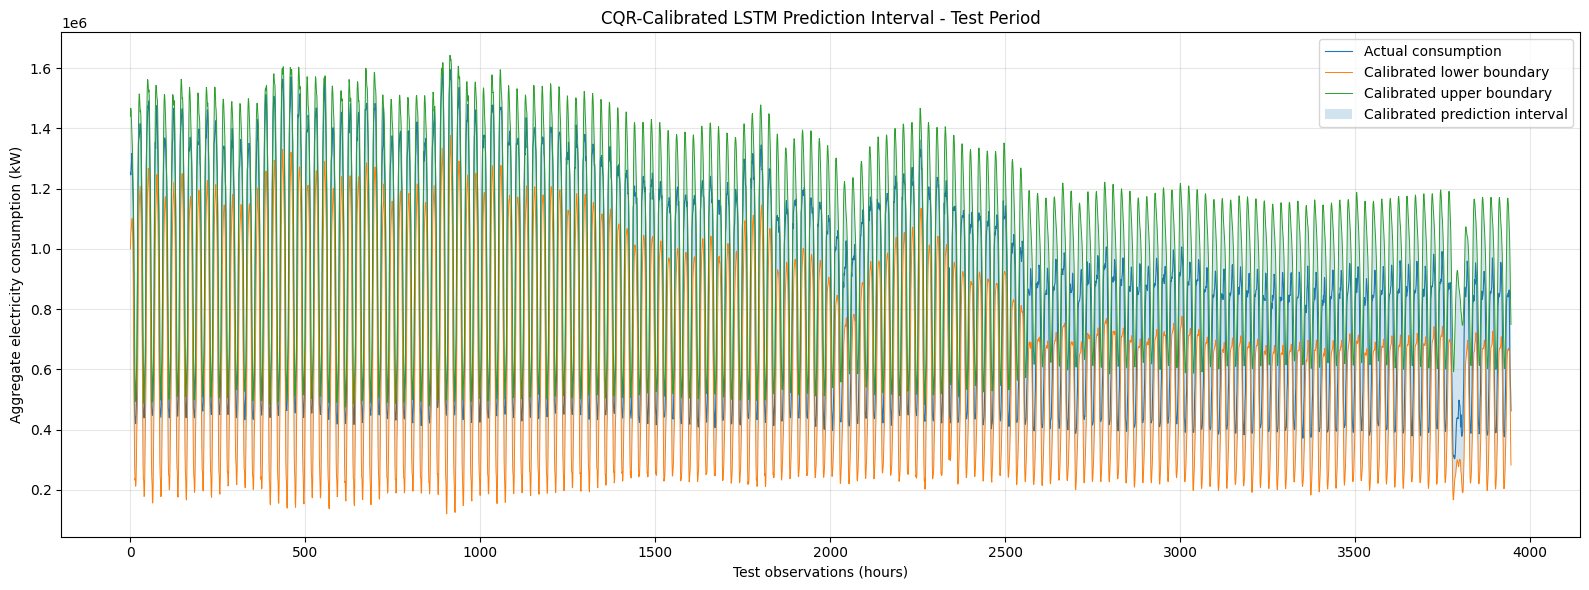

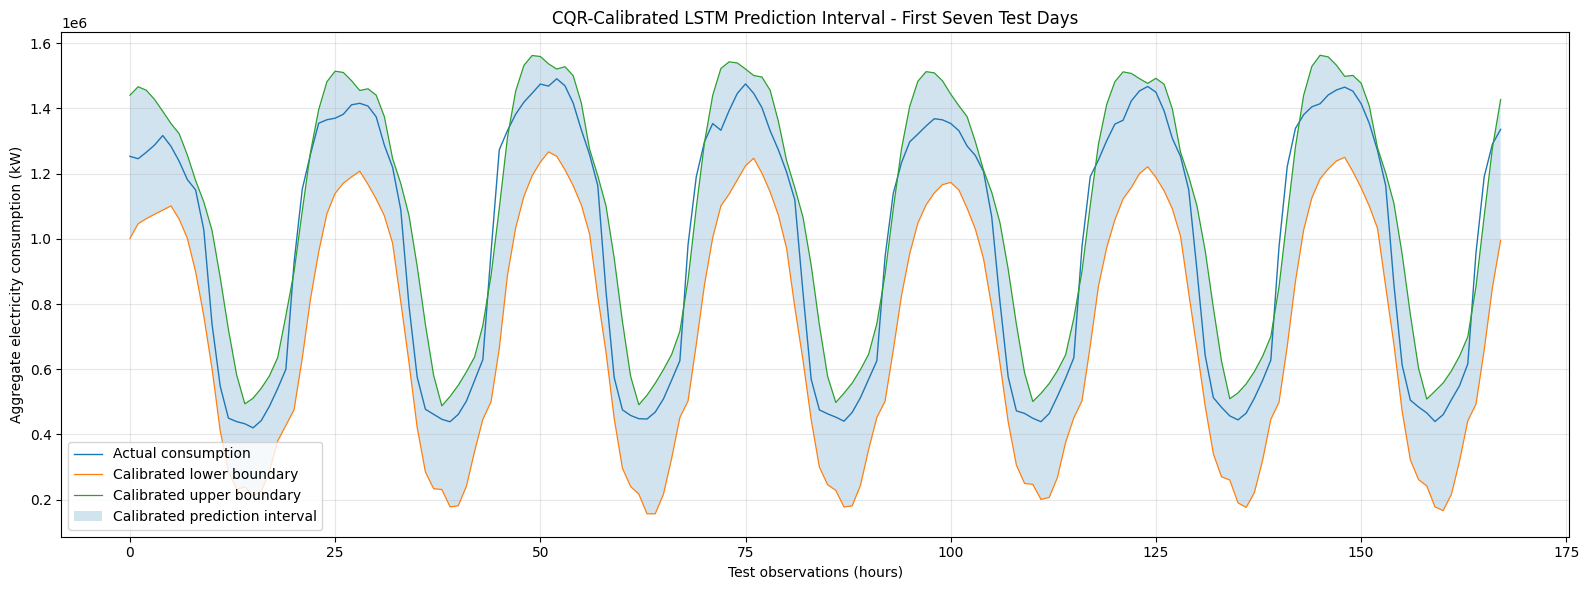


Probabilistic forecasting and calibration completed.
Calibration observations: 1184
Test observations: 3947
Calibration adjustment: 122330.625 kW
Original test PICP: 56.4226 %
Calibrated test PICP: 94.6288 %
Calibrated test MPIW: 386613.62 kW


In [ ]:


# Quantile regression with validation-based conformal calibration

# ----------------------------------------------------------
# 1. VERIFY DATA AND CHRONOLOGICAL SPLIT
# ----------------------------------------------------------

assert len(train) == 18412
assert len(validation) == 3945
assert len(test) == 3947

print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Test observations:", len(test))


# ----------------------------------------------------------
# 2. DIVIDE VALIDATION INTO MODEL-SELECTION AND
#    CALIBRATION PERIODS
# ----------------------------------------------------------

LOOKBACK = 24
UNITS = 32
BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_EPOCHS = 12

LOWER_QUANTILE = 0.025
UPPER_QUANTILE = 0.975
TARGET_COVERAGE = 0.95

# First 70% of validation: early stopping
# Remaining 30%: independent calibration period

validation_tuning_size = int(len(validation) * 0.70)

validation_tuning = validation.iloc[
    :validation_tuning_size
].reset_index(drop=True)

calibration = validation.iloc[
    validation_tuning_size:
].reset_index(drop=True)

print("\nValidation arrangement")
print("Model-selection observations:", len(validation_tuning))
print("Calibration observations:", len(calibration))


# ----------------------------------------------------------
# 3. SET RANDOM SEEDS
# ----------------------------------------------------------

np.random.seed(42)
tf.keras.utils.set_random_seed(42)


# ----------------------------------------------------------
# 4. SCALE DATA USING TRAINING DATA ONLY
# ----------------------------------------------------------

quantile_scaler = MinMaxScaler(feature_range=(0, 1))

q_train_scaled = quantile_scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
)

q_tuning_scaled = quantile_scaler.transform(
    validation_tuning.to_numpy().reshape(-1, 1)
)

q_calibration_scaled = quantile_scaler.transform(
    calibration.to_numpy().reshape(-1, 1)
)

q_test_scaled = quantile_scaler.transform(
    test.to_numpy().reshape(-1, 1)
)


# ----------------------------------------------------------
# 5. CREATE SEQUENTIAL INPUT WINDOWS
# ----------------------------------------------------------

def create_quantile_sequences(values, lookback):

    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])

    return np.asarray(X), np.asarray(y)


X_train_q, y_train_q = create_quantile_sequences(
    q_train_scaled,
    LOOKBACK
)

# Tuning sequences use historical training observations
# followed by the first 70% of validation.

tuning_context = np.concatenate(
    [q_train_scaled[-LOOKBACK:], q_tuning_scaled],
    axis=0
)

X_tuning_q, y_tuning_q = create_quantile_sequences(
    tuning_context,
    LOOKBACK
)

assert len(X_train_q) == len(train) - LOOKBACK
assert len(X_tuning_q) == len(validation_tuning)

print("\nTraining sequence shape:", X_train_q.shape)
print("Tuning sequence shape:", X_tuning_q.shape)


# ----------------------------------------------------------
# 6. DEFINE PINBALL LOSS
# ----------------------------------------------------------

def pinball_loss(quantile):

    def loss(y_true, y_pred):

        error = y_true - y_pred

        return tf.reduce_mean(
            tf.maximum(
                quantile * error,
                (quantile - 1.0) * error
            )
        )

    return loss


# ----------------------------------------------------------
# 7. TRAIN EACH QUANTILE LSTM
# ----------------------------------------------------------

def train_quantile_model(quantile, model_name):

    print("\nTraining:", model_name)
    print("Quantile:", quantile)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        LSTM(UNITS),
        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss=pinball_loss(quantile)
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    start_time = time.time()

    history = model.fit(
        X_train_q,
        y_train_q,
        validation_data=(X_tuning_q, y_tuning_q),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=False,
        verbose=1
    )

    elapsed_time = time.time() - start_time

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    print("Best epoch:", best_epoch)
    print("Training time:", round(elapsed_time, 2), "seconds")

    return model, best_epoch, elapsed_time


# ----------------------------------------------------------
# 8. TRAIN LOWER QUANTILE MODEL
# ----------------------------------------------------------

lower_model, lower_best_epoch, lower_time = (
    train_quantile_model(
        LOWER_QUANTILE,
        "Lower quantile LSTM"
    )
)


# ----------------------------------------------------------
# 9. TRAIN UPPER QUANTILE MODEL
# ----------------------------------------------------------

upper_model, upper_best_epoch, upper_time = (
    train_quantile_model(
        UPPER_QUANTILE,
        "Upper quantile LSTM"
    )
)


# ----------------------------------------------------------
# 10. GENERATE CALIBRATION PREDICTIONS
# ----------------------------------------------------------

# Calibration predictions use the actual preceding
# observations in a rolling one-step-ahead setting.

calibration_context = np.concatenate(
    [
        q_train_scaled[-LOOKBACK:],
        q_tuning_scaled,
        q_calibration_scaled
    ],
    axis=0
)

X_calibration_all, _ = create_quantile_sequences(
    calibration_context,
    LOOKBACK
)

# Remove predictions belonging to the tuning period.

X_calibration_q = X_calibration_all[
    len(validation_tuning):
]

assert len(X_calibration_q) == len(calibration)

lower_cal_scaled = lower_model.predict(
    X_calibration_q,
    verbose=0
)

upper_cal_scaled = upper_model.predict(
    X_calibration_q,
    verbose=0
)

lower_cal_raw = quantile_scaler.inverse_transform(
    lower_cal_scaled
).reshape(-1)

upper_cal_raw = quantile_scaler.inverse_transform(
    upper_cal_scaled
).reshape(-1)

actual_calibration = calibration.to_numpy()

# Order the two boundaries before calculating scores.

calibration_lower = np.minimum(
    lower_cal_raw,
    upper_cal_raw
)

calibration_upper = np.maximum(
    lower_cal_raw,
    upper_cal_raw
)


# ----------------------------------------------------------
# 11. CALCULATE CONFORMAL CALIBRATION SCORES
# ----------------------------------------------------------

# CQR score:
# actual value outside the predicted interval produces
# a positive score; a value inside may produce a negative
# score depending on its distance from the boundaries.

calibration_scores = np.maximum(
    calibration_lower - actual_calibration,
    actual_calibration - calibration_upper
)

calibration_scores = np.asarray(calibration_scores)

n_calibration = len(calibration_scores)

# Finite-sample conformal rank for nominal 95% coverage.

conformal_rank = int(
    np.ceil((n_calibration + 1) * TARGET_COVERAGE)
)

conformal_rank = min(conformal_rank, n_calibration)

q_hat = float(
    np.sort(calibration_scores)[conformal_rank - 1]
)

print("\nConformal calibration")
print("Calibration observations:", n_calibration)
print("Conformal rank:", conformal_rank)
print("Calibration adjustment (kW):", round(q_hat, 4))


# ----------------------------------------------------------
# 12. GENERATE TEST PREDICTIONS
# ----------------------------------------------------------

test_context = np.concatenate(
    [
        q_train_scaled[-LOOKBACK:],
        q_tuning_scaled,
        q_calibration_scaled,
        q_test_scaled
    ],
    axis=0
)

X_test_all, _ = create_quantile_sequences(
    test_context,
    LOOKBACK
)

# Keep only the test-period predictions.

X_test_q = X_test_all[
    len(validation):
]

assert len(X_test_q) == len(test)

lower_test_scaled = lower_model.predict(
    X_test_q,
    verbose=0
)

upper_test_scaled = upper_model.predict(
    X_test_q,
    verbose=0
)

lower_test_raw = quantile_scaler.inverse_transform(
    lower_test_scaled
).reshape(-1)

upper_test_raw = quantile_scaler.inverse_transform(
    upper_test_scaled
).reshape(-1)

actual_test_q = test.to_numpy()


# ----------------------------------------------------------
# 13. CHECK QUANTILE CROSSING
# ----------------------------------------------------------

test_crossing_mask = (
    lower_test_raw > upper_test_raw
)

test_crossing_count = int(
    np.sum(test_crossing_mask)
)

print("\nTest quantile crossings:", test_crossing_count)

# Order the interval boundaries.

baseline_lower = np.minimum(
    lower_test_raw,
    upper_test_raw
)

baseline_upper = np.maximum(
    lower_test_raw,
    upper_test_raw
)


# ----------------------------------------------------------
# 14. APPLY CONFORMAL CALIBRATION
# ----------------------------------------------------------

calibrated_lower = baseline_lower - q_hat
calibrated_upper = baseline_upper + q_hat

# The same calibration adjustment is applied to all
# test observations. No test actual values are used
# to estimate q_hat.


# ----------------------------------------------------------
# 15. CALCULATE BASELINE AND CALIBRATED METRICS
# ----------------------------------------------------------

def evaluate_interval(actual, lower, upper):

    inside = (
        (actual >= lower) &
        (actual <= upper)
    )

    picp_value = np.mean(inside) * 100

    mpiw_value = np.mean(upper - lower)

    outside_value = int(np.sum(~inside))

    return {
        "PICP (%)": picp_value,
        "MPIW (kW)": mpiw_value,
        "Outside observations": outside_value
    }


baseline_results = evaluate_interval(
    actual_test_q,
    baseline_lower,
    baseline_upper
)

calibrated_results = evaluate_interval(
    actual_test_q,
    calibrated_lower,
    calibrated_upper
)

comparison = pd.DataFrame([
    {
        "Method": "Original quantile LSTM",
        **baseline_results
    },
    {
        "Method": "CQR calibrated LSTM",
        **calibrated_results
    }
])

print("\nTEST INTERVAL COMPARISON")
display(comparison.round(4))


# ----------------------------------------------------------
# 16. CALCULATE TEST PINBALL LOSSES
# ----------------------------------------------------------

def calculate_pinball_loss(actual, predicted, quantile):

    error = actual - predicted

    return np.mean(
        np.maximum(
            quantile * error,
            (quantile - 1.0) * error
        )
    )


lower_test_pinball = calculate_pinball_loss(
    actual_test_q,
    lower_test_raw,
    LOWER_QUANTILE
)

upper_test_pinball = calculate_pinball_loss(
    actual_test_q,
    upper_test_raw,
    UPPER_QUANTILE
)

print("\nTest pinball losses")
print("Lower quantile:", round(lower_test_pinball, 6))
print("Upper quantile:", round(upper_test_pinball, 6))


# ----------------------------------------------------------
# 17. DISPLAY TRAINING SUMMARY
# ----------------------------------------------------------

quantile_training_summary = pd.DataFrame([
    {
        "Model": "Lower quantile LSTM",
        "Quantile": LOWER_QUANTILE,
        "Best epoch": lower_best_epoch,
        "Training time (seconds)": lower_time
    },
    {
        "Model": "Upper quantile LSTM",
        "Quantile": UPPER_QUANTILE,
        "Best epoch": upper_best_epoch,
        "Training time (seconds)": upper_time
    }
])

display(quantile_training_summary.round(4))


# ----------------------------------------------------------
# 18. PLOT CALIBRATED INTERVAL - FULL TEST PERIOD
# ----------------------------------------------------------

time_index = np.arange(len(test))

plt.figure(figsize=(16, 6))

plt.plot(
    time_index,
    actual_test_q,
    label="Actual consumption",
    linewidth=0.8
)

plt.plot(
    time_index,
    calibrated_lower,
    label="Calibrated lower boundary",
    linewidth=0.7
)

plt.plot(
    time_index,
    calibrated_upper,
    label="Calibrated upper boundary",
    linewidth=0.7
)

plt.fill_between(
    time_index,
    calibrated_lower,
    calibrated_upper,
    alpha=0.2,
    label="Calibrated prediction interval"
)

plt.title("CQR-Calibrated LSTM Prediction Interval - Test Period")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate electricity consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 19. PLOT FIRST SEVEN TEST DAYS
# ----------------------------------------------------------

hours_to_plot = min(168, len(test))

plt.figure(figsize=(16, 6))

plt.plot(
    time_index[:hours_to_plot],
    actual_test_q[:hours_to_plot],
    label="Actual consumption",
    linewidth=1
)

plt.plot(
    time_index[:hours_to_plot],
    calibrated_lower[:hours_to_plot],
    label="Calibrated lower boundary",
    linewidth=0.9
)

plt.plot(
    time_index[:hours_to_plot],
    calibrated_upper[:hours_to_plot],
    label="Calibrated upper boundary",
    linewidth=0.9
)

plt.fill_between(
    time_index[:hours_to_plot],
    calibrated_lower[:hours_to_plot],
    calibrated_upper[:hours_to_plot],
    alpha=0.2,
    label="Calibrated prediction interval"
)

plt.title("CQR-Calibrated LSTM Prediction Interval - First Seven Test Days")
plt.xlabel("Test observations (hours)")
plt.ylabel("Aggregate electricity consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 20. FINAL VERIFICATION
# ----------------------------------------------------------

print("\nProbabilistic forecasting and calibration completed.")

print("Calibration observations:", len(calibration))
print("Test observations:", len(actual_test_q))
print("Calibration adjustment:", round(q_hat, 4), "kW")

print(
    "Original test PICP:",
    round(baseline_results["PICP (%)"], 4), "%"
)

print(
    "Calibrated test PICP:",
    round(calibrated_results["PICP (%)"], 4), "%"
)

print(
    "Calibrated test MPIW:",
    round(calibrated_results["MPIW (kW)"], 4), "kW"
)


### Interpretation of the Probabilistic Forecasting Results

Two separate LSTM models were developed to estimate the lower 2.5% and upper 97.5% quantiles of hourly electricity consumption.

The validation dataset was divided into a model-selection portion and a separate calibration portion. The calibration procedure used 1,184 observations to calculate the conformal adjustment.

The original prediction interval achieved a test coverage of 56.42%, with an average interval width of 141,952.42 kW.

After conformal calibration, the test coverage increased to 94.63%, while the average interval width increased to 386,613.62 kW. The calibration adjustment was approximately 122,330.63 kW.

The results show that calibration improved the proportion of actual test observations falling within the prediction interval. However, this improvement came with a considerable increase in interval width.

Therefore, the calibrated interval provides greater empirical coverage but a wider range of possible consumption values. This trade-off needs to be considered when using prediction intervals for practical planning.

The observed test coverage is an empirical result for this dataset and does not guarantee the same coverage for future observations.


## 43. Quantile Crossing and Prediction Interval Diagnostics

In the previous section, I developed two separate LSTM models to estimate the lower (2.5%) and upper (97.5%) quantiles of hourly electricity consumption. The resulting prediction intervals were calibrated using Conformalized Quantile Regression (CQR), based on a separate portion of the validation dataset.

During evaluation, I observed that the predicted lower quantile exceeded the predicted upper quantile for some test observations. This issue is known as quantile crossing and can occur when the two quantile models are trained independently.

To ensure that the prediction intervals have correctly ordered boundaries, I used the minimum of the two predicted values as the lower boundary and the maximum as the upper boundary. This adjustment is applied before calculating the calibrated prediction intervals.

In this section, I examine the number and percentage of quantile crossings, verify whether the boundary ordering has been corrected, and compare the average interval width before and after calibration. These diagnostics help assess the consistency and practical usefulness of the prediction intervals.


The calibration improved the observed test coverage, but the increase in interval width also needs to be considered. The resulting coverage is an empirical result on the held-out test period and should not be interpreted as a guarantee of 95% coverage for future observations. Since hourly electricity consumption is time-dependent, the exchangeability assumption used in conventional conformal prediction may not fully hold. Therefore, the interval should be monitored and evaluated again using new observations before practical deployment.

In [ ]:


# Verify the effect of ordering the predicted interval boundaries

# 1. Identify the original quantile crossings

crossing_indices = np.where(test_crossing_mask)[0]

crossing_count = len(crossing_indices)

crossing_percentage = (
    crossing_count / len(test)
) * 100

print("QUANTILE CROSSING ANALYSIS")
print("--------------------------------------")

print("Total test observations:", len(test))
print("Crossings before correction:", crossing_count)
print("Crossing percentage:", round(crossing_percentage, 4), "%")


# 2. Verify the corrected interval boundaries

corrected_crossings = np.sum(
    baseline_lower > baseline_upper
)

print(
    "Crossings after boundary ordering:",
    corrected_crossings
)

assert np.all(baseline_lower <= baseline_upper)

print("Boundary ordering verification: PASSED")


# 3. Calculate interval widths before and after calibration

original_width = baseline_upper - baseline_lower

calibrated_width = calibrated_upper - calibrated_lower

print("\nINTERVAL WIDTH ANALYSIS")
print("--------------------------------------")

print(
    "Original average interval width:",
    round(np.mean(original_width), 2), "kW"
)

print(
    "Calibrated average interval width:",
    round(np.mean(calibrated_width), 2), "kW"
)

print(
    "Calibration adjustment:",
    round(q_hat, 2), "kW"
)


# 4. Display a few examples of quantile crossings

if crossing_count > 0:

    crossing_examples = pd.DataFrame({
        "Test observation": crossing_indices[:10],
        "Original lower quantile": lower_test_raw[crossing_indices[:10]],
        "Original upper quantile": upper_test_raw[crossing_indices[:10]],
        "Corrected lower boundary": baseline_lower[crossing_indices[:10]],
        "Corrected upper boundary": baseline_upper[crossing_indices[:10]]
    })

    print("\nFIRST TEN QUANTILE CROSSING EXAMPLES")
    display(crossing_examples.round(2))

else:
    print("\nNo quantile crossings were detected.")


# 5. Final verification

print("\nFINAL DIAGNOSTIC COMPLETED")


QUANTILE CROSSING ANALYSIS
--------------------------------------
Total test observations: 3947
Crossings before correction: 598
Crossing percentage: 15.1507 %
Crossings after boundary ordering: 0
Boundary ordering verification: PASSED

INTERVAL WIDTH ANALYSIS
--------------------------------------
Original average interval width: 141952.42 kW
Calibrated average interval width: 386613.62 kW
Calibration adjustment: 122330.62 kW

FIRST TEN QUANTILE CROSSING EXAMPLES


,Test observation,Original lower quantile,Original upper quantile,Corrected lower boundary,Corrected upper boundary
0,6,1.200226e+06,1.182792e+06,1.182792e+06,1.200226e+06
1,7,1.134706e+06,1.123977e+06,1.123977e+06,1.134706e+06
2,15,3.888384e+05,3.346093e+05,3.346093e+05,3.888384e+05
3,16,4.194176e+05,3.467925e+05,3.467925e+05,4.194176e+05
4,17,4.576397e+05,4.096702e+05,4.096702e+05,4.576397e+05
5,28,1.332870e+06,1.330087e+06,1.330087e+06,1.332870e+06
6,29,1.338199e+06,1.289797e+06,1.289797e+06,1.338199e+06
7,30,1.318627e+06,1.244895e+06,1.244895e+06,1.318627e+06
8,31,1.252470e+06,1.193096e+06,1.193096e+06,1.252470e+06
9,38,3.655281e+05,3.535247e+05,3.535247e+05,3.655281e+05



FINAL DIAGNOSTIC COMPLETED


### Interpretation of Quantile Crossing and Interval Diagnostics

The two quantile LSTM models were trained independently. As a result, the predicted lower quantile exceeded the predicted upper quantile for some test observations.

Out of 3,947 test observations, 598 quantile crossings were identified, representing approximately 15.15% of the test observations.

To correct the ordering, the smaller of the two predicted values was assigned as the lower boundary and the larger value as the upper boundary. After this adjustment, the number of crossings was reduced to zero, and the boundary-ordering verification was successful.

The average interval width increased from 141,952.42 kW for the original interval to 386,613.62 kW for the calibrated interval.

This confirms that the interval boundaries are correctly ordered after correction. However, correct ordering alone does not establish the accuracy of the interval. Coverage and interval width must also be considered when assessing its usefulness.

## 44. Forecast to Action

The main purpose of developing a forecasting model is not only to predict future electricity consumption but also to use the predicted values to support practical decisions. In this project, hourly aggregate electricity consumption was forecast using different statistical and neural network models. The results show that the SARIMA model provided the best overall point forecasting performance among the six models evaluated.

The selected SARIMA model, with order (2,1,3) and seasonal order (1,0,1,24), achieved a test RMSE of 23,891.46 kW, MAE of 14,366.74 kW, MAPE of 1.811% and R² of 0.9950. These results indicate that the model was able to capture the hourly consumption pattern with relatively low forecasting errors during the test period.

### 44.1 How the Forecast Can Support Decisions

The hourly forecasts generated by the SARIMA model can be used as an input for short-term electricity demand planning. By estimating the expected consumption for the next hour, the concerned team can review anticipated demand and prepare for possible increases or decreases in electricity usage.

The forecasts could support decision-making in the following ways:

1. **Anticipating higher consumption:** Forecasted hourly consumption can help identify periods when demand is expected to increase. The concerned team can review these periods in advance and plan the availability of required resources.

2. **Planning electricity requirements:** Expected consumption can support short-term planning of electricity requirements and coordination with the relevant electricity supply or facility management team.

3. **Managing flexible electricity usage:** Where operationally possible, non-essential or flexible activities can be scheduled during periods when forecast consumption is relatively lower. This may help avoid adding unnecessary demand during anticipated peak periods.

4. **Monitoring unusual consumption:** Actual consumption can be compared with the forecast. A considerable difference between the two may indicate an unexpected change in usage and can be examined further by the concerned team.

### 44.2 Proposed Forecast-to-Action Process

The following process illustrates how the forecasting results could be incorporated into routine electricity demand planning:

1. Obtain the latest hourly electricity consumption observations.
2. Generate the next-hour consumption forecast using the selected SARIMA model.
3. Compare the forecast with recent consumption and the expected demand pattern.
4. Identify periods during which higher consumption is anticipated.
5. Review resource availability and consider suitable adjustments to flexible electricity usage, wherever feasible.
6. Compare actual consumption with the forecast after the hour is completed and monitor the forecasting performance.

This process can be repeated as new hourly observations become available. Since the model was evaluated using one-step-ahead forecasts, the proposed application is also based on updating the forecast as new consumption data are received.

### 44.3 Practical Benefit and Limitations

The test results indicate that the SARIMA model can provide useful information for short-term consumption planning. Its lower forecasting error compared with the other models makes it the preferred point forecasting model in this experiment.

The original historical dataset does not contain actual electricity tariffs, procurement costs, equipment capacity limits or operational intervention records. Therefore, actual savings cannot be established directly from the source data. To demonstrate a possible management application without changing the real forecasting experiment, a separate synthetic operational and financial simulation is presented in Section 46.

In that simulation, the existing SARIMA test forecasts are compared with a training-derived peak-demand threshold. Under the stated assumptions, a 2% flexible-load shift produces a net simulated saving of ₹1,64,96,127.45 (approximately ₹164.96 lakh). This amount is conditional on the assumed tariff schedule, demand-charge calculation, flexible-load share and intervention cost. It is not an observed saving or a verified reduction in the electricity expenditure of the 321 consumers.

In terms of forecasting improvement, the selected SARIMA model reduced test RMSE by 58.17% compared with the non-seasonal ARIMA model and by approximately 32.0% compared with the Simple RNN. These are improvements in forecasting accuracy, not direct monetary savings.

Overall, SARIMA provides a useful forecasting basis for hourly electricity demand planning. The financial simulation illustrates one possible forecast-to-action pathway, but real implementation would require validation using actual tariff schedules, available flexible loads, equipment and process constraints, and measured operational costs.

## 45. Risk and Reliability

Forecasting future electricity consumption involves uncertainty because actual consumption may differ from the predicted value. Changes in usage patterns and unexpected events can affect the accuracy of a forecast. Therefore, relying only on a single predicted value may not provide sufficient information for decisions that involve electricity demand planning.

To examine this uncertainty, two LSTM models were developed in this project to estimate the lower 2.5% and upper 97.5% quantiles. These estimates were used to construct a prediction interval. The interval was subsequently calibrated using Conformalized Quantile Regression (CQR), with a separate calibration portion of the validation dataset.

### 45.1 Evaluation of Prediction Interval Reliability

The performance of the prediction interval was evaluated using Prediction Interval Coverage Probability (PICP) and Mean Prediction Interval Width (MPIW).

The results obtained on the test dataset are presented below.

| Evaluation measure | Original interval | Calibrated interval |
|---|---:|---:|
| Test observations | 3,947 | 3,947 |
| PICP | 56.42% | 94.63% |
| Observations outside interval | 1,720 | 212 |
| MPIW | 141,952.42 kW | 386,613.62 kW |

The conformal calibration adjustment was 122,330.63 kW. This adjustment expanded the lower and upper prediction boundaries to improve the empirical coverage of the prediction interval on the test dataset.

The original prediction interval covered approximately 56.42% of the actual test observations. After calibration, the coverage increased to approximately 94.63%. Out of 3,947 test observations, 212 actual values remained outside the calibrated interval, representing approximately 5.37% of the observations.

This indicates that calibration substantially improved the empirical coverage on the held-out test dataset. However, this result alone does not establish that the same coverage will be maintained for future observations.

This improvement in coverage came with an increase in the average interval width. The calibrated MPIW was approximately 386,613.62 kW, compared with 141,952.42 kW for the original interval. This indicates that the calibrated interval is considerably wider and provides a less precise range of possible consumption values.

### 45.2 How Prediction Intervals Can Support Decisions

The prediction interval provides a range within which the actual hourly consumption may fall, rather than presenting only one estimated value.

This information can support practical planning in the following ways:

1. **Planning for higher demand:** The upper prediction boundary can be considered when reviewing the possibility of higher electricity consumption. It can help the concerned team examine whether sufficient resources are likely to be available.

2. **Planning under uncertainty:** When the prediction interval is wide, it indicates greater uncertainty in the estimated consumption range. In such situations, decisions should be made cautiously rather than relying only on the point forecast.

3. **Monitoring unexpected consumption:** If actual consumption falls outside the predicted interval, the deviation can be examined to understand whether there has been an unusual change in usage or whether the forecasting model requires further review.

4. **Reviewing operational readiness:** The forecast range can be considered along with available capacity and operational requirements before making decisions concerning electricity usage and resource allocation.

The upper prediction boundary should not automatically be treated as a required reserve capacity. Any operational threshold or reserve requirement must be established using actual system capacity, operating conditions and the requirements of the concerned organisation.

### 45.3 Risks and Limitations

Although the calibrated interval achieved an observed test coverage of 94.63%, this result should not be interpreted as a guarantee that 95% of future observations will fall within the interval.

The main limitations identified in this project are:

- **Forecasting errors:** Even the best-performing point forecasting model may produce differences between predicted and actual consumption. The SARIMA model recorded a test RMSE of 23,891.46 kW and MAE of 14,366.74 kW.

- **Wide prediction intervals:** The calibrated MPIW of 386,613.62 kW indicates that the range of possible consumption values is relatively wide. Although coverage improved, the interval may be less useful for decisions requiring a highly precise estimate.

- **Time-dependent observations:** Hourly electricity consumption observations are sequential and may be dependent on earlier observations. The exchangeability assumption used in conventional conformal prediction may therefore not fully hold. Consequently, the observed coverage on the test dataset does not establish guaranteed future coverage.

- **Changes in consumption patterns:** Unexpected changes in electricity usage may affect model performance. The forecasting model should therefore be monitored and periodically evaluated using newly available observations.

### 45.4 Measures to Improve Reliability

The following measures could be considered before using the forecasting approach in an operational setting:

1. Compare forecast values with actual consumption regularly and maintain records of forecasting errors.
2. Re-evaluate prediction interval coverage and width using newly available observations.
3. Review periods where actual consumption falls outside the predicted interval and identify possible reasons for the deviation.
4. Reassess the model parameters when a consistent deterioration in forecasting performance is observed.
5. Establish operational thresholds using actual capacity, electricity requirements and the organisation's risk tolerance.

### 45.5 Overall Assessment

The probabilistic forecasting approach provides additional information about uncertainty that is not available from point forecasting alone. In this experiment, calibration increased the observed test coverage from 56.42% to 94.63%, although the average interval width also increased substantially.

Therefore, the calibrated LSTM interval can be considered a supplementary input for planning under uncertainty, rather than a precise estimate of future electricity requirements. Its practical usefulness depends on balancing interval coverage with interval width and continuously monitoring its performance.

The results suggest that combining the SARIMA point forecast with the prediction interval information can provide a more informed basis for electricity demand planning. However, further evaluation using new observations and actual operational data would be necessary before adopting this approach for routine decision-making.

## 46. Forecast-Based Demand Management: Synthetic Operational and Financial Simulation

### 46.1 Purpose and Boundary of This Extension

The forecasting experiment presented in the earlier sections uses the original historical electricity consumption dataset and its unchanged chronological test set. The present section extends that analysis by examining how the selected SARIMA forecasts could support a practical demand-management decision.

The original dataset does not contain actual electricity tariff schedules, contracted-demand arrangements, flexible-load records or operational intervention costs. Therefore, a separate illustrative operational and financial simulation is developed using the existing SARIMA test predictions.

This extension does not modify the original observations, model training process, forecasting results or reported model evaluation metrics. The actual test-period demand and saved one-step-ahead SARIMA forecasts are used as the forecasting inputs. The tariff rates, flexible-load availability, demand-charge arrangement and intervention cost are introduced as assumptions for the simulation.

Accordingly, the financial results presented in this section represent simulated outcomes under the specified assumptions. They should not be interpreted as actual savings achieved by the consumers represented in the original dataset.

### 46.2 Decision Question

The simulation examines the following decision question:

Can a next-hour SARIMA forecast identify unusually high electricity demand during an assumed high-tariff period and trigger a limited shift of flexible electricity consumption to a lower-tariff period?

The objective is to connect the forecasting output with a possible operational response and evaluate its potential financial implications under a clearly defined hypothetical scenario.

### 46.3 Scenario Assumptions

The following assumptions are used to construct the base-case simulation.

| Item | Assumption used in the base case |
|---|---:|
| Peak window | 17:00–21:59 (hours 17–21) |
| Off-peak tariff | ₹4.50 per kWh |
| Standard tariff | ₹7.00 per kWh |
| Peak tariff | ₹10.00 per kWh |
| Shoulder tariff | ₹5.50 per kWh |
| Peak-demand trigger | 90th percentile of training-period demand during hours 17–21 |
| Flexible load available | 2% of forecast demand in a triggered hour |
| Rescheduling destination | 22:00 and 23:00, split equally |
| Hypothetical contracted-demand cap | 90th percentile of training-period peak-window demand |
| Demand charge above cap | ₹100 per kW per month |
| Operating/intervention cost | ₹0.25 per shifted kWh |
| Forecasting information | Existing one-step-ahead SARIMA test forecast only |

These values are treated as assumptions for a controlled scenario. They are not presented as official electricity tariffs or measured operating characteristics of the consumers in the dataset.

The hypothetical contracted-demand cap is set equal to the 90th percentile of training-period demand during the peak window. A monthly demand charge is applied only to demand exceeding this assumed cap.

The simulation is designed to preserve total energy consumption. Energy shifted out of a triggered peak hour is added to the 22:00 and 23:00 shoulder hours on the same date. Therefore, the exercise represents a change in the timing of electricity consumption rather than a reduction in total energy usage.

### 46.4 Decision Logic

For every test-set observation falling between 17:00 and 21:00, the SARIMA forecast is compared with the 90th-percentile demand threshold calculated from the training period for the same peak window.

A demand-management action is triggered when the forecast is equal to or greater than this threshold. When a trigger occurs, the simulation schedules 2% of the forecasted hourly energy out of the peak hour and distributes the shifted quantity equally between 22:00 and 23:00.

The decision is based on the forecast available before the target hour. Actual demand is not used to decide whether a forecast-based trigger should occur. It is used after the event for evaluating the forecast-based decision and checking the feasibility of the simulated shift.

A separate actual-demand threshold is used as an evaluation benchmark to classify the forecast decisions as true positives, false positives, false negatives and true negatives. This benchmark is not used to generate the forecast-based action.

The simulation compares two electricity-consumption profiles:

1. **Baseline profile:** The original consumption profile without any load shifting.
2. **Managed profile:** The consumption profile after applying the forecast-triggered load-shifting actions.

### 46.5 Simulation Implementation

The simulation is implemented using the saved SARIMA test-prediction file, `SARIMA_Test_Predictions.csv`. The file contains the timestamp, actual demand and corresponding SARIMA forecast for each test observation.

Before performing the calculations, the prediction file is loaded and checked for the required columns, valid timestamps, numeric demand and forecast values, and the expected number of test observations. The chronological sequence is also checked to ensure that the prediction records are suitable for the analysis.

The training-period 90th-percentile peak-demand threshold is then used to identify forecast-triggered hours. For each triggered hour, the specified flexible-load share is calculated and scheduled for transfer to the two shoulder hours on the same date.

The baseline and managed consumption profiles are compared to estimate the change in energy-tariff costs. The simulation also calculates the monthly demand charges under the assumed contracted-demand cap and demand-charge rate. The intervention cost is deducted from the gross simulated savings to obtain the net simulated financial outcome.

The forecast-trigger decisions are evaluated separately against the actual-demand benchmark. Precision and recall are calculated to examine how effectively the forecast-based rule identifies high-demand observations within the defined peak window.

A sensitivity analysis is also carried out by changing the flexible-load share and the assumed demand-charge rate. This helps examine how the estimated financial outcome changes when the scenario assumptions are varied.

**Feasibility consideration:** The implementation includes a check to ensure that the proposed shifted quantity does not exceed the actual demand recorded for the relevant test observation. This is a retrospective feasibility check using information available after the target hour. It is not part of the forecast-trigger decision and should not be interpreted as information available to an operator in advance. In a real operational setting, the available flexible load would need to be identified using operational records and equipment constraints before the action is implemented.

The following code performs the simulation using the saved SARIMA test predictions. It does not retrain or modify any of the forecasting models developed in the earlier sections.

SARIMA prediction file loaded and validated.
Test observations: 3947
Test period: 2014-07-20 13:00:01 to 2014-12-31 23:00:01
Training 90th-percentile peak threshold: 1,421,951.60 kW

FINANCIAL SUMMARY


,Base scenario
Test period start,2014-07-20 13:00:01
Test period end,2014-12-31 23:00:01
Test observations (hours),3947
Training peak threshold (kW),1421951.6
Forecast-triggered peak hours,60
True positives,53
False positives,7
False negatives,7
True negatives,758
Decision precision (%),88.333333



SENSITIVITY ANALYSIS


,Flexible share (%),Demand charge rate (INR/kW/month),Scenario status,Energy tariff saving (INR),Demand charge saving (INR),Intervention cost (INR),Net simulated saving (INR)
0,1.0,50.0,Feasible,3982000.57,2243642.71,221222.25,6004421.02
1,1.0,100.0,Feasible,3982000.57,4487285.41,221222.25,8248063.73
2,1.0,150.0,Feasible,3982000.57,6730928.12,221222.25,10491706.43
3,2.0,50.0,Feasible,7964001.13,4487285.41,442444.51,12008842.04
4,2.0,100.0,Feasible,7964001.13,8974570.82,442444.51,16496127.45
5,2.0,150.0,Feasible,7964001.13,13461856.24,442444.51,20983412.86
6,3.0,50.0,Feasible,11946001.70,6730928.12,663666.76,18013263.06
7,3.0,100.0,Feasible,11946001.70,13461856.24,663666.76,24744191.18
8,3.0,150.0,Feasible,11946001.70,20192784.35,663666.76,31475119.29



MONTHLY DEMAND SUMMARY


,month,baseline_monthly_peak_kW,managed_monthly_peak_kW,baseline_excess_kW,managed_excess_kW,baseline_demand_charge_INR,managed_demand_charge_INR
0,2014-07,1491229.0,1461799.07,69277.4,39847.47,6927740.0,3984747.05
1,2014-08,1602102.0,1570844.04,180150.4,148892.44,18015040.0,14889243.81
2,2014-09,1477851.0,1448793.18,55899.4,26841.58,5589940.0,2684158.32
3,2014-10,1319820.0,1319820.00,0.0,0.00,0.0,0.00
4,2014-11,1143133.0,1143133.00,0.0,0.00,0.0,0.00
5,2014-12,991182.0,991182.00,0.0,0.00,0.0,0.00


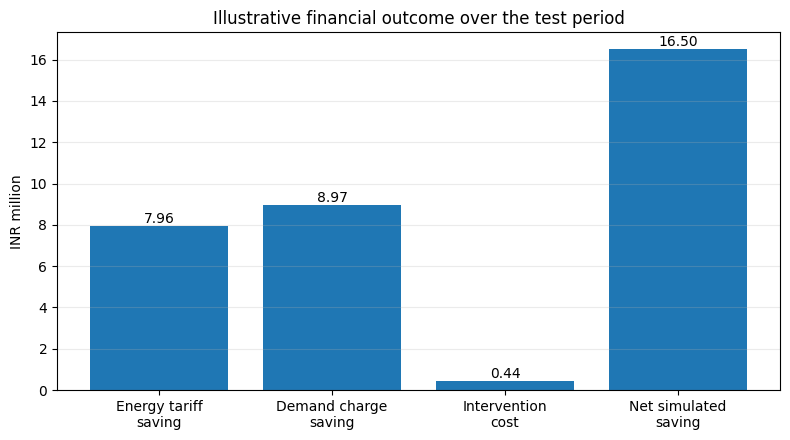

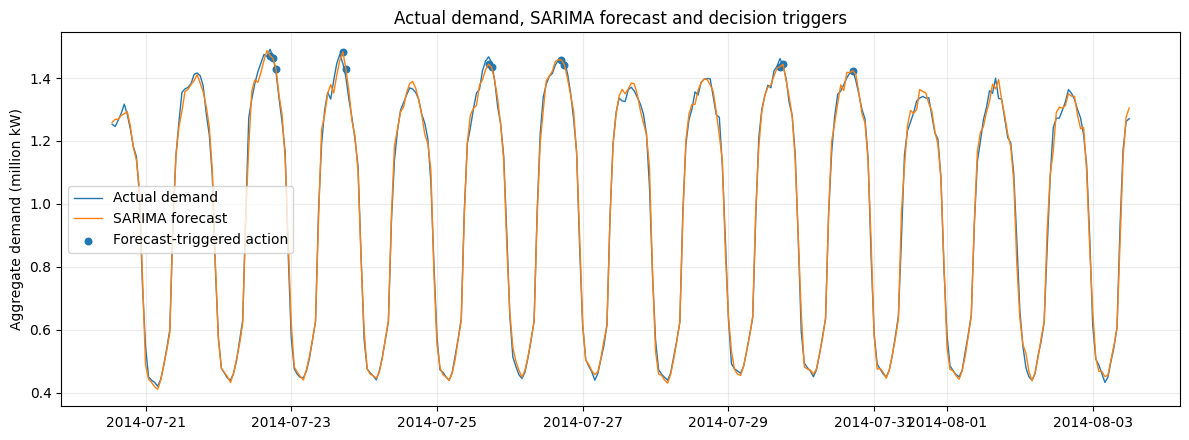


Section 46 simulation completed.
No forecasting model was retrained or modified.
All financial values are illustrative simulation results,
not verified actual electricity-bill savings.


In [ ]:

# ============================================================
# SECTION 46: SYNTHETIC OPERATIONAL / FINANCIAL DECISION SIMULATION
# Uses saved SARIMA test predictions.
# Does NOT retrain or modify any forecasting model.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from google.colab import files

# ------------------------------------------------------------
# 1. LOAD SAVED SARIMA TEST PREDICTIONS
# ------------------------------------------------------------

prediction_file = "SARIMA_Test_Predictions.csv"

if not os.path.exists(prediction_file):
    print("Please upload SARIMA_Test_Predictions.csv")
    uploaded = files.upload()

    if prediction_file not in uploaded:
        raise FileNotFoundError(
            "SARIMA_Test_Predictions.csv was not uploaded."
        )

predictions_df = pd.read_csv(prediction_file)

required_columns = [
    "timestamp",
    "actual_demand_kW",
    "sarima_forecast_kW"
]

if not all(col in predictions_df.columns for col in required_columns):
    raise ValueError("The prediction CSV does not contain the required columns.")

predictions_df = predictions_df[required_columns].copy()
predictions_df["timestamp"] = pd.to_datetime(
    predictions_df["timestamp"], errors="coerce"
)

for col in ["actual_demand_kW", "sarima_forecast_kW"]:
    predictions_df[col] = pd.to_numeric(
        predictions_df[col], errors="coerce"
    )

if len(predictions_df) != 3947:
    raise ValueError(
        f"Expected 3947 test observations, found {len(predictions_df)}."
    )

if predictions_df.isnull().any().any():
    raise ValueError("Missing or invalid values found in prediction CSV.")

if not np.isfinite(
    predictions_df[["actual_demand_kW", "sarima_forecast_kW"]].to_numpy()
).all():
    raise ValueError("Non-finite values found in the prediction CSV.")

if (
    (predictions_df["actual_demand_kW"] < 0).any()
    or (predictions_df["sarima_forecast_kW"] < 0).any()
):
    raise ValueError("Negative demand values found.")

if not predictions_df["timestamp"].is_monotonic_increasing:
    raise ValueError("Timestamps are not in chronological order.")

if predictions_df["timestamp"].duplicated().any():
    raise ValueError("Duplicate timestamps found.")

if not predictions_df["timestamp"].diff().dropna().dt.total_seconds().eq(3600).all():
    raise ValueError("Test timestamps are not separated by exactly one hour.")

# Verify that the uploaded predictions correspond to the current test split,
# whenever the original dataset and split are available in this runtime.
if all(name in globals() for name in ["df", "train", "validation", "test"]):
    assert len(train) == 18412
    assert len(validation) == 3945
    assert len(test) == 3947

    test_start = len(train) + len(validation)
    test_end = test_start + len(test)

    expected_timestamps = pd.to_datetime(
        df["timestamp"].iloc[test_start:test_end]
    ).reset_index(drop=True)

    expected_actual = np.asarray(test, dtype=float)

    if not np.array_equal(
        predictions_df["timestamp"].reset_index(drop=True).to_numpy(),
        expected_timestamps.to_numpy()
    ):
        raise ValueError(
            "CSV timestamps do not match the current test dataset."
        )

    if not np.allclose(
        predictions_df["actual_demand_kW"].to_numpy(),
        expected_actual,
        rtol=0,
        atol=1e-6
    ):
        raise ValueError(
            "CSV actual demand does not match the current test split."
        )

simulation = predictions_df.copy()

print("SARIMA prediction file loaded and validated.")
print("Test observations:", len(simulation))
print("Test period:", simulation["timestamp"].min(),
      "to", simulation["timestamp"].max())

# ------------------------------------------------------------
# 2. PREPARE HOURLY TEST DATA
# ------------------------------------------------------------

simulation["hour"] = simulation["timestamp"].dt.hour
simulation["date"] = simulation["timestamp"].dt.date

simulation["peak_window"] = simulation["hour"].between(17, 21)

# Each observation represents one hour.
# Therefore, kW multiplied by one hour is numerically equal to kWh.
simulation["baseline_energy_kWh"] = simulation["actual_demand_kW"].astype(float)

# ------------------------------------------------------------
# 3. DEFINE ILLUSTRATIVE TIME-OF-USE TARIFF
# ------------------------------------------------------------

def illustrative_tariff(hour):
    if 0 <= hour <= 5:
        return 4.50
    elif 6 <= hour <= 16:
        return 7.00
    elif 17 <= hour <= 21:
        return 10.00
    else:
        return 5.50

simulation["assumed_tariff_INR_per_kWh"] = (
    simulation["hour"].map(illustrative_tariff).astype(float)
)

# ------------------------------------------------------------
# 4. CALCULATE HIGH-DEMAND THRESHOLD USING TRAINING DATA ONLY
# ------------------------------------------------------------

if "train" not in globals() or "df" not in globals():
    raise RuntimeError(
        "Training data and prepared dataset are required to calculate "
        "the training-only demand threshold. Restore df and train first."
    )

train_timestamps = pd.to_datetime(
    df["timestamp"].iloc[:len(train)]
)

training_peak_mask = train_timestamps.dt.hour.between(17, 21)

peak_threshold_kW = float(
    train.loc[training_peak_mask.to_numpy()].quantile(0.90)
)

print(f"Training 90th-percentile peak threshold: {peak_threshold_kW:,.2f} kW")

# ------------------------------------------------------------
# 5. APPLY FORECAST-BASED DECISION RULE
# ------------------------------------------------------------

flexible_share = 0.02
operating_cost_per_shifted_kWh = 0.25

peak_tariff = 10.00
shoulder_tariff = 5.50

simulation["forecast_trigger"] = (
    simulation["peak_window"]
    & (simulation["sarima_forecast_kW"] >= peak_threshold_kW)
)

simulation["planned_shift_kWh"] = np.where(
    simulation["forecast_trigger"],
    flexible_share * simulation["sarima_forecast_kW"],
    0.0
)

# Retrospective feasibility check: planned shift cannot exceed
# the realised demand in the corresponding test hour.
if (
    simulation["planned_shift_kWh"]
    > simulation["actual_demand_kW"]
).any():
    raise ValueError(
        "The planned shift exceeds actual hourly demand. "
        "Review the flexible-load assumption."
    )

# ------------------------------------------------------------
# 6. CREATE MANAGED ENERGY PROFILE
# ------------------------------------------------------------

simulation["managed_energy_kWh"] = simulation["baseline_energy_kWh"]

trigger_mask = simulation["forecast_trigger"]

simulation.loc[trigger_mask, "managed_energy_kWh"] -= (
    simulation.loc[trigger_mask, "planned_shift_kWh"]
)

daily_shift = simulation.groupby("date")["planned_shift_kWh"].sum()

for operating_date, shifted_energy in daily_shift.items():

    if shifted_energy <= 0:
        continue

    destination_rows = simulation.index[
        (simulation["date"] == operating_date)
        & (simulation["hour"].isin([22, 23]))
    ]

    if len(destination_rows) != 2:
        raise ValueError(
            f"Both 22:00 and 23:00 destination hours are required "
            f"for {operating_date}."
        )

    simulation.loc[destination_rows, "managed_energy_kWh"] += (
        shifted_energy / 2.0
    )

# ------------------------------------------------------------
# 7. VERIFY ENERGY CONSERVATION
# ------------------------------------------------------------

baseline_total_energy = simulation["baseline_energy_kWh"].sum()
managed_total_energy = simulation["managed_energy_kWh"].sum()

energy_balance_difference = (
    managed_total_energy - baseline_total_energy
)

if abs(energy_balance_difference) >= 1e-5:
    raise ValueError("Energy conservation check failed.")

if (simulation["managed_energy_kWh"] < 0).any():
    raise ValueError("Managed energy profile contains negative values.")

# ------------------------------------------------------------
# 8. CALCULATE ENERGY COSTS AND HYPOTHETICAL DEMAND CHARGES
# ------------------------------------------------------------

simulation["baseline_energy_cost_INR"] = (
    simulation["baseline_energy_kWh"]
    * simulation["assumed_tariff_INR_per_kWh"]
)

simulation["managed_energy_cost_INR"] = (
    simulation["managed_energy_kWh"]
    * simulation["assumed_tariff_INR_per_kWh"]
)

baseline_energy_cost_INR = (
    simulation["baseline_energy_cost_INR"].sum()
)

managed_energy_cost_INR = (
    simulation["managed_energy_cost_INR"].sum()
)

energy_tariff_saving_INR = (
    baseline_energy_cost_INR - managed_energy_cost_INR
)

demand_charge_rate_INR_per_kW_month = 100.00

peak_hours_only = simulation.loc[
    simulation["peak_window"]
].copy()

monthly_demand = (
    peak_hours_only.groupby(
        peak_hours_only["timestamp"].dt.to_period("M")
    )
    .agg(
        baseline_monthly_peak_kW=("baseline_energy_kWh", "max"),
        managed_monthly_peak_kW=("managed_energy_kWh", "max")
    )
    .reset_index()
)

monthly_demand.rename(
    columns={"timestamp": "month"},
    inplace=True
)

monthly_demand["baseline_excess_kW"] = (
    monthly_demand["baseline_monthly_peak_kW"]
    - peak_threshold_kW
).clip(lower=0)

monthly_demand["managed_excess_kW"] = (
    monthly_demand["managed_monthly_peak_kW"]
    - peak_threshold_kW
).clip(lower=0)

monthly_demand["baseline_demand_charge_INR"] = (
    monthly_demand["baseline_excess_kW"]
    * demand_charge_rate_INR_per_kW_month
)

monthly_demand["managed_demand_charge_INR"] = (
    monthly_demand["managed_excess_kW"]
    * demand_charge_rate_INR_per_kW_month
)

demand_charge_saving_INR = (
    monthly_demand["baseline_demand_charge_INR"].sum()
    - monthly_demand["managed_demand_charge_INR"].sum()
)

gross_saving_INR = (
    energy_tariff_saving_INR + demand_charge_saving_INR
)

total_shifted_kWh = simulation["planned_shift_kWh"].sum()

intervention_cost_INR = (
    total_shifted_kWh * operating_cost_per_shifted_kWh
)

net_simulated_saving_INR = (
    gross_saving_INR - intervention_cost_INR
)

baseline_cost_INR = (
    baseline_energy_cost_INR
    + monthly_demand["baseline_demand_charge_INR"].sum()
)

managed_cost_INR = (
    managed_energy_cost_INR
    + monthly_demand["managed_demand_charge_INR"].sum()
    + intervention_cost_INR
)

# ------------------------------------------------------------
# 9. EVALUATE FORECAST-BASED DECISION PERFORMANCE
# ------------------------------------------------------------

simulation["actual_high_demand"] = (
    simulation["peak_window"]
    & (simulation["actual_demand_kW"] >= peak_threshold_kW)
)

peak_evaluation = simulation.loc[
    simulation["peak_window"]
]

tn, fp, fn, tp = confusion_matrix(
    peak_evaluation["actual_high_demand"],
    peak_evaluation["forecast_trigger"],
    labels=[False, True]
).ravel()

precision = tp / (tp + fp) if (tp + fp) else np.nan
recall = tp / (tp + fn) if (tp + fn) else np.nan

# ------------------------------------------------------------
# 10. SENSITIVITY ANALYSIS
# ------------------------------------------------------------

sensitivity_rows = []

for share in [0.01, 0.02, 0.03]:

    shifts_for_share = np.where(
        simulation["forecast_trigger"],
        share * simulation["sarima_forecast_kW"],
        0.0
    )

    # Check feasibility separately for every flexible-load scenario.
    if (
        shifts_for_share > simulation["actual_demand_kW"].to_numpy()
    ).any():
        sensitivity_rows.append({
            "Flexible share (%)": share * 100,
            "Demand charge rate (INR/kW/month)": np.nan,
            "Scenario status": "Infeasible",
            "Energy tariff saving (INR)": np.nan,
            "Demand charge saving (INR)": np.nan,
            "Intervention cost (INR)": np.nan,
            "Net simulated saving (INR)": np.nan
        })
        continue

    managed_profile = (
        simulation["baseline_energy_kWh"].to_numpy().copy()
    )

    managed_profile -= shifts_for_share

    shifts_by_date = pd.Series(
        shifts_for_share,
        index=simulation.index
    ).groupby(simulation["date"]).sum()

    for operating_date, shifted_energy in shifts_by_date.items():

        if shifted_energy <= 0:
            continue

        destination_rows = simulation.index[
            (simulation["date"] == operating_date)
            & (simulation["hour"].isin([22, 23]))
        ]

        if len(destination_rows) != 2:
            raise ValueError(
                f"Missing destination hours for {operating_date}."
            )

        managed_profile[destination_rows] += shifted_energy / 2.0

    if np.any(managed_profile < 0):
        raise ValueError("Sensitivity scenario creates negative demand.")

    if abs(
        managed_profile.sum()
        - simulation["baseline_energy_kWh"].sum()
    ) >= 1e-5:
        raise ValueError("Sensitivity scenario violates energy conservation.")

    temp = simulation[
        ["timestamp", "hour", "baseline_energy_kWh"]
    ].copy()

    temp["managed_energy_kWh"] = managed_profile

    temp["baseline_peak_kW"] = np.where(
        temp["hour"].between(17, 21),
        temp["baseline_energy_kWh"],
        0.0
    )

    temp["managed_peak_kW"] = np.where(
        temp["hour"].between(17, 21),
        temp["managed_energy_kWh"],
        0.0
    )

    temp["month"] = temp["timestamp"].dt.to_period("M")

    monthly_temp = temp.groupby("month").agg(
        baseline_peak=("baseline_peak_kW", "max"),
        managed_peak=("managed_peak_kW", "max")
    )

    peak_reduction_kW_month = (
        (monthly_temp["baseline_peak"] - peak_threshold_kW).clip(lower=0)
        - (monthly_temp["managed_peak"] - peak_threshold_kW).clip(lower=0)
    ).sum()

    shifted_kWh = shifts_for_share.sum()

    energy_saving = shifted_kWh * (
        peak_tariff - shoulder_tariff
    )

    intervention = (
        shifted_kWh * operating_cost_per_shifted_kWh
    )

    for demand_rate in [50.0, 100.0, 150.0]:

        demand_saving = (
            peak_reduction_kW_month * demand_rate
        )

        sensitivity_rows.append({
            "Flexible share (%)": share * 100,
            "Demand charge rate (INR/kW/month)": demand_rate,
            "Scenario status": "Feasible",
            "Energy tariff saving (INR)": energy_saving,
            "Demand charge saving (INR)": demand_saving,
            "Intervention cost (INR)": intervention,
            "Net simulated saving (INR)": (
                energy_saving + demand_saving - intervention
            )
        })

sensitivity_table = pd.DataFrame(sensitivity_rows)

# ------------------------------------------------------------
# 11. PREPARE FINANCIAL SUMMARY
# ------------------------------------------------------------

financial_summary = pd.DataFrame([{
    "Test period start": simulation["timestamp"].min(),
    "Test period end": simulation["timestamp"].max(),
    "Test observations (hours)": len(simulation),
    "Training peak threshold (kW)": peak_threshold_kW,
    "Forecast-triggered peak hours": int(
        simulation["forecast_trigger"].sum()
    ),
    "True positives": int(tp),
    "False positives": int(fp),
    "False negatives": int(fn),
    "True negatives": int(tn),
    "Decision precision (%)": precision * 100,
    "Decision recall (%)": recall * 100,
    "Flexible share (%)": flexible_share * 100,
    "Energy shifted (kWh)": total_shifted_kWh,
    "Baseline simulated cost (INR)": baseline_cost_INR,
    "Managed simulated cost (INR)": managed_cost_INR,
    "Energy tariff saving (INR)": energy_tariff_saving_INR,
    "Demand charge saving (INR)": demand_charge_saving_INR,
    "Gross simulated saving (INR)": gross_saving_INR,
    "Intervention cost (INR)": intervention_cost_INR,
    "Net simulated saving (INR)": net_simulated_saving_INR,
    "Net saving as % of baseline bill": (
        net_simulated_saving_INR / baseline_cost_INR * 100
        if baseline_cost_INR != 0 else np.nan
    ),
    "Energy balance difference (kWh)": energy_balance_difference
}])

print("\nFINANCIAL SUMMARY")
display(financial_summary.T.rename(columns={0: "Base scenario"}))

print("\nSENSITIVITY ANALYSIS")
display(sensitivity_table.round(2))

print("\nMONTHLY DEMAND SUMMARY")
display(monthly_demand.round(2))

# ------------------------------------------------------------
# 12. SAVE ALL OUTPUT TABLES
# ------------------------------------------------------------

simulation.to_csv(
    "electricity_decision_simulation_test_results.csv",
    index=False
)

financial_summary.to_csv(
    "electricity_decision_simulation_summary.csv",
    index=False
)

sensitivity_table.to_csv(
    "electricity_decision_simulation_sensitivity.csv",
    index=False
)

monthly_demand.to_csv(
    "electricity_decision_simulation_monthly_demand.csv",
    index=False
)

# ------------------------------------------------------------
# 13. FINANCIAL OUTCOME PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 4.5))

labels = [
    "Energy tariff\nsaving",
    "Demand charge\nsaving",
    "Intervention\ncost",
    "Net simulated\nsaving"
]

values_million = np.array([
    energy_tariff_saving_INR,
    demand_charge_saving_INR,
    intervention_cost_INR,
    net_simulated_saving_INR
]) / 1_000_000

bars = plt.bar(labels, values_million)

plt.ylabel("INR million")
plt.title("Illustrative financial outcome over the test period")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values_million):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("decision_simulation_savings.png", dpi=180)
plt.show()

# ------------------------------------------------------------
# 14. ACTUAL VS FORECAST AND ACTION TRIGGERS
# ------------------------------------------------------------

plot_n = min(14 * 24, len(simulation))
plot_data = simulation.iloc[:plot_n]

plt.figure(figsize=(12, 4.5))

plt.plot(
    plot_data["timestamp"],
    plot_data["actual_demand_kW"] / 1_000_000,
    label="Actual demand",
    linewidth=1
)

plt.plot(
    plot_data["timestamp"],
    plot_data["sarima_forecast_kW"] / 1_000_000,
    label="SARIMA forecast",
    linewidth=1
)

action_rows = plot_data["forecast_trigger"]

plt.scatter(
    plot_data.loc[action_rows, "timestamp"],
    plot_data.loc[action_rows, "sarima_forecast_kW"] / 1_000_000,
    label="Forecast-triggered action",
    s=22
)

plt.ylabel("Aggregate demand (million kW)")
plt.title("Actual demand, SARIMA forecast and decision triggers")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("decision_simulation_forecast_actions.png", dpi=180)
plt.show()

print("\nSection 46 simulation completed.")
print("No forecasting model was retrained or modified.")
print("All financial values are illustrative simulation results,")
print("not verified actual electricity-bill savings.")


### 46.6 Results of the Base-Case Simulation

The simulation was performed using the saved SARIMA test predictions, covering 3,947 hourly observations from 20 July 2014 to 31 December 2014.

The 90th-percentile peak-demand threshold calculated from the training period was 1,421,951.60 kW. Based on this threshold, the forecast-based decision rule identified 60 peak-hour observations for potential load shifting.

The base-case simulation used a flexible-load share of 2%. The resulting energy shifted from the peak hours to the shoulder hours was approximately 1,769,778.03 kWh.

The simulation also compared the original consumption profile with the forecast-guided managed profile. The energy balance difference was zero, confirming that the simulated intervention changed the timing of consumption without reducing the total energy quantity.

The principal results are summarised below.

| Parameter | Base-case result |
|---|---:|
| Test observations | 3,947 |
| Test period | 20 July 2014 to 31 December 2014 |
| Training-period peak threshold | 1,421,951.60 kW |
| Forecast-triggered peak hours | 60 |
| Flexible-load share | 2% |
| Total energy shifted | 1,769,778.03 kWh |
| Energy balance difference | 0.00 kWh |

These results indicate that the forecast-based rule identified a limited number of peak-hour observations for the proposed load-shifting action. The financial implications of this action are examined in the following subsection.

### 46.7 Financial Evaluation

The financial evaluation compares the estimated cost of the baseline consumption profile with the cost of the managed profile after applying the simulated load-shifting actions.

The calculation considers three components: energy-tariff savings, demand-charge savings and intervention costs. The net simulated saving is obtained by deducting the intervention cost from the gross simulated saving.

The financial results for the 2% flexible-load scenario are presented below.

| Financial component | Amount |
|---|---:|
| Baseline simulated cost | ₹24,59,46,32,477.50 |
| Managed simulated cost | ₹24,57,81,36,350.05 |
| Energy-tariff saving | ₹79,64,001.13 |
| Demand-charge saving | ₹89,74,570.82 |
| Gross simulated saving | ₹1,69,38,571.96 |
| Intervention cost | ₹4,42,444.51 |
| **Net simulated saving** | **₹1,64,96,127.45** |
| Net saving as a percentage of baseline simulated bill | 0.0671% |

The simulation indicates that shifting 2% of the forecasted demand during triggered peak hours could produce a net simulated saving of approximately ₹164.96 lakh under the assumed tariff and demand-charge structure.

The energy-tariff component contributes approximately ₹79.64 lakh, while the reduction in the assumed monthly demand charges contributes approximately ₹89.75 lakh. After deducting the intervention cost of approximately ₹4.42 lakh, the resulting net simulated saving is ₹164.96 lakh.

These amounts are conditional on the assumptions used in the simulation. They are not actual electricity-bill savings or verified financial benefits realised by the consumers in the source dataset.

### 46.8 Evaluation of Forecast-Based Decisions

The forecast-based demand-management rule was evaluated by comparing its trigger decisions with a separate actual-demand benchmark.

An observation was treated as a high-demand event when actual demand during the defined peak window reached or exceeded the training-period 90th-percentile threshold. The forecast-based trigger was evaluated against this benchmark to determine the number of correct alerts, false alerts and missed high-demand observations.

The resulting classification is shown below.

| Evaluation measure | Result |
|---|---:|
| True positives | 53 |
| False positives | 7 |
| False negatives | 7 |
| True negatives | 758 |
| Precision | 88.33% |
| Recall | 88.33% |

Precision indicates the proportion of forecast-triggered observations that corresponded to actual high-demand observations under the evaluation definition. Recall indicates the proportion of actual high-demand observations that were identified by the forecast-based rule.

Both precision and recall were approximately 88.33% in this simulation. This indicates that the selected threshold-based rule identified most of the high-demand observations while also producing a limited number of false alerts.

However, these results represent performance on the available test period under the specified threshold and scenario assumptions. They do not guarantee the same performance under different consumption patterns or future operating conditions.

### 46.9 Monthly Demand and Financial Impact

The simulation also examined the monthly peak-demand values before and after applying the forecast-guided load-shifting actions.

The assumed contracted-demand cap was 1,421,951.60 kW. The demand charge was applied only to the monthly peak demand exceeding this cap.

The monthly results are summarised below.

| Month | Baseline monthly peak (kW) | Managed monthly peak (kW) | Baseline excess (kW) | Managed excess (kW) | Baseline demand charge (₹) | Managed demand charge (₹) |
|---|---:|---:|---:|---:|---:|---:|
| July 2014 | 1,491,229.00 | 1,461,799.07 | 69,277.40 | 39,847.47 | 6,927,740.00 | 3,984,747.05 |
| August 2014 | 1,602,102.00 | 1,570,844.04 | 180,150.40 | 148,892.44 | 18,015,040.00 | 14,889,243.81 |
| September 2014 | 1,477,851.00 | 1,448,793.18 | 55,899.40 | 26,841.58 | 5,589,940.00 | 2,684,158.32 |
| October 2014 | 1,319,820.00 | 1,319,820.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| November 2014 | 1,143,133.00 | 1,143,133.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| December 2014 | 991,182.00 | 991,182.00 | 0.00 | 0.00 | 0.00 | 0.00 |

July 2014 represents only the available test observations from 20 July onwards, rather than a complete calendar month. Therefore, its monthly peak-demand and demand-charge figures should be interpreted as partial-period simulation results. The remaining monthly comparisons cover complete calendar months.

The results show that the simulated load shifting reduced the monthly peak demand in July, August and September 2014. Consequently, the demand charge calculated under the hypothetical arrangement was lower in these months.

No demand charge was incurred in October, November or December because the monthly peak demand remained below the assumed contracted-demand cap. The managed profile did not change the monthly peak in those months.

The monthly comparison demonstrates how shifting a limited quantity of flexible consumption away from selected peak hours can affect the maximum recorded demand and the associated demand charge under the assumptions used in this exercise.

### 46.10 Sensitivity Analysis

A sensitivity analysis was conducted to examine how the estimated net simulated saving changes under different flexible-load shares and demand-charge rates.

Three flexible-load shares were considered: 1%, 2% and 3%. The demand-charge rate was varied between ₹50, ₹100 and ₹150 per kW per month. The remaining assumptions were kept consistent with the simulation scenario.

The resulting net simulated savings are presented below.

**Net simulated saving (₹ lakh)**

| Flexible-load share | ₹50 per kW/month | ₹100 per kW/month | ₹150 per kW/month |
|---|---:|---:|---:|
| 1% | 60.04 | 82.48 | 104.92 |
| 2% | 120.09 | 164.96 | 209.83 |
| 3% | 180.13 | 247.44 | 314.75 |

The sensitivity results indicate that the estimated financial benefit increases as the assumed flexible-load share increases. A larger flexible-load share allows more consumption to be shifted away from the peak period, resulting in a greater potential reduction in the simulated energy-tariff and demand-charge costs.

The results also show that the assumed demand-charge rate has a considerable influence on the estimated financial outcome. For example, with a 2% flexible-load share, the net simulated saving increases from approximately ₹120.09 lakh at ₹50 per kW per month to approximately ₹209.83 lakh at ₹150 per kW per month.

Similarly, at a demand-charge rate of ₹100 per kW per month, the estimated net simulated saving increases from approximately ₹82.48 lakh for a 1% flexible-load share to ₹164.96 lakh for a 2% share and ₹247.44 lakh for a 3% share.

The sensitivity analysis demonstrates that the financial outcome depends on the amount of flexible consumption available for rescheduling and the applicable demand-charge arrangement. These results should therefore be treated as scenario comparisons rather than guaranteed financial benefits.

### 46.11 Interpretation, Limitations and Practical Applicability

The simulation demonstrates how the selected SARIMA forecasting model can be connected to a possible demand-management decision. Instead of considering the forecast only as a predicted electricity-consumption value, the analysis uses it to identify potentially high-demand hours and examine a proposed load-shifting response.

The base-case results show that the forecast-trigger rule identified 60 peak-hour observations during the test period. Under the assumed 2% flexible-load scenario, approximately 1,769,778.03 kWh was shifted to the shoulder hours. The resulting net simulated saving was approximately ₹164.96 lakh.

The analysis also highlights several limitations that should be considered before applying the approach in an actual electricity-management environment.

1. **Dependence on assumed tariffs:** The simulation uses hypothetical tariff rates and demand-charge arrangements. Actual financial outcomes would depend on the applicable electricity tariff schedule and the consumer's billing structure.

2. **Availability of flexible loads:** The simulation assumes that a specified proportion of forecast demand can be shifted. In practice, only selected non-essential or flexible activities may be rescheduled, depending on operational requirements.

3. **Equipment and operational constraints:** Load shifting may not be feasible for all equipment or processes. Any actual intervention would require an assessment of equipment capacity, operating schedules, safety requirements and service continuity.

4. **Retrospective feasibility check:** The code includes a check against actual recorded demand to ensure that the simulated shifted quantity does not exceed the recorded demand. Since actual demand is known only after the target hour, this check is retrospective. An operational implementation would need advance information about available flexible loads rather than relying on future actual consumption.

5. **Forecasting errors:** False alerts and missed high-demand observations may affect the usefulness of the decision rule. Forecast performance and threshold suitability would need to be monitored as new observations become available.

6. **Intervention costs:** The assumed intervention cost may differ from actual costs associated with rescheduling equipment or modifying operating activities. Such costs would need to be measured before estimating real financial benefits.

For practical implementation, the scenario assumptions should be replaced with actual tariff schedules, contracted-demand details, flexible-load records, equipment constraints and measured intervention costs. The forecasting model should also be monitored regularly to determine whether its accuracy remains suitable for the intended decision.

The simulated financial results provide an illustration of the possible application of forecasting in electricity demand management. They do not establish that the same savings would necessarily occur in a real operating environment.

### 46.12 Overall Assessment

This section extends the forecasting analysis by demonstrating how the selected SARIMA model can support a hypothetical demand-management decision. The existing one-step-ahead forecasts were used to identify potentially high-demand hours, and a separate simulation was conducted to examine the financial implications of shifting a limited share of flexible consumption to lower-tariff hours.

Under the base-case assumptions, the simulation shifted approximately 1,769,778.03 kWh and produced a net simulated saving of ₹1,64,96,127.45, equivalent to approximately ₹164.96 lakh. The forecast-trigger rule achieved precision and recall of approximately 88.33% each against the defined actual-demand benchmark.

The sensitivity analysis further showed that the estimated financial outcome changes with the assumed flexible-load share and demand-charge rate. These findings demonstrate the potential connection between time-series forecasting and operational demand management.

Overall, the exercise provides an illustrative decision-support application of the forecasting model while maintaining a clear distinction between actual forecasting results and hypothetical financial outcomes. Validation with real tariff information, operational constraints and measured flexible-load availability would be necessary before considering the approach for practical implementation.